# Phân tích dữ liệu Hotel Booking Demand

Notebook tổng hợp quy trình phân tích theo thứ tự: **làm sạch dữ liệu → EDA → phân phối xác suất → kiểm định giả thuyết → tương quan → hồi quy tuyến tính đa biến**.


## Import thư viện chung

Các thư viện được khai báo tập trung tại đây để dùng xuyên suốt notebook.


In [ ]:
import os
import sys
from pathlib import Path
from IPython.display import display, Image, Markdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
from statsmodels.stats.oneway import anova_oneway
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Cấu hình đường dẫn dùng chung cho toàn bộ notebook.
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
BASE_DIR = next(
    (p for p in _candidates if (p / "data" / "raw" / "hotel_bookings.csv").exists()
     or (p / "data" / "processed" / "hotel_bookings_cleaned.csv").exists()),
    _cwd
)

RAW_PATH = BASE_DIR / "data" / "raw" / "hotel_bookings.csv"
CLEANED_PATH = BASE_DIR / "data" / "processed" / "hotel_bookings_cleaned.csv"
PRE_CAPPING_PATH = BASE_DIR / "data" / "processed" / "hotel_bookings_cleaned_pre_capping.csv"
RESULTS_DIR = BASE_DIR / "results"

# Thư mục kết quả được khai báo một lần; các phần dùng đúng thư mục tương ứng.
CLEANING_FIGURE_DIR = RESULTS_DIR / "figures" / "data_cleaning"
CLEANING_TABLE_DIR = RESULTS_DIR / "tables" / "data_cleaning"
EDA_FIGURE_DIR = RESULTS_DIR / "figures" / "eda"
PROB_FIGURE_DIR = RESULTS_DIR / "figures" / "distribution"
PROB_TABLE_DIR = RESULTS_DIR / "tables" / "distribution"
HYPOTHESIS_FIGURE_DIR = RESULTS_DIR / "figures" / "hypothesis_testing"
HYPOTHESIS_TABLE_DIR = RESULTS_DIR / "tables" / "hypothesis_testing"
CORRELATION_FIGURE_DIR = RESULTS_DIR / "figures" / "correlation"
CORRELATION_TABLE_DIR = RESULTS_DIR / "tables" / "correlation"
REGRESSION_FIGURE_DIR = RESULTS_DIR / "figures" / "regression"
REGRESSION_TABLE_DIR = RESULTS_DIR / "tables" / "regression"

for _directory in [
    BASE_DIR / "data" / "processed", CLEANING_FIGURE_DIR, CLEANING_TABLE_DIR,
    EDA_FIGURE_DIR, PROB_FIGURE_DIR, PROB_TABLE_DIR, HYPOTHESIS_FIGURE_DIR,
    HYPOTHESIS_TABLE_DIR, CORRELATION_FIGURE_DIR, CORRELATION_TABLE_DIR,
    REGRESSION_FIGURE_DIR, REGRESSION_TABLE_DIR,
]:
    _directory.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", BASE_DIR)
print("Dữ liệu gốc:", RAW_PATH)
print("Dữ liệu đã làm sạch:", CLEANED_PATH)


Thư mục dự án: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand
Dữ liệu gốc: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\data\raw\hotel_bookings.csv
Dữ liệu đã làm sạch: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\data\processed\hotel_bookings_cleaned.csv


# 1. Làm sạch dữ liệu

Notebook tổng hợp gồm hai giai đoạn: **(I) Data Cleaning** và **(II) Exploratory Data Analysis (EDA)**. Chạy tuần tự từ đầu đến cuối. Dữ liệu đầu vào mặc định nằm tại `data/raw/hotel_bookings.csv`; dữ liệu sau làm sạch được lưu tại `data/processed/hotel_bookings_cleaned.csv`.

**Lưu ý:** Notebook cần chạy trong thư mục dự án hoặc một thư mục con của dự án, đồng thời phải có file CSV đầu vào ở đúng vị trí.


## 1.1 Đọc dữ liệu gốc

Nạp tệp dữ liệu đầu vào từ đường dẫn đã khai báo ở phần cấu hình chung.


In [116]:
print("=" * 70)
print("DATA CLEANING")
print("=" * 70)

print("\n[1] Đọc dữ liệu...")
df = pd.read_csv(RAW_PATH)

# Lưu số dòng ban đầu để báo cáo thay đổi sau khi làm sạch.
initial_rows = len(df)
print(f"Kích thước dữ liệu ban đầu: {df.shape}")
print(f"Số dòng ban đầu: {initial_rows:,}")
print(f"Số cột ban đầu: {df.shape[1]:,}")


DATA CLEANING

[1] Đọc dữ liệu...
Kích thước dữ liệu ban đầu: (119390, 32)
Số dòng ban đầu: 119,390
Số cột ban đầu: 32


## 1.2 KIỂM TRA THÔNG TIN DỮ LIỆU

In [117]:
print("\n[2] Thông tin dữ liệu:")
print(df.info())

print("\n5 dòng đầu tiên:")
print(df.head())


[2] Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64

## 1.3 KIỂM TRA GIÁ TRỊ THIẾU

In [118]:
print("\n[3] KIỂM TRA GIÁ TRỊ THIẾU")
missing_before = df.isnull().sum()
missing_before = missing_before[missing_before > 0]

print("\nGiá trị thiếu trước khi xử lý:")
print(missing_before)

# Lưu bảng missing trước xử lý vào results
missing_before_table = (
    df.isnull()
    .sum()
    .reset_index()
)
missing_before_table.columns = ["column", "missing_before"]


[3] KIỂM TRA GIÁ TRỊ THIẾU

Giá trị thiếu trước khi xử lý:
children         4
country        488
agent        16340
company     112593
dtype: int64


## 1.4 TẠO CỘT ĐÁNH DẤU MISSING

In [119]:
# Các cột này được tạo để ghi nhận ban đầu dữ liệu có bị thiếu hay không.
# Sau khi điền dữ liệu, thông tin này vẫn được giữ lại để phục vụ phân tích.
df["agent_was_missing"] = df["agent"].isna().astype(int)
df["children_was_missing"] = df["children"].isna().astype(int)
df["country_was_missing"] = df["country"].isna().astype(int)

# company có rất nhiều giá trị thiếu.
# Tạo biến has_company trước khi loại bỏ cột company.
df["has_company"] = df["company"].notna().astype(int)

## 1.5 XỬ LÝ CỘT COMPANY

In [120]:
print("\n[4] Xử lý cột company...")

# company có tỷ lệ thiếu rất cao.
# Vì vậy giữ lại cột này và điền giá trị sẽ không mang nhiều thông tin.
# Thay vào đó, ta giữ lại thông tin có/không có company qua has_company
# rồi loại bỏ cột company.
company_missing_rate = df["company"].isna().mean() * 100
print(f"Tỷ lệ thiếu của company: {company_missing_rate:.2f}%")
df.drop(columns=["company"], inplace=True)
print("Đã loại bỏ cột company.")


[4] Xử lý cột company...
Tỷ lệ thiếu của company: 94.31%
Đã loại bỏ cột company.


## 1.6 XỬ LÝ AGENT

In [121]:
print("\n[5] Xử lý agent...")

# agent là mã đại lý.
# Giá trị thiếu được thay bằng 0 để biểu diễn trường hợp
# không có thông tin đại lý.
df["agent"] = df["agent"].fillna(0)
print("Đã thay giá trị thiếu của agent bằng 0.")


[5] Xử lý agent...
Đã thay giá trị thiếu của agent bằng 0.


## 1.7 XỬ LÝ CHILDREN

In [122]:
print("\n[6] Xử lý children...")
children_mode = df["children"].mode(dropna=True)[0]
children_median = df["children"].median()
print(f"Mode của children: {children_mode}")
print(f"Median của children: {children_median}")

# children là số lượng trẻ em nên giá trị phải là số nguyên.
# Nếu mode và median đều bằng 0 thì 0 là giá trị đại diện hợp lý.
# Nếu không, dùng median để giảm ảnh hưởng của các giá trị lệch.
# Median có thể cho ra số thập phân, ví dụ 1.5,
# nên làm tròn về số nguyên gần nhất trước khi điền.
if children_mode == 0 and children_median == 0:
    children_fill_value = 0
else:
    children_fill_value = round(children_median)

df["children"] = df["children"].fillna(children_fill_value)

# Ép kiểu int để đảm bảo cột children chỉ chứa số nguyên.
df["children"] = df["children"].astype(int)
print(f"Đã thay giá trị thiếu của children bằng: {children_fill_value}")


[6] Xử lý children...
Mode của children: 0.0
Median của children: 0.0
Đã thay giá trị thiếu của children bằng: 0


## 1.8 XỬ LÝ COUNTRY

In [123]:
print("\n[7] Xử lý country...")

# country là quốc gia của khách.
# Nếu thiếu thì dùng "Unknown" để giữ lại dòng dữ liệu.
df["country"] = df["country"].fillna("Unknown")
print("Đã thay giá trị thiếu của country bằng 'Unknown'.")


[7] Xử lý country...
Đã thay giá trị thiếu của country bằng 'Unknown'.


## 1.9 KIỂM TRA MISSING SAU XỬ LÝ

In [124]:
missing_after = df.isnull().sum()
missing_after_nonzero = missing_after[missing_after > 0]
print("\nGiá trị thiếu sau khi xử lý:")
if len(missing_after_nonzero) == 0:
    print("Không còn giá trị thiếu.")
else:
    print(missing_after_nonzero)

# Tạo bảng so sánh missing trước và sau
missing_after_table = (
    df.isnull()
    .sum()
    .reset_index()
)
missing_after_table.columns = ["column", "missing_after"]
missing_summary = pd.merge(
    missing_before_table,
    missing_after_table,
    on="column",
    how="outer"
).fillna(0)

missing_summary["missing_before"] = (
    missing_summary["missing_before"].astype(int)
)

missing_summary["missing_after"] = (
    missing_summary["missing_after"].astype(int)
)

missing_summary_path = (
    CLEANING_TABLE_DIR / "missing_values_before_after.csv"
)

missing_summary.to_csv(
    missing_summary_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nĐã lưu bảng missing: {missing_summary_path}")


Giá trị thiếu sau khi xử lý:
Không còn giá trị thiếu.

Đã lưu bảng missing: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\data_cleaning\missing_values_before_after.csv


## 1.10 XÓA DỮ LIỆU TRÙNG LẶP

In [125]:
print("\n[8] Kiểm tra dữ liệu trùng lặp...")
duplicate_count = df.duplicated().sum()
print(f"Số dòng trùng lặp: {duplicate_count:,}")

if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print(f"Đã xóa {duplicate_count:,} dòng trùng lặp.")
else:
    print("Không có dòng trùng lặp.")


[8] Kiểm tra dữ liệu trùng lặp...
Số dòng trùng lặp: 31,998
Đã xóa 31,998 dòng trùng lặp.


## 1.11 TẠO CÁC BIẾN MỚI

In [126]:
print("\n[9] Tạo các biến mới...")

# Tổng số khách = người lớn + trẻ em + trẻ sơ sinh
df["total_guests"] = (
    df["adults"]
    + df["children"]
    + df["babies"]
)

# Tổng số đêm lưu trú
df["total_nights"] = (
    df["stays_in_weekend_nights"]
    + df["stays_in_week_nights"]
)

print("Đã tạo:")
print("- total_guests")
print("- total_nights")


[9] Tạo các biến mới...
Đã tạo:
- total_guests
- total_nights


## 1.12 KIỂM TRA DỮ LIỆU KHÔNG HỢP LỆ

In [127]:
print("\n[10] Kiểm tra dữ liệu không hợp lệ...")

invalid_guest_mask = df["total_guests"] == 0
invalid_night_mask = df["total_nights"] == 0
invalid_adr_mask = df["adr"] < 0

invalid_guest_count = invalid_guest_mask.sum()
invalid_night_count = invalid_night_mask.sum()
invalid_adr_count = invalid_adr_mask.sum()

print(f"Số dòng total_guests = 0: {invalid_guest_count:,}")
print(f"Số dòng total_nights = 0: {invalid_night_count:,}")
print(f"Số dòng ADR < 0: {invalid_adr_count:,}")

# total_guests = 0 nghĩa là không có người nào trong booking.
# total_nights = 0 nghĩa là không có đêm lưu trú.
# ADR < 0 là giá trị không hợp lệ.
invalid_mask = (
    invalid_guest_mask
    | invalid_night_mask
    | invalid_adr_mask
)
invalid_total = invalid_mask.sum()

if invalid_total > 0:
    df = df.loc[~invalid_mask].copy()
    print(f"Đã loại {invalid_total:,} dòng dữ liệu không hợp lệ.")
else:
    print("Không có dòng dữ liệu không hợp lệ cần loại bỏ.")


[10] Kiểm tra dữ liệu không hợp lệ...
Số dòng total_guests = 0: 166
Số dòng total_nights = 0: 651
Số dòng ADR < 0: 1
Đã loại 758 dòng dữ liệu không hợp lệ.


## 1.13 XỬ LÝ NGÀY ĐẾN

In [128]:
print("\n[11] Kiểm tra và chuyển đổi ngày đến...")

# Thứ tự tháng trong dataset là tên tháng bằng tiếng Anh.
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

# Chuyển tên tháng sang số tháng.
month_number = {
    month: number
    for number, month in enumerate(month_order, start=1)
}

df["arrival_month_number"] = (
    df["arrival_date_month"].map(month_number)
)

# Tạo ngày hoàn chỉnh từ năm, tháng và ngày.
# errors="coerce" sẽ chuyển ngày không hợp lệ thành NaT.
df["arrival_date"] = pd.to_datetime(
    {
        "year": df["arrival_date_year"],
        "month": df["arrival_month_number"],
        "day": df["arrival_date_day_of_month"]
    },
    errors="coerce"
)

invalid_date_mask = df["arrival_date"].isna()
invalid_date_count = invalid_date_mask.sum()
print(f"Số ngày không chuyển đổi được: {invalid_date_count:,}")

if invalid_date_count > 0:

    # Lưu các dòng có ngày không hợp lệ để kiểm tra nguyên nhân.
    invalid_date_records = df.loc[
        invalid_date_mask,
        [
            "arrival_date_year",
            "arrival_date_month",
            "arrival_date_day_of_month"
        ]
    ].copy()

    invalid_date_records.to_csv(
        CLEANING_TABLE_DIR / "invalid_arrival_dates.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "Đã lưu các dòng ngày không hợp lệ: "
        "results/invalid_arrival_dates.csv"
    )

    # Sau khi kiểm tra, các dòng không có ngày hợp lệ
    # được loại bỏ vì không thể sử dụng chính xác cho phân tích theo thời gian.
    df = df.loc[~invalid_date_mask].copy()
    print(f"Đã loại {invalid_date_count:,} dòng do ngày không hợp lệ.")

else:
    print("Không có ngày không hợp lệ.")

# Cột này chỉ dùng trong quá trình chuyển đổi.
df.drop(columns=["arrival_month_number"], inplace=True)


[11] Kiểm tra và chuyển đổi ngày đến...
Số ngày không chuyển đổi được: 0
Không có ngày không hợp lệ.


## 1.14 SẮP XẾP THỨ TỰ THÁNG

In [129]:
# Chuyển arrival_date_month thành categorical để khi phân tích
# các tháng sẽ được sắp xếp từ January -> December thay vì alphabet.
df["arrival_date_month"] = pd.Categorical(
    df["arrival_date_month"],
    categories=month_order,
    ordered=True
)

## 1.15 XỬ LÝ ADR CỰC ĐOAN

In [130]:
print("\n[12] Kiểm tra ADR cực đoan...")

# ADR = Average Daily Rate.
# Đây là giá trung bình mỗi ngày của booking.
# Một số giá trị ADR quá lớn có thể làm ảnh hưởng mạnh đến phân tích.
ADR_EXTREME_THRESHOLD = 1000
adr_extreme_mask = df["adr"] >= ADR_EXTREME_THRESHOLD
adr_extreme_count = adr_extreme_mask.sum()
print(
    f"Số dòng ADR >= {ADR_EXTREME_THRESHOLD}: "
    f"{adr_extreme_count:,}"
)

if adr_extreme_count > 0:

    # Lưu lại các dòng cực đoan để có thể kiểm tra.
    df.loc[adr_extreme_mask].to_csv(
        CLEANING_TABLE_DIR / "adr_extreme_records.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "Đã lưu các dòng ADR cực đoan: "
        "results/adr_extreme_records.csv"
    )

    # Đây là quy tắc xử lý dữ liệu của bài:
    # loại các booking có ADR >= 1000 trước khi capping.
    df = df.loc[~adr_extreme_mask].copy()

    print(
        f"Đã loại {adr_extreme_count:,} dòng ADR cực đoan."
    )

else:
    print("Không có ADR cực đoan.")


[12] Kiểm tra ADR cực đoan...
Số dòng ADR >= 1000: 1
Đã lưu các dòng ADR cực đoan: results/adr_extreme_records.csv
Đã loại 1 dòng ADR cực đoan.


## 1.16 PHÁT HIỆN OUTLIER BẰNG IQR

In [131]:
print("\n[13] PHÁT HIỆN OUTLIER BẰNG IQR")

# IQR = Interquartile Range.
#
# Q1 là phân vị thứ 25:
# 25% dữ liệu nhỏ hơn hoặc bằng Q1.
#
# Q3 là phân vị thứ 75:
# 75% dữ liệu nhỏ hơn hoặc bằng Q3.
#
# IQR = Q3 - Q1.
# IQR đại diện cho khoảng chứa 50% dữ liệu ở giữa.
#
# Theo quy tắc IQR phổ biến:
# Lower Bound = Q1 - 1.5 * IQR
# Upper Bound = Q3 + 1.5 * IQR
#
# Giá trị nằm ngoài hai ngưỡng trên được xem là outlier
# trong bước phát hiện.
#
# Lưu ý:
# Phát hiện outlier KHÔNG có nghĩa là bắt buộc phải xóa.
# Sau khi phát hiện, ta sẽ quyết định cách xử lý phù hợp.

IQR_DETECTION_K = 1.5

def iqr_info(series):
    """
    Tính các thông tin cần thiết để phát hiện outlier bằng IQR.
    """

    # Q1: phân vị 25%
    q1 = series.quantile(0.25)

    # Q3: phân vị 75%
    q3 = series.quantile(0.75)

    # IQR là khoảng giữa Q1 và Q3.
    iqr = q3 - q1

    # Hai ngưỡng dùng để phát hiện outlier.
    lower = q1 - IQR_DETECTION_K * iqr
    upper = q3 + IQR_DETECTION_K * iqr

    # Đếm số giá trị nằm ngoài hai ngưỡng.
    outlier_count = (
        (series < lower)
        | (series > upper)
    ).sum()

    return q1, q3, iqr, lower, upper, outlier_count

outlier_columns = [
    "lead_time",
    "adr",
    "total_nights",
    "total_guests",
    "days_in_waiting_list"
]

outlier_results = []
for column in outlier_columns:
    q1, q3, iqr, lower, upper, outlier_count = iqr_info(
        df[column]
    )
    outlier_results.append(
        {
            "column": column,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": outlier_count
        }
    )

    print(f"\n{column}:")
    print(f"  Q1 = {q1:.2f}")
    print(f"  Q3 = {q3:.2f}")
    print(f"  IQR = {iqr:.2f}")
    print(f"  Lower bound = {lower:.2f}")
    print(f"  Upper bound = {upper:.2f}")
    print(f"  Số outlier = {outlier_count:,}")

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary_path = CLEANING_TABLE_DIR / "outlier_summary.csv"

outlier_summary.to_csv(
    outlier_summary_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nĐã lưu bảng outlier: {outlier_summary_path}")


[13] PHÁT HIỆN OUTLIER BẰNG IQR

lead_time:
  Q1 = 12.00
  Q3 = 126.00
  IQR = 114.00
  Lower bound = -159.00
  Upper bound = 297.00
  Số outlier = 2,353

adr:
  Q1 = 72.90
  Q3 = 134.44
  IQR = 61.54
  Lower bound = -19.41
  Upper bound = 226.75
  Số outlier = 2,510

total_nights:
  Q1 = 2.00
  Q3 = 5.00
  IQR = 3.00
  Lower bound = -2.50
  Upper bound = 9.50
  Số outlier = 2,990

total_guests:
  Q1 = 2.00
  Q3 = 2.00
  IQR = 0.00
  Lower bound = 2.00
  Upper bound = 2.00
  Số outlier = 29,935

days_in_waiting_list:
  Q1 = 0.00
  Q3 = 0.00
  IQR = 0.00
  Lower bound = 0.00
  Upper bound = 0.00
  Số outlier = 854

Đã lưu bảng outlier: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\data_cleaning\outlier_summary.csv


## 1.17 CAPPING OUTLIER

In [132]:
# Lưu dữ liệu đã làm sạch nhưng CHƯA capping để sử dụng cho regression.
df.to_csv(PRE_CAPPING_PATH, index=False)

print("\n[14] XỬ LÝ OUTLIER BẰNG CAPPING")

# Ở bước phát hiện, sử dụng 1.5 * IQR.
#
# Khi xử lý, dùng k = 3.0 để capping bảo thủ hơn.
# Nghĩa là chỉ giới hạn các giá trị cực đoan hơn:
#
# Lower = Q1 - 3 * IQR
# Upper = Q3 + 3 * IQR
#
# Các giá trị được giữ lại nhưng nếu vượt quá ngưỡng
# thì sẽ được đưa về đúng ngưỡng.
#
# Capping KHÔNG xóa dòng dữ liệu.

TREATMENT_K = 3.0

def cap_by_iqr(series, k=3.0):
    """
    Capping dữ liệu bằng ngưỡng IQR.

    Trả về:
    - Series sau khi capping
    - Số giá trị thực sự bị thay đổi
    """

    # Tính Q1 và Q3
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    # Tính IQR
    iqr = q3 - q1

    # Tính ngưỡng capping.
    lower = q1 - k * iqr
    upper = q3 + k * iqr

    # Xác định các giá trị vượt khỏi ngưỡng.
    changed_mask = (
        (series < lower)
        | (series > upper)
    )

    # Số giá trị thực sự bị thay đổi.
    changed_count = changed_mask.sum()

    # clip giữ nguyên giá trị bình thường,
    # chỉ giới hạn các giá trị nằm ngoài khoảng.
    cleaned_series = series.clip(
        lower=lower,
        upper=upper
    )

    return cleaned_series, changed_count, lower, upper

# ADR
df["adr_clean"], adr_capped_count, adr_lower, adr_upper = (
    cap_by_iqr(df["adr"], TREATMENT_K)
)

# Lead time
(
    df["lead_time_clean"],
    lead_time_capped_count,
    lead_time_lower,
    lead_time_upper
) = cap_by_iqr(
    df["lead_time"],
    TREATMENT_K
)

# Total nights
(
    df["total_nights_clean"],
    total_nights_capped_count,
    total_nights_lower,
    total_nights_upper
) = cap_by_iqr(
    df["total_nights"],
    TREATMENT_K
)

# Với total_guests và days_in_waiting_list,
# giữ nguyên dữ liệu vì không áp dụng capping trong bài.
df["total_guests_clean"] = df["total_guests"]
df["days_in_waiting_list_clean"] = (
    df["days_in_waiting_list"]
)

print("\nKẾT QUẢ CAPPING:")

print(f"- ADR: {adr_capped_count:,} giá trị bị capping")
print(f"- lead_time: {lead_time_capped_count:,} giá trị bị capping")
print(f"- total_nights: {total_nights_capped_count:,} giá trị bị capping")
print("- total_guests: không capping")
print("- days_in_waiting_list: không capping")


# Tạo bảng thống kê capping.
capping_summary = pd.DataFrame(
    [
        {
            "column": "adr",
            "method": "IQR capping",
            "k": TREATMENT_K,
            "lower_bound": adr_lower,
            "upper_bound": adr_upper,
            "capped_count": adr_capped_count
        },
        {
            "column": "lead_time",
            "method": "IQR capping",
            "k": TREATMENT_K,
            "lower_bound": lead_time_lower,
            "upper_bound": lead_time_upper,
            "capped_count": lead_time_capped_count
        },
        {
            "column": "total_nights",
            "method": "IQR capping",
            "k": TREATMENT_K,
            "lower_bound": total_nights_lower,
            "upper_bound": total_nights_upper,
            "capped_count": total_nights_capped_count
        }
    ]
)

capping_summary["capped_percent"] = (
    capping_summary["capped_count"]
    / len(df)
    * 100
)


capping_summary_path = CLEANING_TABLE_DIR / "capping_summary.csv"

capping_summary.to_csv(
    capping_summary_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nĐã lưu bảng capping: {capping_summary_path}")


[14] XỬ LÝ OUTLIER BẰNG CAPPING

KẾT QUẢ CAPPING:
- ADR: 135 giá trị bị capping
- lead_time: 108 giá trị bị capping
- total_nights: 364 giá trị bị capping
- total_guests: không capping
- days_in_waiting_list: không capping

Đã lưu bảng capping: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\data_cleaning\capping_summary.csv


## 1.18 CHỌN CÁC CỘT CUỐI CÙNG

In [133]:
# Giữ lại các cột clean để EDA sử dụng.
# Các cột *_clean giúp phân biệt dữ liệu gốc và dữ liệu sau xử lý.
#
# Có thể đổi tên các cột clean về tên ban đầu để dataset cuối
# dễ sử dụng hơn.
df["adr"] = df["adr_clean"]
df["lead_time"] = df["lead_time_clean"]
df["total_nights"] = df["total_nights_clean"]
df["total_guests"] = df["total_guests_clean"]
df["days_in_waiting_list"] = (
    df["days_in_waiting_list_clean"]
)

# Sau khi thay thế dữ liệu gốc bằng dữ liệu đã xử lý,
# các cột tạm thời *_clean không cần thiết nữa.
df.drop(
    columns=[
        "adr_clean",
        "lead_time_clean",
        "total_nights_clean",
        "total_guests_clean",
        "days_in_waiting_list_clean"
    ],
    inplace=True
)

## 1.19 KIỂM TRA CUỐI

In [134]:
print("\n[15] KIỂM TRA DỮ LIỆU SAU CLEANING")
print(f"Số dòng ban đầu: {initial_rows:,}")
print(f"Số dòng sau cleaning: {len(df):,}")

print(
    f"Số dòng đã giảm: "
    f"{initial_rows - len(df):,}"
)
print(f"Số cột sau cleaning: {df.shape[1]:,}")
print(
    f"Số giá trị thiếu còn lại: "
    f"{df.isnull().sum().sum():,}"
)
print(
    f"Số dòng trùng lặp còn lại: "
    f"{df.duplicated().sum():,}"
)


[15] KIỂM TRA DỮ LIỆU SAU CLEANING
Số dòng ban đầu: 119,390
Số dòng sau cleaning: 86,633
Số dòng đã giảm: 32,757
Số cột sau cleaning: 38
Số giá trị thiếu còn lại: 0
Số dòng trùng lặp còn lại: 0


## 1.20 KIỂM TRA CÁC ĐIỀU KIỆN DỮ LIỆU HỢP LỆ

In [135]:
# Kiểm tra giá trị children có phải số nguyên không.
if not (df["children"] % 1 == 0).all():
    raise ValueError(
        "Cột children vẫn còn giá trị không nguyên!"
    )

# Kiểm tra dữ liệu không hợp lệ.
if (df["adr"] < 0).any():
    raise ValueError("Vẫn còn ADR âm!")

if (df["total_guests"] <= 0).any():
    raise ValueError("Vẫn còn booking không có khách!")

if (df["total_nights"] <= 0).any():
    raise ValueError("Vẫn còn booking có 0 đêm!")

# Kiểm tra ngày tháng.
if df["arrival_date"].isna().any():
    raise ValueError("Vẫn còn ngày đến không hợp lệ!")

print("\nTất cả kiểm tra cuối đã hoàn thành.")


Tất cả kiểm tra cuối đã hoàn thành.


## 1.21 LƯU DỮ LIỆU SẠCH

In [136]:
df.to_csv(
    CLEANED_PATH,
    index=False,
    encoding="utf-8-sig"
)
print(f"Đã lưu dữ liệu sạch vào: {CLEANED_PATH}")

Đã lưu dữ liệu sạch vào: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\data\processed\hotel_bookings_cleaned.csv


## 1.22 KẾT LUẬN DATA CLEANING

In [137]:
print("\n" + "=" * 70)
print("KẾT LUẬN DATA CLEANING")
print("=" * 70)

print(f"- Dữ liệu ban đầu có {initial_rows:,} dòng.")
print(f"- Dữ liệu sau cleaning còn {len(df):,} dòng.")
print(f"- Đã xử lý các giá trị thiếu của agent, children và country.")
print(f"- Đã loại bỏ cột company do tỷ lệ thiếu cao.")
print(f"- Đã xóa {duplicate_count:,} dòng trùng lặp.")
print(f"- Đã loại {invalid_total:,} dòng dữ liệu không hợp lệ.")
print(f"- Đã kiểm tra {invalid_date_count:,} ngày không hợp lệ.")
print(f"- Đã loại {adr_extreme_count:,} dòng ADR cực đoan.")
print(f"- ADR bị capping: {adr_capped_count:,} giá trị.")
print(f"- lead_time bị capping: {lead_time_capped_count:,} giá trị.")
print(f"- total_nights bị capping: {total_nights_capped_count:,} giá trị.")
print("\nFile dữ liệu sạch:")
print(CLEANED_PATH)

print("\nCác bảng thống kê được lưu trong:")
print(CLEANING_TABLE_DIR)

print("=" * 70)


KẾT LUẬN DATA CLEANING
- Dữ liệu ban đầu có 119,390 dòng.
- Dữ liệu sau cleaning còn 86,633 dòng.
- Đã xử lý các giá trị thiếu của agent, children và country.
- Đã loại bỏ cột company do tỷ lệ thiếu cao.
- Đã xóa 31,998 dòng trùng lặp.
- Đã loại 758 dòng dữ liệu không hợp lệ.
- Đã kiểm tra 0 ngày không hợp lệ.
- Đã loại 1 dòng ADR cực đoan.
- ADR bị capping: 135 giá trị.
- lead_time bị capping: 108 giá trị.
- total_nights bị capping: 364 giá trị.

File dữ liệu sạch:
C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\data\processed\hotel_bookings_cleaned.csv

Các bảng thống kê được lưu trong:
C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\data_cleaning


# 2. EDA

Phân tích khám phá sử dụng dữ liệu đã làm sạch được tạo ở mục 1. Các biểu đồ được lưu vào thư mục kết quả EDA đã khai báo ở đầu notebook.


## 2.1 ĐỌC DỮ LIỆU

**Mục đích:** Nạp dữ liệu vào DataFrame để thực hiện các bước tiếp theo.

**Lý do:** Cần kiểm tra kích thước và kiểu dữ liệu ngay sau khi đọc để phát hiện sớm vấn đề đầu vào.


In [138]:
print("=" * 70)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 70)
print("\n[1] Đọc dữ liệu sạch...")
df = pd.read_csv(CLEANED_PATH)

print(f"Kích thước dữ liệu: {df.shape}")
print(f"Số dòng: {len(df):,}")
print(f"Số cột: {len(df.columns):,}")

# Chuyển arrival_date về kiểu datetime để phân tích theo thời gian.
df["arrival_date"] = pd.to_datetime(
    df["arrival_date"],
    errors="coerce"
)

EXPLORATORY DATA ANALYSIS

[1] Đọc dữ liệu sạch...
Kích thước dữ liệu: (86633, 38)
Số dòng: 86,633
Số cột: 38


## 2.2 THỐNG KÊ MÔ TẢ

**Mục đích:** Khảo sát cấu trúc dữ liệu, kiểu biến và các thống kê tổng quát.

**Lý thuyết:** Thống kê mô tả tóm tắt đặc điểm dữ liệu; `info()` cho biết kiểu dữ liệu và số giá trị không thiếu, còn `describe()` cung cấp các thống kê như trung bình, độ lệch chuẩn, min và max.


In [139]:
print("\n[2] THỐNG KÊ MÔ TẢ")
print("\nCác biến số:")
print(df.describe())
print("\nCác biến dạng category:")
print(df.describe(include="object"))


[2] THỐNG KÊ MÔ TẢ

Các biến số:
        is_canceled     lead_time  arrival_date_year  arrival_date_week_number  arrival_date_day_of_month  stays_in_weekend_nights  stays_in_week_nights        adults      children        babies  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled  booking_changes         agent  days_in_waiting_list           adr  required_car_parking_spaces  total_of_special_requests  agent_was_missing  children_was_missing  country_was_missing   has_company  total_guests  total_nights                   arrival_date
count  86633.000000  86633.000000       86633.000000              86633.000000               86633.000000             86633.000000          86633.000000  86633.000000  86633.000000  86633.000000       86633.000000            86633.000000                    86633.000000     86633.000000  86633.000000          86633.000000  86633.000000                 86633.000000               86633.000000       86633.000000          86633.000000     

## 2.3 TỶ LỆ HỦY ĐẶT PHÒNG

**Mục đích:** Mô tả tỷ lệ booking bị hủy và so sánh giữa các nhóm.

**Lý thuyết:** Vì `is_canceled` được mã hóa 0/1, trung bình của biến này bằng tỷ lệ giá trị 1; nhân 100 để biểu diễn theo phần trăm. Kết quả mô tả mối liên hệ, không chứng minh quan hệ nhân quả.


In [140]:
print("\n[3] PHÂN TÍCH TỶ LỆ HỦY")
cancellation_rate = (
    df["is_canceled"]
    .value_counts(normalize=True)
    * 100
)
not_cancelled = cancellation_rate.get(0, 0)
cancelled = cancellation_rate.get(1, 0)
print(f"Tỷ lệ không hủy: {not_cancelled:.2f}%")
print(f"Tỷ lệ hủy: {cancelled:.2f}%")


[3] PHÂN TÍCH TỶ LỆ HỦY
Tỷ lệ không hủy: 72.31%
Tỷ lệ hủy: 27.69%


## 2.4 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


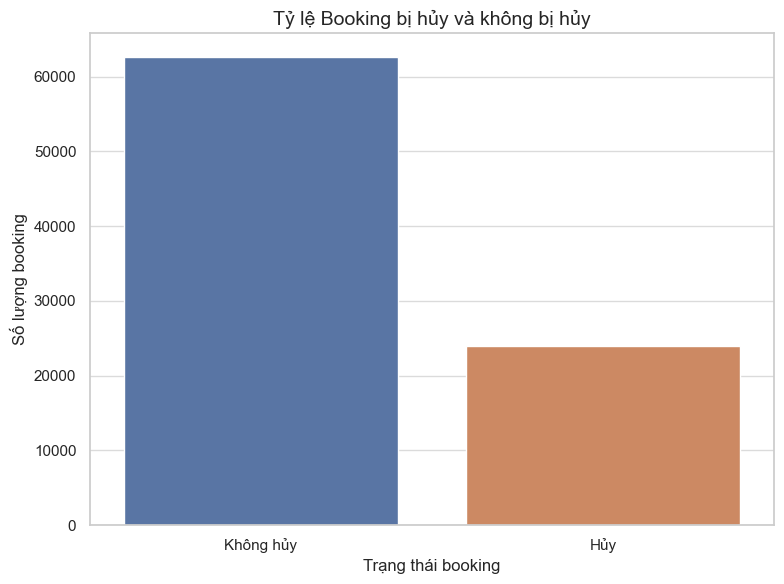


NHẬN XÉT BIỂU ĐỒ 1:
- Booking không bị hủy chiếm 72.31%.
- Booking bị hủy chiếm 27.69%.
- Biểu đồ cho thấy sự khác biệt về số lượng giữa hai trạng thái hủy và không hủy.


In [141]:
plt.figure(figsize=(8, 6))
sns.countplot(
    data=df,
    x="is_canceled",
    hue="is_canceled",
    legend=False
)
plt.title("Tỷ lệ Booking bị hủy và không bị hủy", fontsize=14)
plt.xlabel("Trạng thái booking")
plt.ylabel("Số lượng booking")
plt.xticks([0, 1], ["Không hủy", "Hủy"])
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "01_cancellation_overall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nNHẬN XÉT BIỂU ĐỒ 1:")
print(f"- Booking không bị hủy chiếm {not_cancelled:.2f}%.")
print(f"- Booking bị hủy chiếm {cancelled:.2f}%.")
print("- Biểu đồ cho thấy sự khác biệt về số lượng giữa hai trạng thái hủy và không hủy.")

## 2.5 TỶ LỆ HỦY THEO HOTEL

**Mục đích:** Mô tả tỷ lệ booking bị hủy và so sánh giữa các nhóm.

**Lý thuyết:** Vì `is_canceled` được mã hóa 0/1, trung bình của biến này bằng tỷ lệ giá trị 1; nhân 100 để biểu diễn theo phần trăm. Kết quả mô tả mối liên hệ, không chứng minh quan hệ nhân quả.


In [142]:
print("\n[4] TỶ LỆ HỦY THEO LOẠI KHÁCH SẠN")
hotel_cancellation = (
    df.groupby("hotel")["is_canceled"]
    .mean()
    .mul(100)
    .reset_index(name="cancellation_rate")
)
print(hotel_cancellation)


[4] TỶ LỆ HỦY THEO LOẠI KHÁCH SẠN
          hotel  cancellation_rate
0    City Hotel          30.204366
1  Resort Hotel          23.708732


## 2.6 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


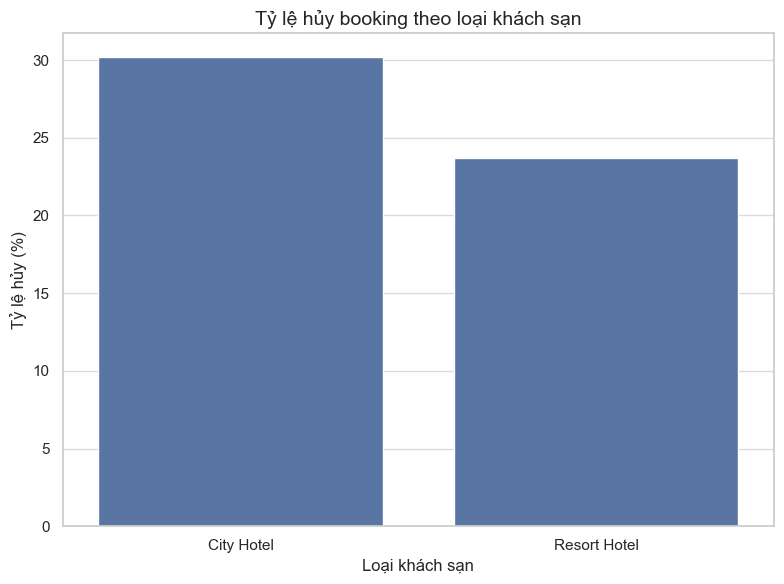


NHẬN XÉT BIỂU ĐỒ 2:
- City Hotel có tỷ lệ hủy 30.20%.
- Resort Hotel có tỷ lệ hủy 23.71%.
- Chênh lệch tỷ lệ hủy giữa hai loại khách sạn là 6.50 điểm phần trăm.


In [143]:
plt.figure(figsize=(8, 6))
sns.barplot(
    data=hotel_cancellation,
    x="hotel",
    y="cancellation_rate"
)
plt.title("Tỷ lệ hủy booking theo loại khách sạn", fontsize=14)
plt.xlabel("Loại khách sạn")
plt.ylabel("Tỷ lệ hủy (%)")
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "02_cancellation_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

hotel_max = hotel_cancellation.loc[hotel_cancellation["cancellation_rate"].idxmax()]
hotel_min = hotel_cancellation.loc[hotel_cancellation["cancellation_rate"].idxmin()]

print("\nNHẬN XÉT BIỂU ĐỒ 2:")
print(
    f"- {hotel_max['hotel']} có tỷ lệ hủy "
    f"{hotel_max['cancellation_rate']:.2f}%."
)

print(
    f"- {hotel_min['hotel']} có tỷ lệ hủy "
    f"{hotel_min['cancellation_rate']:.2f}%."
)

print(
    f"- Chênh lệch tỷ lệ hủy giữa hai loại khách sạn là "
    f"{hotel_max['cancellation_rate'] - hotel_min['cancellation_rate']:.2f} "
    "điểm phần trăm."
)

## 2.7 SỐ BOOKING THEO THÁNG

**Mục đích:** Khảo sát mức độ tập trung booking theo tháng đến.

**Cách thực hiện:** Đếm số bản ghi theo tháng và sắp xếp theo thứ tự lịch để nhận diện tháng có lượng booking cao/thấp.


In [144]:
print("\n[5] SỐ BOOKING THEO THÁNG")
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

monthly_bookings = (
    df["arrival_date_month"]
    .value_counts()
    .reindex(month_order)
)

print(monthly_bookings)


[5] SỐ BOOKING THEO THÁNG
arrival_date_month
January       4638
February      6029
March         7438
April         7870
May           8296
June          7721
July          9988
August       11194
September     6659
October       6842
November      4914
December      5044
Name: count, dtype: int64


## 2.8 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


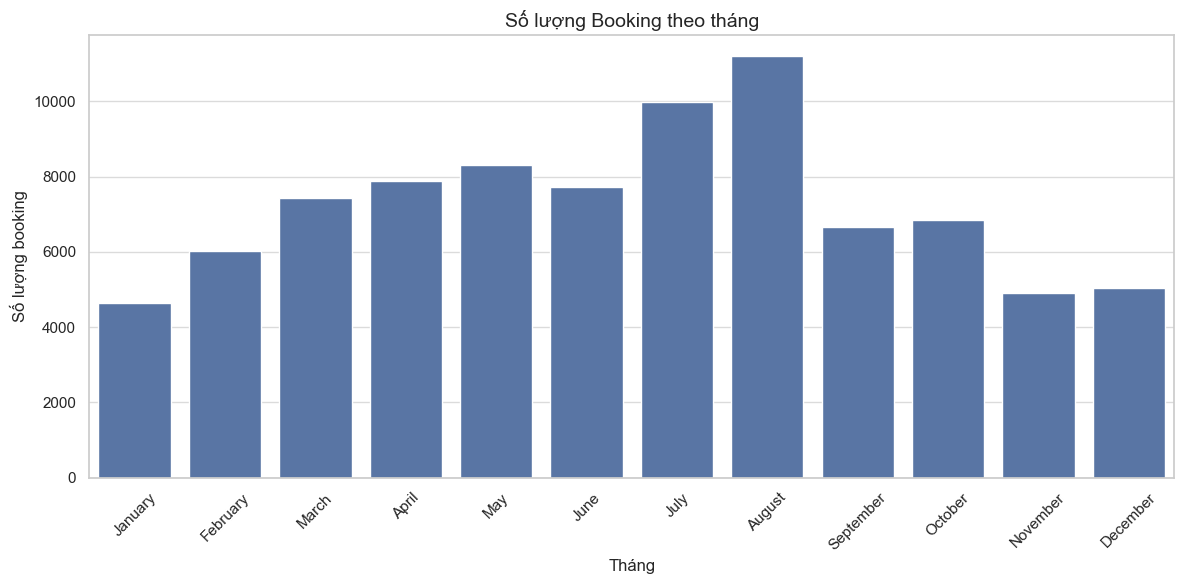


NHẬN XÉT BIỂU ĐỒ 3:
- Tháng có nhiều booking nhất: August (11,194 booking).
- Tháng có ít booking nhất: January (4,638 booking).


In [145]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=monthly_bookings.index,
    y=monthly_bookings.values
)

plt.title("Số lượng Booking theo tháng", fontsize=14)
plt.xlabel("Tháng")
plt.ylabel("Số lượng booking")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "03_bookings_by_month.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

peak_month = monthly_bookings.idxmax()
peak_value = monthly_bookings.max()

lowest_month = monthly_bookings.idxmin()
lowest_value = monthly_bookings.min()

print("\nNHẬN XÉT BIỂU ĐỒ 3:")
print(f"- Tháng có nhiều booking nhất: {peak_month} ({peak_value:,} booking).")
print(f"- Tháng có ít booking nhất: {lowest_month} ({lowest_value:,} booking).")

## 2.9 ADR THEO THÁNG VÀ HOTEL

**Mục đích:** So sánh ADR (Average Daily Rate – giá trung bình mỗi ngày) theo thời gian và loại khách sạn.

**Lý do:** Đường biểu diễn giúp quan sát xu hướng và khác biệt giữa các loại khách sạn; đây là mô tả theo nhóm, không tự khẳng định nguyên nhân.


In [146]:
print("\n[6] ADR TRUNG BÌNH THEO THÁNG VÀ HOTEL")
adr_by_month_hotel = (
    df.groupby(
        ["arrival_date_month", "hotel"],
        observed=True
    )["adr"]
    .mean()
    .reset_index()
)

# Sắp xếp tháng theo thứ tự thời gian
adr_by_month_hotel["arrival_date_month"] = pd.Categorical(
    adr_by_month_hotel["arrival_date_month"],
    categories=month_order,
    ordered=True
)

adr_by_month_hotel = adr_by_month_hotel.sort_values(
    "arrival_date_month"
)
print(adr_by_month_hotel)


[6] ADR TRUNG BÌNH THEO THÁNG VÀ HOTEL
   arrival_date_month         hotel         adr
8             January    City Hotel   85.837081
9             January  Resort Hotel   49.919928
6            February    City Hotel   90.069047
7            February  Resort Hotel   54.570526
15              March  Resort Hotel   58.229075
14              March    City Hotel   94.506791
0               April    City Hotel  117.541468
1               April  Resort Hotel   79.848504
17                May  Resort Hotel   81.520929
16                May    City Hotel  128.320970
13               June  Resort Hotel  113.367016
12               June    City Hotel  124.264334
11               July  Resort Hotel  157.425292
10               July    City Hotel  120.643441
3              August  Resort Hotel  188.335008
2              August    City Hotel  125.419297
22          September    City Hotel  119.180991
23          September  Resort Hotel  101.222854
20            October    City Hotel  108.594500


## 2.10 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


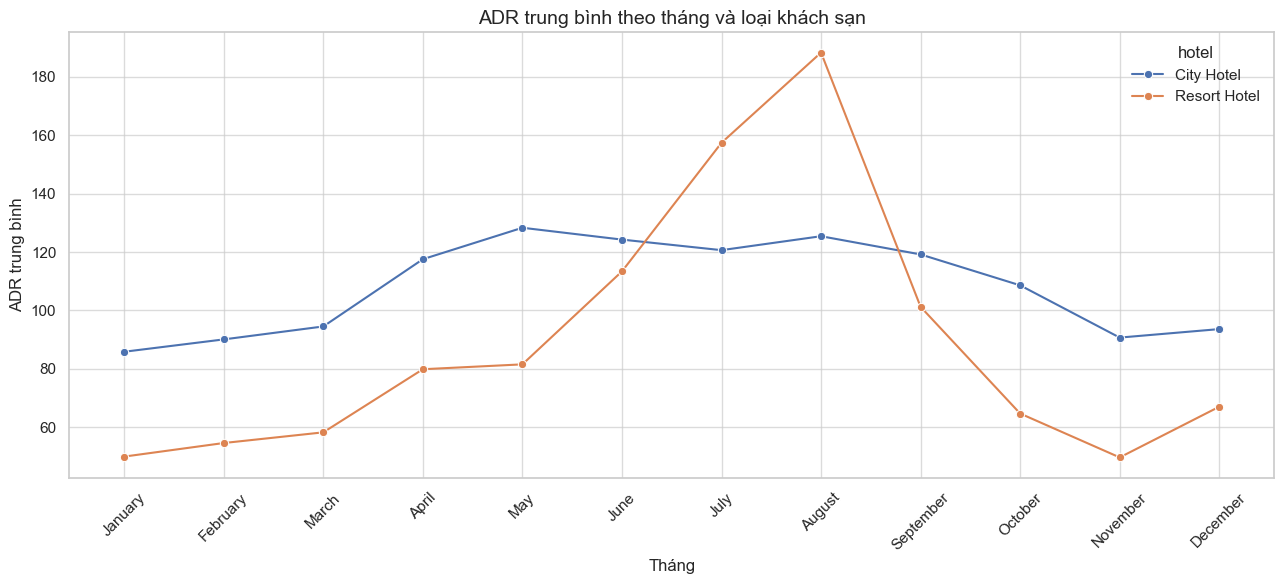


NHẬN XÉT BIỂU ĐỒ 4:
- ADR trung bình cao nhất thuộc về Resort Hotel vào August: 188.34.
- ADR trung bình thấp nhất thuộc về Resort Hotel vào November: 49.63.


In [147]:
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=adr_by_month_hotel,
    x="arrival_date_month",
    y="adr",
    hue="hotel",
    marker="o"
)
plt.title(
    "ADR trung bình theo tháng và loại khách sạn",
    fontsize=14
)

plt.xlabel("Tháng")
plt.ylabel("ADR trung bình")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "04_adr_by_month_hotel.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

adr_max = adr_by_month_hotel.loc[adr_by_month_hotel["adr"].idxmax()]
adr_min = adr_by_month_hotel.loc[adr_by_month_hotel["adr"].idxmin()]

print("\nNHẬN XÉT BIỂU ĐỒ 4:")
print(
    f"- ADR trung bình cao nhất thuộc về "
    f"{adr_max['hotel']} vào {adr_max['arrival_date_month']}: "
    f"{adr_max['adr']:.2f}."
)

print(
    f"- ADR trung bình thấp nhất thuộc về "
    f"{adr_min['hotel']} vào {adr_min['arrival_date_month']}: "
    f"{adr_min['adr']:.2f}."
)

## 2.11 PHÂN PHỐI CÁC BIẾN SỐ

**Mục đích:** Quan sát hình dạng phân phối của các biến số chính.

**Lý thuyết:** Histogram thể hiện tần suất theo khoảng giá trị; đường KDE là ước lượng mật độ làm mượt. So sánh mean và median chỉ gợi ý độ lệch, không thay thế việc xem hình phân phối.


In [148]:
print("\n[7] PHÂN PHỐI CÁC BIẾN SỐ")
numeric_columns = [
    "lead_time",
    "adr",
    "total_nights",
    "total_guests"
]

for column in numeric_columns:
    mean_value = df[column].mean()
    median_value = df[column].median()

    print(
        f"\n{column}: "
        f"Mean = {mean_value:.2f}, "
        f"Median = {median_value:.2f}, "
        f"Min = {df[column].min():.2f}, "
        f"Max = {df[column].max():.2f}"
    )


[7] PHÂN PHỐI CÁC BIẾN SỐ

lead_time: Mean = 80.22, Median = 50.00, Min = 0.00, Max = 468.00

adr: Mean = 107.14, Median = 99.00, Min = 0.00, Max = 319.06

total_nights: Mean = 3.62, Median = 3.00, Min = 1.00, Max = 14.00

total_guests: Mean = 2.03, Median = 2.00, Min = 1.00, Max = 55.00


## 2.12 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


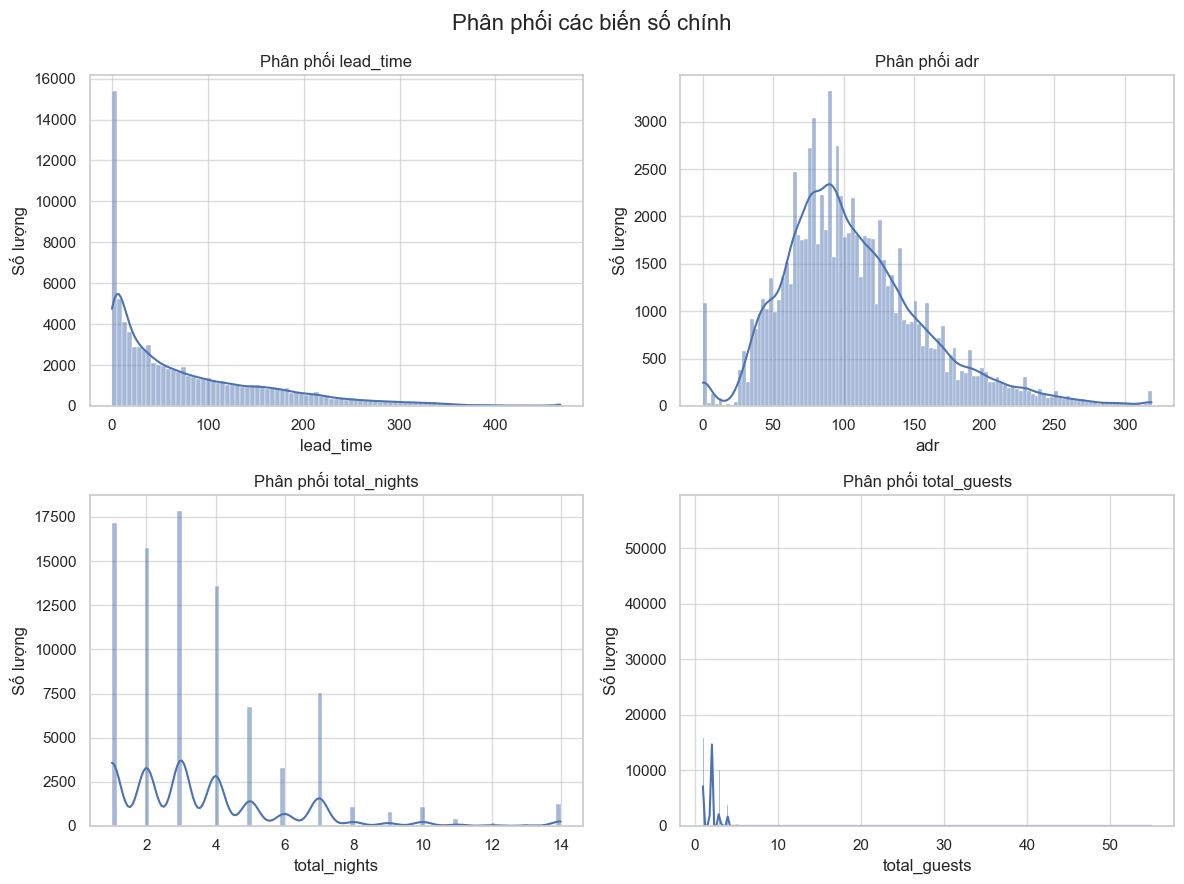


NHẬN XÉT BIỂU ĐỒ 5:
- lead_time: Mean lớn hơn Median, phân phối có xu hướng lệch phải.
- adr: Mean lớn hơn Median, phân phối có xu hướng lệch phải.
- total_nights: Mean lớn hơn Median, phân phối có xu hướng lệch phải.
- total_guests: Mean lớn hơn Median, phân phối có xu hướng lệch phải.


In [149]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)
for ax, column in zip(
    axes.flatten(),
    numeric_columns
):

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"Phân phối {column}"
    )

    ax.set_xlabel(column)
    ax.set_ylabel("Số lượng")

plt.suptitle(
    "Phân phối các biến số chính",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "05_numeric_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nNHẬN XÉT BIỂU ĐỒ 5:")
for column in numeric_columns:
    mean_value = df[column].mean()
    median_value = df[column].median()
    if mean_value > median_value:
        print(
            f"- {column}: Mean lớn hơn Median, "
            "phân phối có xu hướng lệch phải."
        )
    elif mean_value < median_value:
        print(
            f"- {column}: Mean nhỏ hơn Median, "
            "phân phối có xu hướng lệch trái."
        )
    else:
        print(
            f"- {column}: Mean và Median gần bằng nhau."
        )

## 2.13 TOP 10 QUỐC GIA

**Mục đích:** Xác định các quốc gia có số booking nhiều nhất.

**Cách thực hiện:** Đếm tần suất theo quốc gia và lấy 10 giá trị cao nhất; biểu đồ ngang giúp so sánh thứ hạng.


In [150]:
print("\n[8] TOP 10 QUỐC GIA")
top_countries = (
    df["country"]
    .value_counts()
    .head(10)
)
print(top_countries)


[8] TOP 10 QUỐC GIA
country
PRT    26859
GBR    10400
FRA     8813
ESP     7228
DEU     5385
ITA     3056
IRL     3014
BEL     2078
BRA     1988
NLD     1908
Name: count, dtype: int64


## 2.14 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


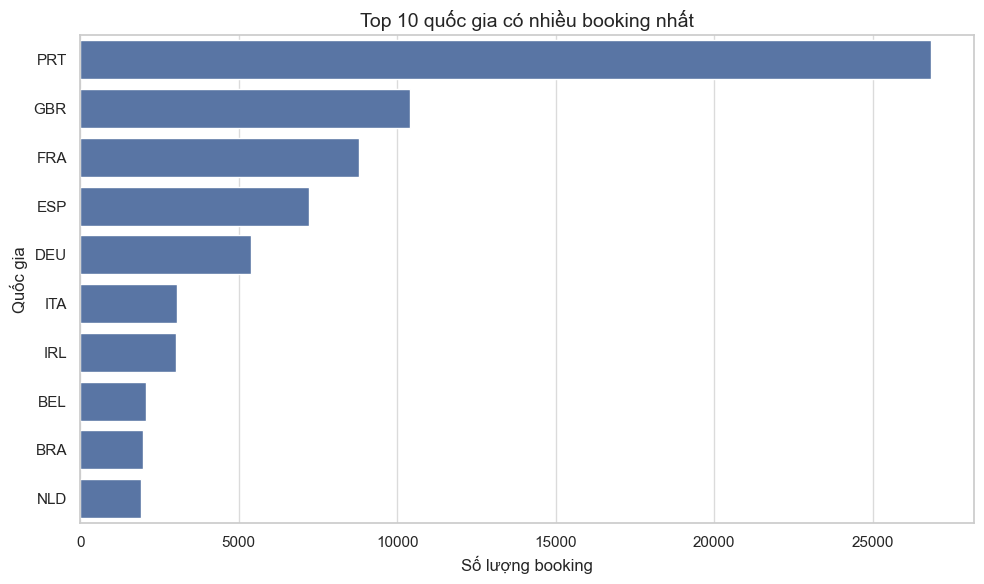


NHẬN XÉT BIỂU ĐỒ 6:
- Quốc gia có nhiều booking nhất là PRT với 26,859 booking.
- Số booking của PRT chiếm 31.00% tổng số booking.


In [151]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)
plt.title(
    "Top 10 quốc gia có nhiều booking nhất",
    fontsize=14
)
plt.xlabel("Số lượng booking")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "06_top10_countries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

top_country = top_countries.index[0]
top_country_count = top_countries.iloc[0]

top_country_percent = (
    top_country_count
    / len(df)
    * 100
)

print("\nNHẬN XÉT BIỂU ĐỒ 6:")
print(
    f"- Quốc gia có nhiều booking nhất là {top_country} "
    f"với {top_country_count:,} booking."
)

print(
    f"- Số booking của {top_country} chiếm "
    f"{top_country_percent:.2f}% tổng số booking."
)

## 2.15 MARKET SEGMENT VÀ TỶ LỆ HỦY

**Mục đích:** Mô tả tỷ lệ booking bị hủy và so sánh giữa các nhóm.

**Lý thuyết:** Vì `is_canceled` được mã hóa 0/1, trung bình của biến này bằng tỷ lệ giá trị 1; nhân 100 để biểu diễn theo phần trăm. Kết quả mô tả mối liên hệ, không chứng minh quan hệ nhân quả.


In [152]:
print("\n[9] TỶ LỆ HỦY THEO MARKET SEGMENT")
market_segment = (
    df.groupby("market_segment")
    .agg(
        booking_count=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reset_index()
)

market_segment["cancellation_rate"] *= 100
print(market_segment)


[9] TỶ LỆ HỦY THEO MARKET SEGMENT
  market_segment  booking_count  cancellation_rate
0       Aviation            222          19.819820
1  Complementary            682          12.170088
2      Corporate           4151          12.213924
3         Direct          11652          14.872983
4         Groups           4891          27.213249
5  Offline TA/TO          13748          14.947629
6      Online TA          51285          35.546456
7      Undefined              2         100.000000


## 2.16 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


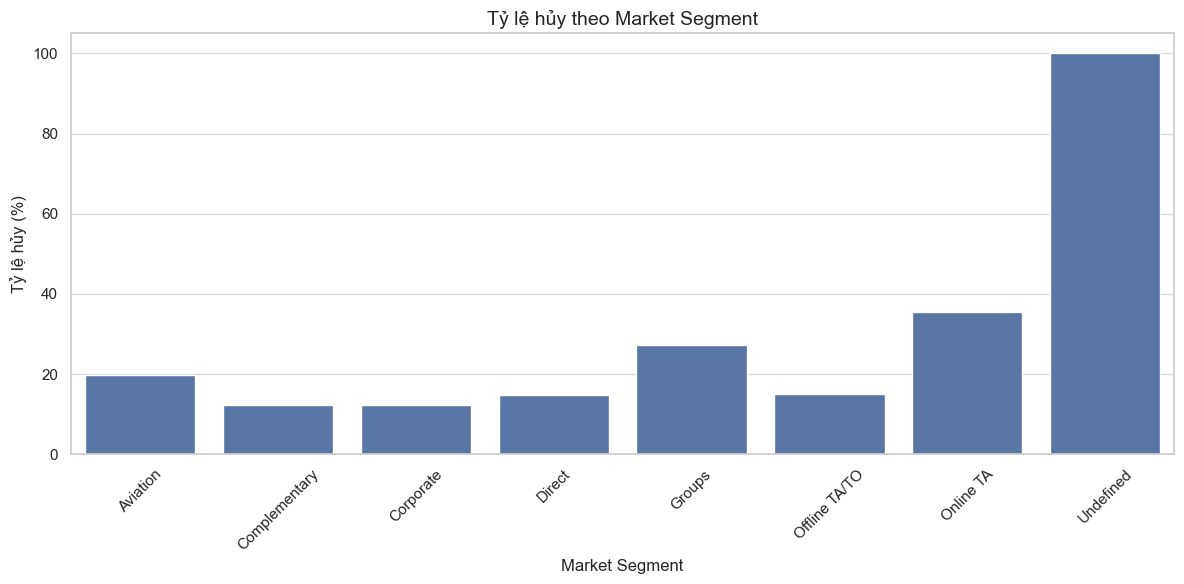


NHẬN XÉT BIỂU ĐỒ 7:
- Market Segment có tỷ lệ hủy cao nhất: Undefined (100.00%), với 2 booking.
- Market Segment có tỷ lệ hủy thấp nhất: Complementary (12.17%), với 682 booking.


In [153]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=market_segment,
    x="market_segment",
    y="cancellation_rate"
)
plt.title(
    "Tỷ lệ hủy theo Market Segment",
    fontsize=14
)
plt.xlabel("Market Segment")
plt.ylabel("Tỷ lệ hủy (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "07_market_segment_cancellation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

market_max = market_segment.loc[market_segment["cancellation_rate"].idxmax()]
market_min = market_segment.loc[market_segment["cancellation_rate"].idxmin()]

print("\nNHẬN XÉT BIỂU ĐỒ 7:")
print(
    f"- Market Segment có tỷ lệ hủy cao nhất: "
    f"{market_max['market_segment']} "
    f"({market_max['cancellation_rate']:.2f}%), "
    f"với {market_max['booking_count']:,} booking."
)

print(
    f"- Market Segment có tỷ lệ hủy thấp nhất: "
    f"{market_min['market_segment']} "
    f"({market_min['cancellation_rate']:.2f}%), "
    f"với {market_min['booking_count']:,} booking."
)

## 2.17 DEPOSIT TYPE VÀ TỶ LỆ HỦY

**Mục đích:** Mô tả tỷ lệ booking bị hủy và so sánh giữa các nhóm.

**Lý thuyết:** Vì `is_canceled` được mã hóa 0/1, trung bình của biến này bằng tỷ lệ giá trị 1; nhân 100 để biểu diễn theo phần trăm. Kết quả mô tả mối liên hệ, không chứng minh quan hệ nhân quả.


In [154]:
print("\n[10] TỶ LỆ HỦY THEO DEPOSIT TYPE")
deposit_type = (
    df.groupby("deposit_type")
    .agg(
        booking_count=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reset_index()
)

deposit_type["cancellation_rate"] *= 100
print(deposit_type)


[10] TỶ LỆ HỦY THEO DEPOSIT TYPE
  deposit_type  booking_count  cancellation_rate
0   No Deposit          85489          26.877142
1   Non Refund           1037          94.696239
2   Refundable            107          24.299065


## 2.18 Biểu đồ minh họa kết quả

**Mục đích:** Thực hiện bước phân tích tương ứng và tạo bảng/biểu đồ phục vụ diễn giải dữ liệu.

**Cách đọc kết quả:** Đối chiếu giá trị in ra với biểu đồ ngay bên dưới; nêu xu hướng nổi bật và lưu ý đây là phân tích mô tả.


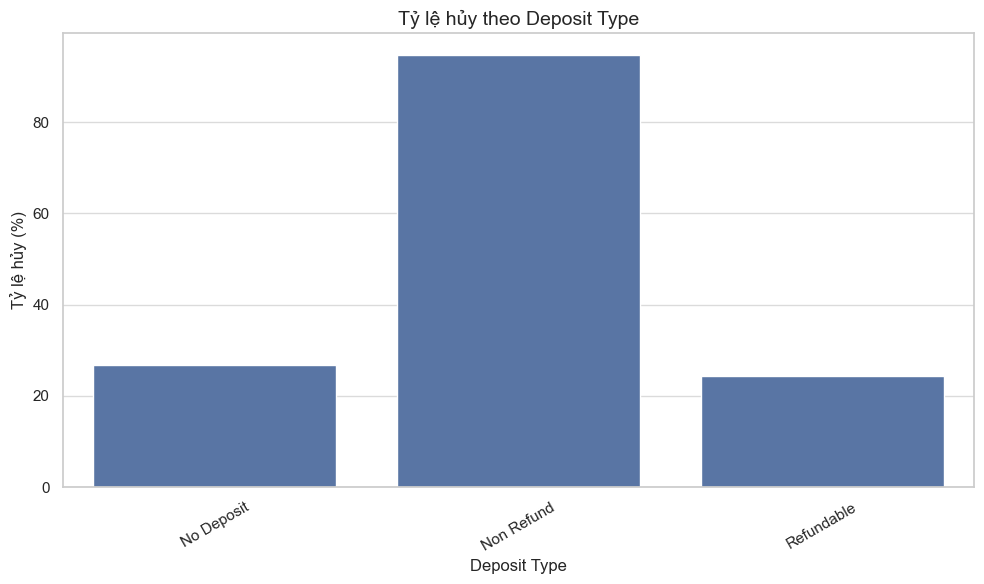


NHẬN XÉT BIỂU ĐỒ 8:
- Deposit Type có tỷ lệ hủy cao nhất: Non Refund (94.70%), với 1,037 booking.
- Deposit Type có tỷ lệ hủy thấp nhất: Refundable (24.30%), với 107 booking.


In [155]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=deposit_type,
    x="deposit_type",
    y="cancellation_rate"
)

plt.title(
    "Tỷ lệ hủy theo Deposit Type",
    fontsize=14
)
plt.xlabel("Deposit Type")
plt.ylabel("Tỷ lệ hủy (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    EDA_FIGURE_DIR / "08_deposit_type_cancellation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

deposit_max = deposit_type.loc[
    deposit_type["cancellation_rate"].idxmax()
]

deposit_min = deposit_type.loc[
    deposit_type["cancellation_rate"].idxmin()
]

print("\nNHẬN XÉT BIỂU ĐỒ 8:")
print(
    f"- Deposit Type có tỷ lệ hủy cao nhất: "
    f"{deposit_max['deposit_type']} "
    f"({deposit_max['cancellation_rate']:.2f}%), "
    f"với {deposit_max['booking_count']:,} booking."
)

print(
    f"- Deposit Type có tỷ lệ hủy thấp nhất: "
    f"{deposit_min['deposit_type']} "
    f"({deposit_min['cancellation_rate']:.2f}%), "
    f"với {deposit_min['booking_count']:,} booking."
)

## 2.19 KẾT LUẬN EDA

**Mục đích:** Tổng hợp các thay đổi chính và kiểm tra đầu ra của quy trình.

Các con số được in ra sau khi chạy notebook sẽ phản ánh dữ liệu thực tế; không nên điền trước kết quả khi chưa chạy với file dữ liệu đầu vào.


In [156]:
print("\n" + "=" * 70)
print("KẾT LUẬN EDA")
print("=" * 70)
print(f"- Dataset sau cleaning có {len(df):,} booking.")
print(f"- Tỷ lệ booking bị hủy: {cancelled:.2f}%.")
print(f"- Tỷ lệ booking không bị hủy: {not_cancelled:.2f}%.")
print(f"- Tháng có nhiều booking nhất: {peak_month} ({peak_value:,} booking).")
print(f"- Tháng có ít booking nhất: {lowest_month} ({lowest_value:,} booking).")
print(f"- Quốc gia có nhiều booking nhất: {top_country} ({top_country_count:,} booking).")
print("\nCác nhận xét trên là mô tả từ dữ liệu và không khẳng định quan hệ nhân quả.")
print("\nCác biểu đồ đã được lưu tại:")
print(EDA_FIGURE_DIR)

print("=" * 70)


KẾT LUẬN EDA
- Dataset sau cleaning có 86,633 booking.
- Tỷ lệ booking bị hủy: 27.69%.
- Tỷ lệ booking không bị hủy: 72.31%.
- Tháng có nhiều booking nhất: August (11,194 booking).
- Tháng có ít booking nhất: January (4,638 booking).
- Quốc gia có nhiều booking nhất: PRT (26,859 booking).

Các nhận xét trên là mô tả từ dữ liệu và không khẳng định quan hệ nhân quả.

Các biểu đồ đã được lưu tại:
C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\eda


# 3. Phân tích phân phối xác suất



In [157]:

if sys.platform.startswith("win"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
        sys.stderr.reconfigure(encoding="utf-8")
    except Exception:
        pass

## 3.1 Cấu hình phân tích

Mức ý nghĩa thống kê được chọn là **α = 0,05**. Ba biến được chọn đại diện cho giá phòng, thời gian đặt trước và số yêu cầu đặc biệt. Đường dẫn dữ liệu được dùng chung từ phần cấu hình đầu notebook.


In [158]:
# Tham số phân tích phân phối xác suất
ALPHA = 0.05
TARGET_VARS = ["adr", "lead_time", "total_of_special_requests"]

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.family": "sans-serif",
    "axes.edgecolor": "#cccccc",
    "axes.linewidth": 0.8,
    "grid.color": "#ebebeb",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "figure.titlesize": 13,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

print(f"File dữ liệu được chọn: {CLEANED_PATH}")
print(f"Thư mục lưu kết quả: {RESULTS_DIR}")

File dữ liệu được chọn: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\data\processed\hotel_bookings_cleaned.csv
Thư mục lưu kết quả: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results


## 3.2 Đọc và kiểm tra dữ liệu

**Mục đích:** bảo đảm file có tồn tại, có đủ ba biến cần phân tích và xác định số giá trị thiếu, số dòng trùng lặp.

**Cách thực hiện:** giữ các dòng có đủ dữ liệu ở ba biến mục tiêu và giá trị không âm. Số dòng trùng lặp được báo cáo để đối chiếu với bước làm sạch dữ liệu chung; hàm này không tự ý xóa trùng lặp.


In [159]:
def load_and_validate_data(file_path):
    """Đọc dữ liệu, kiểm tra tính hợp lệ và in bảng data validation."""
    if not file_path.exists():
        raise FileNotFoundError(f"Không tìm thấy file dữ liệu tại {file_path}")

    df = pd.read_csv(file_path)
    init_rows, init_cols = df.shape
    if init_rows == 0:
        raise ValueError("File dữ liệu rỗng (0 dòng).")

    missing_vars = [c for c in TARGET_VARS if c not in df.columns]
    if missing_vars:
        raise KeyError(f"Thiếu các cột cần thiết trong dataset: {missing_vars}")

    # Duplicate được kiểm tra để báo cáo; việc loại bỏ duplicate đã thực hiện ở bước EDA chung (TV1)
    total_missing_target = int(df[TARGET_VARS].isna().sum().sum())
    dup_count = int(df.duplicated().sum())
    valid_mask = (
        df["adr"].notna() & df["lead_time"].notna() & df["total_of_special_requests"].notna()
        & (df["adr"] >= 0) & (df["lead_time"] >= 0) & (df["total_of_special_requests"] >= 0)
    )
    clean_df = df[valid_mask].copy()

    print("DATA VALIDATION")
    print(f"Rows:                   {init_rows:,}")
    print(f"Columns:                {init_cols}")
    print(f"Missing (3 biến chính): {total_missing_target}")
    print(f"Duplicates:             {dup_count:,}")
    print(f"Rows used for analysis: {len(clean_df):,}")

    return clean_df

In [160]:
clean_df = load_and_validate_data(CLEANED_PATH)
clean_df.head()

DATA VALIDATION
Rows:                   86,633
Columns:                38
Missing (3 biến chính): 0
Duplicates:             0
Rows used for analysis: 86,633


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,agent_was_missing,children_was_missing,country_was_missing,has_company,total_guests,total_nights,arrival_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,0,0,0,1,1,2015-07-01
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,0,0,0,1,1,2015-07-01
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,0,0,0,2,2,2015-07-01
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,0.0,0,Transient,107.0,0,0,Check-Out,2015-07-03,1,0,0,0,2,2,2015-07-01
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,0,Transient,103.0,0,1,Check-Out,2015-07-03,0,0,0,0,2,2,2015-07-01


## 3.3 Thống kê mô tả và phát hiện ngoại lai

**Lý thuyết:** Mean và Median mô tả vị trí trung tâm; độ lệch chuẩn và phương sai mô tả mức phân tán. IQR = Q3 − Q1. Các giá trị nhỏ hơn Q1 − 1,5×IQR hoặc lớn hơn Q3 + 1,5×IQR được đánh dấu là **ngoại lai tiềm năng**.

**Lưu ý:** ngoại lai tiềm năng không nhất thiết là dữ liệu sai, nên không tự động loại bỏ chỉ dựa vào quy tắc IQR.


In [161]:
def calculate_descriptive_stats(series, var_name):
    """Tính 12 chỉ số thống kê mô tả kèm IQR bounds và số lượng outlier tiềm năng."""
    s = series.dropna()
    q1, q3 = float(s.quantile(0.25)), float(s.quantile(0.75))
    iqr = q3 - q1
    lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = int(((s < lower_bound) | (s > upper_bound)).sum())

    return {
        "Variable": var_name,
        "Count": int(len(s)),
        "Mean": float(s.mean()),
        "Median": float(s.median()),
        "Std": float(s.std()),
        "Variance": float(s.var()),
        "Min": float(s.min()),
        "Q1": q1,
        "Q3": q3,
        "Max": float(s.max()),
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Potential_Outliers": outliers,
        "Skewness": float(s.skew()),
        "Kurtosis": float(s.kurtosis()),
    }

## 3.4 Hàm hỗ trợ vẽ Q-Q Plot

Q-Q Plot so sánh các phân vị của dữ liệu quan sát với các phân vị lý thuyết. Điểm càng gần đường tham chiếu thì dữ liệu càng gần phân phối được so sánh; độ cong hoặc lệch có hệ thống là dấu hiệu khác biệt.


In [162]:
def plot_qq(ax, series, dist="norm", color="#2b5c8f", title="Q-Q Plot"):
    """Vẽ Q-Q plot và đường chuẩn lý thuyết."""
    (osm, osr), (slope, intercept, _) = stats.probplot(series.dropna(), dist=dist)
    ax.scatter(osm, osr, color=color, alpha=0.25, s=6, edgecolors="none", label="Quan sát")
    ax.plot(osm, slope * osm + intercept, color="#d9534f", linewidth=1.8, label="Đường chuẩn lý thuyết")
    ax.set_title(title, pad=8)
    ax.set_xlabel("Phân vị lý thuyết")
    ax.set_ylabel("Phân vị mẫu")
    ax.legend(loc="lower right")

## 3.5 Phân tích ADR – Normal và Log-Normal

**Mục đích:** đánh giá xem ADR gốc có gần phân phối Normal không và xem log(ADR) có gần Normal không. Nếu log(ADR) gần Normal thì đó là cơ sở xem xét giả định ADR có phân phối Log-Normal.

**Phương pháp:** dùng Histogram/KDE, Boxplot, Q-Q Plot và kiểm định D’Agostino K². Với kiểm định này, H₀ giả định dữ liệu phù hợp với Normal; p-value < 0,05 là bằng chứng bác bỏ H₀. Các giá trị ADR bằng 0 không thể log-transform nên được loại khỏi riêng phần phân tích log.

**Đọc kết quả:** xem hình dạng biểu đồ và p-value cùng nhau. p-value ≥ 0,05 không chứng minh phân phối hoàn toàn đúng.


In [163]:
def analyze_adr(df):
    """Phân tích biến liên tục ADR: Normal, Log-transform và đánh giá Log-Normal."""
    s_adr = df["adr"].dropna()
    desc = calculate_descriptive_stats(s_adr, "adr")

    # Kiểm định Normal trên ADR gốc
    k2_adr, p_k2_adr = stats.normaltest(s_adr)
    dec_norm = "Reject H0" if p_k2_adr < ALPHA else "Fail to reject H0"
    adr_norm_assessment = "Có bằng chứng dữ liệu không tuân theo Normal" if p_k2_adr < ALPHA else "Chưa có đủ bằng chứng bác bỏ Normal"

    # Log-transform đối với các giá trị dương ADR > 0
    adr_pos = s_adr[s_adr > 0]
    log_adr = np.log(adr_pos)
    k2_log, p_k2_log = stats.normaltest(log_adr)
    dec_log = "Reject H0" if p_k2_log < ALPHA else "Fail to reject H0"
    skew_log = float(log_adr.skew())

    if p_k2_log < ALPHA:
        assess_log = "Không tuân theo Normal; log-transform giảm độ lệch nhưng chưa đủ bằng chứng xác nhận Log-Normal"
        stat_conclusion = (
            f"D'Agostino K² trên log(ADR) có p = {p_k2_log:.4g} < {ALPHA} ({dec_log}). "
            f"Log-transform giúp giảm skewness từ {desc['Skewness']:.2f} xuống {skew_log:.2f}, "
            "tuy nhiên bằng chứng thống kê chưa đủ để xác nhận ADR tuân theo Log-Normal."
        )
    else:
        assess_log = "Chưa có đủ bằng chứng bác bỏ giả định Log-Normal trong phạm vi mẫu"
        stat_conclusion = (
            f"D'Agostino K² trên log(ADR) có p = {p_k2_log:.4g} >= {ALPHA} ({dec_log}). "
            "Chưa bác bỏ H0; kết quả chưa cung cấp đủ bằng chứng để bác bỏ giả định Log-Normal trong phạm vi mẫu."
        )

    mean_med_rel = "lớn hơn median, cho thấy dấu hiệu lệch phải" if desc["Mean"] > desc["Median"] else "nhỏ hơn median, cho thấy dấu hiệu lệch trái"
    skew_rel = "giảm rõ rệt độ lệch" if abs(skew_log) < abs(desc["Skewness"]) else "không làm giảm độ lệch"
    norm_comment = "kiểm định bác bỏ giả thuyết Normality" if p_k2_adr < ALPHA else "kiểm định chưa đủ bằng chứng bác bỏ giả thuyết Normality"

    basic_comment = (
        f"ADR có mean ({desc['Mean']:.2f}) {mean_med_rel} (Skewness = {desc['Skewness']:.2f}). "
        f"Theo quy tắc IQR, có {desc['Potential_Outliers']:,} giá trị có khả năng là ngoại lai. "
        f"Q-Q plot được sử dụng để đánh giá mức độ lệch khỏi Normal; {norm_comment} (p = {p_k2_adr:.4g}). "
        f"Phép biến đổi log(ADR) giúp {skew_rel} (Skewness sau log = {skew_log:.2f}), "
        f"tuy nhiên kiểm định normality trên log(ADR) {dec_log.lower()} (p = {p_k2_log:.4g})."
    )

    # Biểu đồ ADR
    fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
    fig.suptitle("Hình 1: Phân tích Phân phối Xác suất Biến adr (Average Daily Rate)", fontsize=13, fontweight="bold", y=0.98)

    sns.histplot(s_adr, bins=40, kde=True, color="#2b5c8f", ax=axes[0, 0], stat="density", alpha=0.6)
    axes[0, 0].axvline(desc["Mean"], color="#d9534f", linestyle="--", linewidth=1.8, label=f"Mean: {desc['Mean']:.1f}")
    axes[0, 0].axvline(desc["Median"], color="#2ca02c", linestyle="-", linewidth=1.8, label=f"Median: {desc['Median']:.1f}")
    axes[0, 0].set_title("A. Histogram & KDE (ADR gốc)", pad=8)
    axes[0, 0].set_xlabel("ADR")
    axes[0, 0].set_ylabel("Mật độ xác suất")
    axes[0, 0].legend()

    sns.boxplot(x=s_adr, color="#6baed6", ax=axes[0, 1], flierprops={"marker": "o", "markersize": 3, "alpha": 0.3})
    axes[0, 1].set_title(f"B. Boxplot (IQR = {desc['IQR']:.1f})", pad=8)
    axes[0, 1].set_xlabel("ADR")

    plot_qq(axes[0, 2], s_adr, dist="norm", color="#2b5c8f", title="C. Q-Q Plot so với Normal (ADR gốc)")

    sns.histplot(log_adr, bins=40, kde=True, color="#238b45", ax=axes[1, 0], stat="density", alpha=0.6)
    x_axis = np.linspace(log_adr.min(), log_adr.max(), 200)
    axes[1, 0].plot(x_axis, stats.norm.pdf(x_axis, log_adr.mean(), log_adr.std()), color="#d9534f", linestyle="--", linewidth=2, label="Fit Normal")
    axes[1, 0].set_title(f"D. log(ADR) Histogram & KDE (Skew = {skew_log:.2f})", pad=8)
    axes[1, 0].set_xlabel("log(ADR)")
    axes[1, 0].set_ylabel("Mật độ xác suất")
    axes[1, 0].legend()

    plot_qq(axes[1, 1], log_adr, dist="norm", color="#238b45", title="E. Q-Q Plot so với Normal của log(ADR)")

    axes[1, 2].axis("off")
    summary_text = (
        f"TÓM TẮT THỐNG KÊ ADR:\n"
        f"• Quan sát: {desc['Count']:,}\n"
        f"• Mean: {desc['Mean']:.2f} | Median: {desc['Median']:.2f}\n"
        f"• Std: {desc['Std']:.2f} | IQR: {desc['IQR']:.2f}\n"
        f"• Ngưỡng ngoại lai: [{desc['Lower_Bound']:.1f}, {desc['Upper_Bound']:.1f}]\n"
        f"• Điểm ngoại lai tiềm năng: {desc['Potential_Outliers']:,}\n"
        f"• Skewness gốc: {desc['Skewness']:.2f} -> log(ADR): {skew_log:.2f}\n\n"
        f"KIỂM ĐỊNH NORMAL (D'Agostino K²):\n"
        f"• ADR gốc: K² = {k2_adr:.2f}, p = {p_k2_adr:.4g} -> {dec_norm}\n"
        f"• log(ADR): K² = {k2_log:.2f}, p = {p_k2_log:.4g} -> {dec_log}\n\n"
        f"ĐÁNH GIÁ:\n{assess_log}"
    )
    axes[1, 2].text(0.05, 0.5, summary_text, fontsize=9.2, va="center", bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc"))

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(PROB_FIGURE_DIR / "dist_01_adr_analysis.png", dpi=300, bbox_inches="tight")
    plt.close()

    test_rows = [
        {"Variable": "adr", "Distribution": "Normal", "Test": "D'Agostino's K² Test", "Statistic": float(k2_adr), "P_Value": float(p_k2_adr), "Alpha": ALPHA, "Decision": dec_norm, "Conclusion": f"K² = {k2_adr:.2f}, p = {p_k2_adr:.4g}. {dec_norm} phân phối chuẩn."},
        {"Variable": "adr", "Distribution": "Log-Normal", "Test": "D'Agostino's K² Test on log(ADR)", "Statistic": float(k2_log), "P_Value": float(p_k2_log), "Alpha": ALPHA, "Decision": dec_log, "Conclusion": stat_conclusion}
    ]

    interp_rows = [
        {"Variable": "adr", "Data_Type": "Continuous numerical", "Count": desc["Count"], "Mean": desc["Mean"], "Median": desc["Median"], "Variance": desc["Variance"], "Std": desc["Std"], "Skewness": desc["Skewness"], "Kurtosis": desc["Kurtosis"], "Distribution_Candidate": "Normal Distribution", "Test_Name": "D'Agostino's K² Test", "Test_Statistic": float(k2_adr), "P_Value": float(p_k2_adr), "Decision": dec_norm, "Distribution_Assessment": adr_norm_assessment, "Basic_Comment": basic_comment},
        {"Variable": "adr (log-transformed)", "Data_Type": "Continuous numerical", "Count": int(len(adr_pos)), "Mean": float(log_adr.mean()), "Median": float(log_adr.median()), "Variance": float(log_adr.var()), "Std": float(log_adr.std()), "Skewness": skew_log, "Kurtosis": float(log_adr.kurtosis()), "Distribution_Candidate": "Log-Normal Distribution", "Test_Name": "D'Agostino's K² Test on log(ADR)", "Test_Statistic": float(k2_log), "P_Value": float(p_k2_log), "Decision": dec_log, "Distribution_Assessment": assess_log, "Basic_Comment": basic_comment}
    ]

    summary_info = {
        "mean": desc["Mean"], "median": desc["Median"], "skewness": desc["Skewness"],
        "norm_p": p_k2_adr, "log_p": p_k2_log, "assessment": assess_log, "conclusion": stat_conclusion
    }

    return desc, test_rows, interp_rows, summary_info

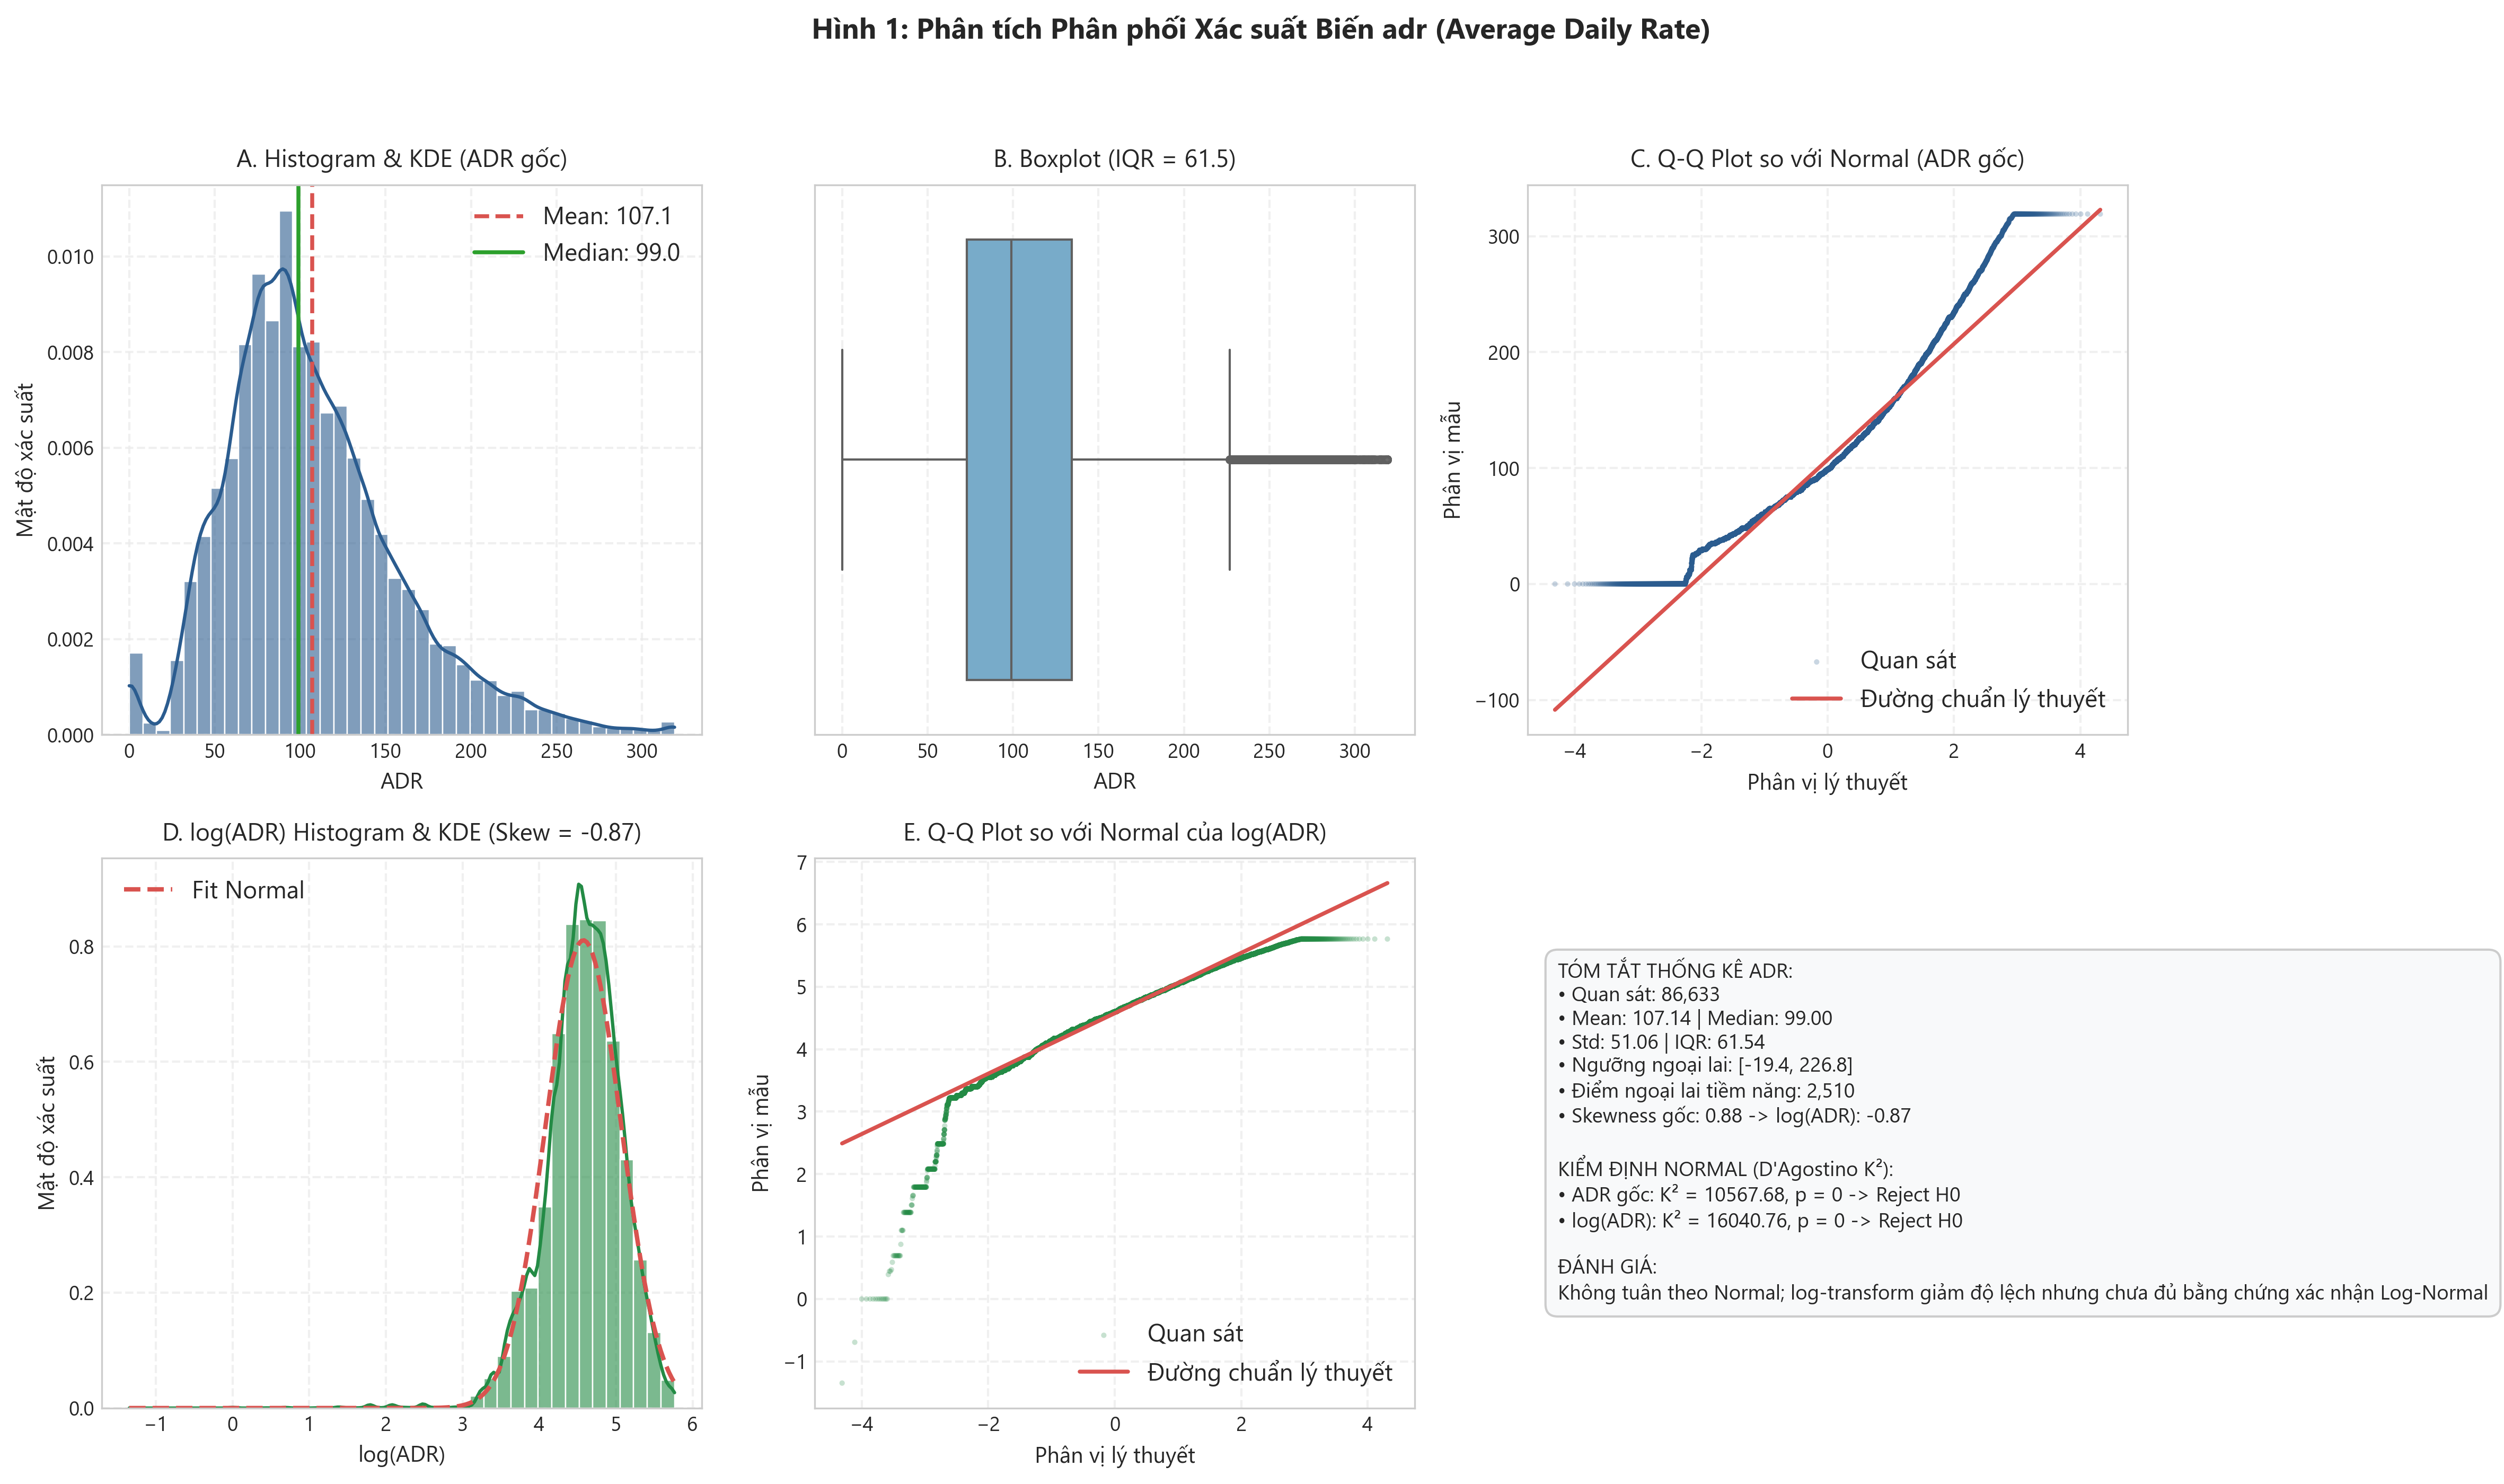


### Nhận xét ADR

- Mean: 107.14.
- Median: 99.00.
- Skewness: 0.88.
- p-value Normal: 0.
- p-value log(ADR): 0.

**Đánh giá:** Không tuân theo Normal; log-transform giảm độ lệch nhưng chưa đủ bằng chứng xác nhận Log-Normal

**Kết luận kiểm định:** D'Agostino K² trên log(ADR) có p = 0 < 0.05 (Reject H0). Log-transform giúp giảm skewness từ 0.88 xuống -0.87, tuy nhiên bằng chứng thống kê chưa đủ để xác nhận ADR tuân theo Log-Normal.


In [164]:
adr_desc, adr_tests, adr_interps, adr_summary = analyze_adr(clean_df)
adr_figure = PROB_FIGURE_DIR / "dist_01_adr_analysis.png"
display(Image(filename=str(adr_figure)))
pd.DataFrame(adr_tests)
display(Markdown(f"""
### Nhận xét ADR

- Mean: {adr_summary['mean']:.2f}.
- Median: {adr_summary['median']:.2f}.
- Skewness: {adr_summary['skewness']:.2f}.
- p-value Normal: {adr_summary['norm_p']:.4g}.
- p-value log(ADR): {adr_summary['log_p']:.4g}.

**Đánh giá:** {adr_summary['assessment']}

**Kết luận kiểm định:** {adr_summary['conclusion']}
"""))

## 3.6 Phân tích Lead Time – Exponential

**Lý thuyết:** phân phối Exponential thường mô tả thời gian chờ liên tục không âm. Tham số tỷ lệ được ước lượng bằng λ = 1/Mean (tương đương scale = Mean).

**Cách đánh giá:** Histogram/KDE được so sánh với đường mật độ Exponential; Boxplot cho thấy độ phân tán và ngoại lai tiềm năng. Kiểm định Kolmogorov–Smirnov (KS) được dùng như chỉ báo bổ sung. Vì tham số được ước lượng từ chính mẫu, p-value KS thông thường cần được diễn giải thận trọng.


In [165]:
def analyze_lead_time(df):
    """Phân tích biến duration lead_time: kiểm tra độ lệch và đánh giá Exponential."""
    s_lt = df["lead_time"].dropna()
    desc = calculate_descriptive_stats(s_lt, "lead_time")

    scale_hat = desc["Mean"]
    lambda_hat = 1.0 / scale_hat if scale_hat > 0 else 0.0

    # KS-test với scale ước lượng từ mẫu
    ks_stat, ks_p = stats.kstest(s_lt, "expon", args=(0, scale_hat))
    dec_ks = "Reject H0" if ks_p < ALPHA else "Fail to reject H0"

    if ks_p < ALPHA:
        assess_lt = "Không phù hợp với Exponential lý thuyết (dù có dạng suy giảm)"
        stat_conclusion = (
            f"Reject H0: KS statistic = {ks_stat:.4f}, p = {ks_p:.4g} < {ALPHA}. "
            "Có bằng chứng dữ liệu không phù hợp với phân phối Exponential lý thuyết. "
            "(Tham số được ước lượng từ mẫu, vì vậy p-value KS thông thường cần được diễn giải thận trọng)."
        )
    else:
        assess_lt = "Chưa đủ bằng chứng bác bỏ Exponential"
        stat_conclusion = (
            f"Fail to reject H0: KS statistic = {ks_stat:.4f}, p = {ks_p:.4g} >= {ALPHA}. "
            "Chưa có đủ bằng chứng cho thấy dữ liệu không phù hợp với Exponential. "
            "Đây không phải là bằng chứng chứng minh dữ liệu chắc chắn tuân theo Exponential."
        )

    mean_med_rel = "lớn hơn median rõ rệt, cho thấy đuôi dài kéo sang phải" if desc["Mean"] > desc["Median"] else "nhỏ hơn median"
    basic_comment = (
        f"lead_time có mean ({desc['Mean']:.1f} ngày) {mean_med_rel} (Skewness = {desc['Skewness']:.2f}). "
        f"Khoảng IQR = {desc['IQR']:.1f} ngày với {desc['Potential_Outliers']:,} giá trị có khả năng là ngoại lai theo IQR. "
        f"Q-Q plot được dùng để đánh giá mức độ lệch khỏi Normal. "
        f"KS test đánh giá phân phối Exponential cho kết quả: {dec_ks} (D = {ks_stat:.4f}, p = {ks_p:.4g})."
    )

    # Biểu đồ lead_time
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    fig.suptitle("Hình 2: Phân tích Phân phối Xác suất Biến lead_time", fontsize=13, fontweight="bold", y=0.98)

    sns.histplot(s_lt, bins=45, kde=True, color="#e6550d", ax=axes[0], stat="density", alpha=0.5, label="Thực tế (KDE)")
    x_axis = np.linspace(0, s_lt.max(), 300)
    axes[0].plot(x_axis, stats.expon.pdf(x_axis, scale=scale_hat), color="#3182bd", linewidth=2, label=f"Exponential fit (λ={lambda_hat:.4f})")
    axes[0].axvline(desc["Mean"], color="#d9534f", linestyle="--", linewidth=1.8, label=f"Mean: {desc['Mean']:.1f}")
    axes[0].axvline(desc["Median"], color="#2ca02c", linestyle="-", linewidth=1.8, label=f"Median: {desc['Median']:.1f}")
    axes[0].set_title(f"A. Histogram, KDE & Exponential Fit (λ={lambda_hat:.4f})", pad=8)
    axes[0].set_xlabel("lead_time (ngày)")
    axes[0].set_ylabel("Mật độ xác suất")
    axes[0].legend()

    sns.boxplot(x=s_lt, color="#fdae6b", ax=axes[1], flierprops={"marker": "o", "markersize": 3, "alpha": 0.3})
    axes[1].set_title(f"B. Boxplot (IQR = {desc['IQR']:.1f})", pad=8)
    axes[1].set_xlabel("lead_time (ngày)")

    plot_qq(axes[2], s_lt, dist="norm", color="#e6550d", title="C. Q-Q Plot so với Normal")

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(PROB_FIGURE_DIR / "dist_02_lead_time_analysis.png", dpi=300, bbox_inches="tight")
    plt.close()

    test_rows = [
        {"Variable": "lead_time", "Distribution": "Exponential", "Test": "Kolmogorov-Smirnov Test (Estimated Scale)", "Statistic": float(ks_stat), "P_Value": float(ks_p), "Alpha": ALPHA, "Decision": dec_ks, "Conclusion": stat_conclusion}
    ]

    interp_rows = [
        {"Variable": "lead_time", "Data_Type": "Duration / count-like", "Count": desc["Count"], "Mean": desc["Mean"], "Median": desc["Median"], "Variance": desc["Variance"], "Std": desc["Std"], "Skewness": desc["Skewness"], "Kurtosis": desc["Kurtosis"], "Distribution_Candidate": "Exponential Distribution", "Test_Name": "Kolmogorov-Smirnov Test", "Test_Statistic": float(ks_stat), "P_Value": float(ks_p), "Decision": dec_ks, "Distribution_Assessment": assess_lt, "Basic_Comment": basic_comment}
    ]

    summary_info = {
        "mean": desc["Mean"], "median": desc["Median"], "skewness": desc["Skewness"],
        "lambda": lambda_hat, "ks_stat": ks_stat, "ks_p": ks_p, "assessment": assess_lt, "conclusion": stat_conclusion
    }

    return desc, test_rows, interp_rows, summary_info

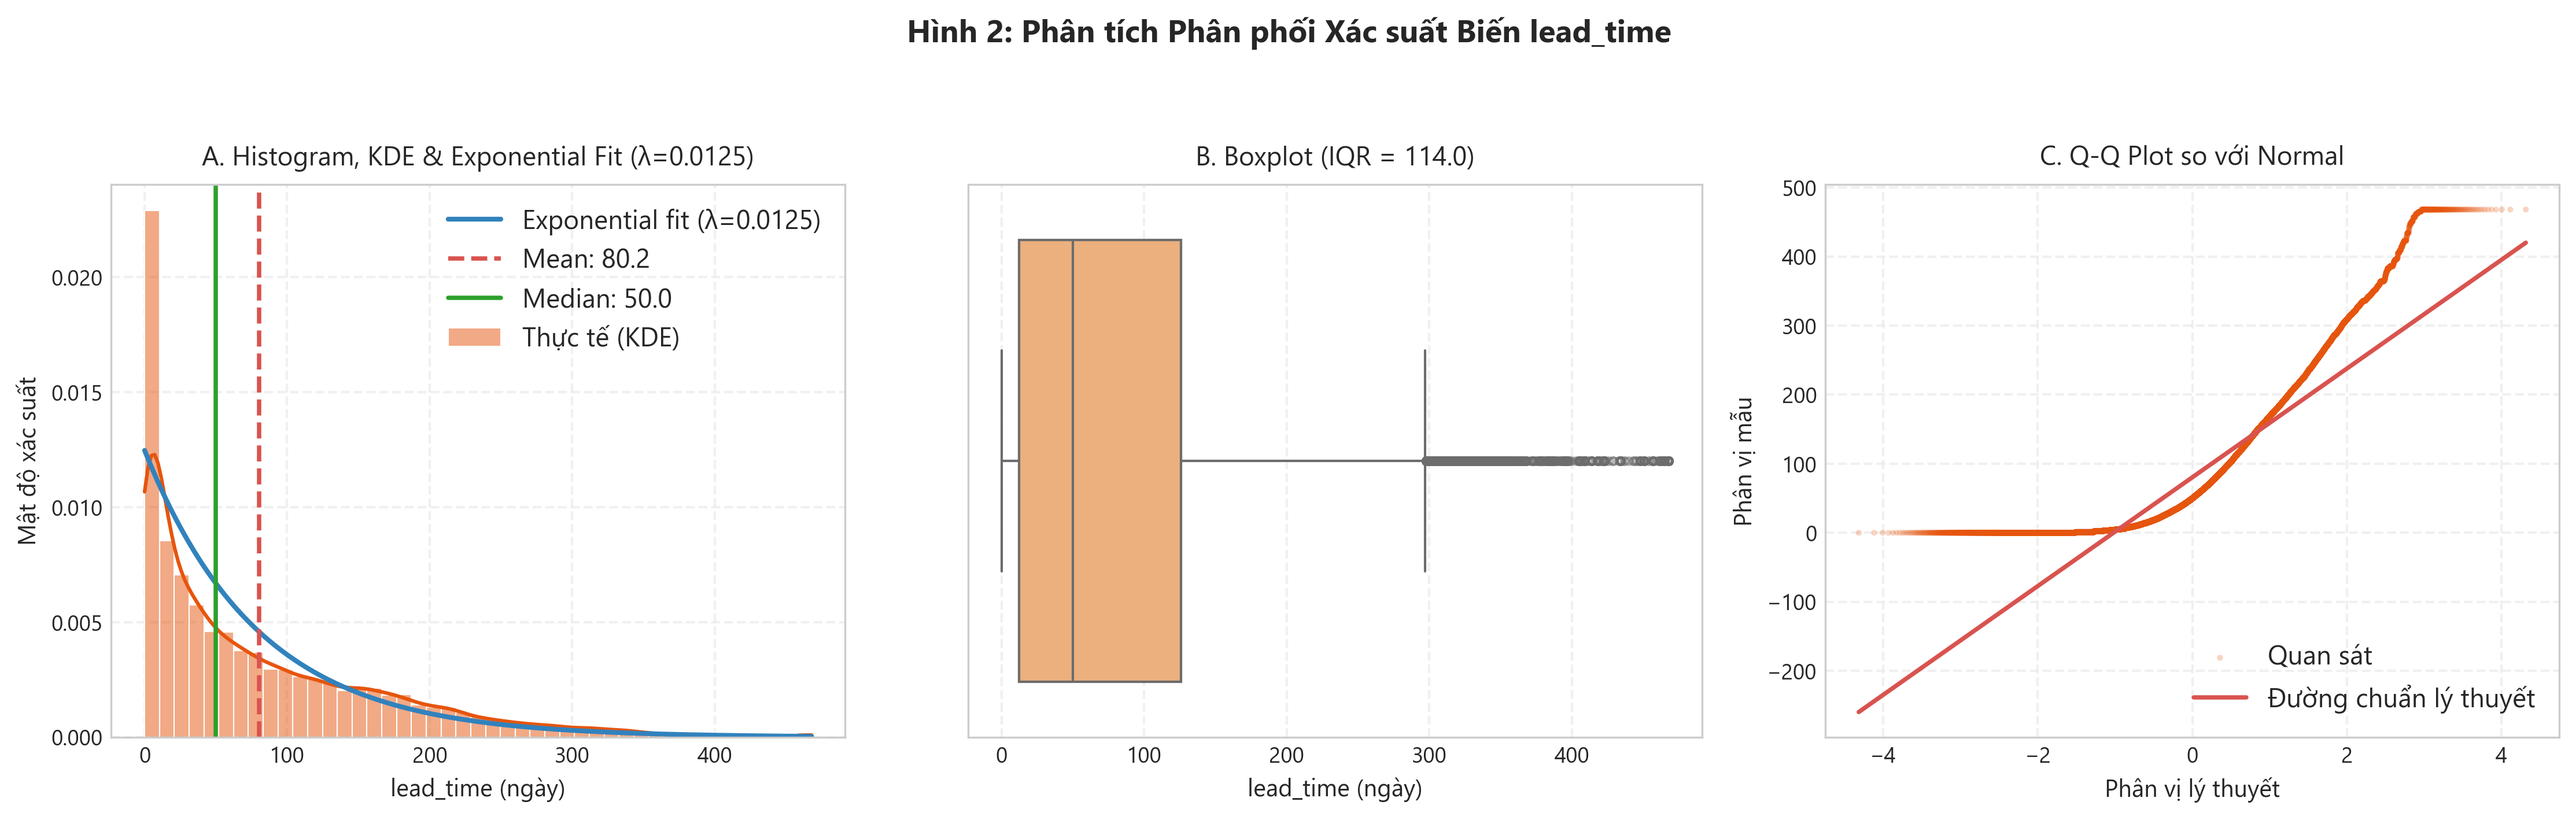


### Nhận xét Lead Time – Exponential

- Mean: 80.22 ngày.
- Median: 50.00 ngày.
- Skewness: 1.37.
- Tham số Exponential λ: 0.0125.
- KS statistic: 0.1228.
- p-value KS: 0.

**Đánh giá:** Không phù hợp với Exponential lý thuyết (dù có dạng suy giảm)

**Kết luận kiểm định:** Reject H0: KS statistic = 0.1228, p = 0 < 0.05. Có bằng chứng dữ liệu không phù hợp với phân phối Exponential lý thuyết. (Tham số được ước lượng từ mẫu, vì vậy p-value KS thông thường cần được diễn giải thận trọng).


In [166]:
lt_desc, lt_tests, lt_interps, lt_summary = analyze_lead_time(clean_df)
lt_figure = PROB_FIGURE_DIR / "dist_02_lead_time_analysis.png"
display(Image(filename=str(lt_figure)))
pd.DataFrame(lt_tests)
display(Markdown(f"""
### Nhận xét Lead Time – Exponential

- Mean: {lt_summary['mean']:.2f} ngày.
- Median: {lt_summary['median']:.2f} ngày.
- Skewness: {lt_summary['skewness']:.2f}.
- Tham số Exponential λ: {lt_summary['lambda']:.4f}.
- KS statistic: {lt_summary['ks_stat']:.4f}.
- p-value KS: {lt_summary['ks_p']:.4g}.

**Đánh giá:** {lt_summary['assessment']}

**Kết luận kiểm định:** {lt_summary['conclusion']}
"""))

## 3.7 Phân tích Special Requests – Poisson

**Lý thuyết:** Poisson là phân phối rời rạc dùng cho số lần sự kiện xảy ra; tham số λ được ước lượng bằng Mean. Mean gần Variance là dấu hiệu tham khảo, không đủ để xác nhận Poisson.

**Kiểm định:** nhóm quan sát thành 0, 1, 2, 3 và ≥4 để so sánh tần số thực tế với tần số kỳ vọng. Kiểm định Chi-square Goodness-of-Fit được dùng khi các tần số kỳ vọng đáp ứng điều kiện áp dụng. Nếu điều kiện tần số kỳ vọng tối thiểu không đạt, code sẽ dừng và báo lỗi thay vì tiếp tục đưa ra kết luận không đáng tin cậy.


In [167]:
def analyze_special_requests(df):
    """Phân tích biến đếm rời rạc: Mean-Variance, tail binning, kiểm tra E_i >= 5 và Chi-Square GOF."""
    s_sr = df["total_of_special_requests"].dropna()
    desc = calculate_descriptive_stats(s_sr, "total_of_special_requests")
    n_total = desc["Count"]
    lam = desc["Mean"]

    obs_counts = s_sr.value_counts().sort_index()

    # Gom nhóm tail: 0, 1, 2, 3 và >= 4
    bins = [0, 1, 2, 3]
    obs_binned = [int(obs_counts.get(k, 0)) for k in bins]
    obs_binned.append(int(obs_counts[obs_counts.index >= 4].sum()))

    # Tần số kỳ vọng Poisson
    exp_probs = [float(stats.poisson.pmf(k, lam)) for k in bins]
    exp_probs.append(float(1.0 - stats.poisson.cdf(3, lam)))
    exp_binned = [p * n_total for p in exp_probs]

    # Kiểm tra điều kiện tần số kỳ vọng E_i >= 5
    min_exp = min(exp_binned)
    if min_exp < 5.0:
        raise ValueError(
            f"Điều kiện kiểm định Chi-Square không thỏa mãn: Có tần số kỳ vọng E_min = {min_exp:.2f} < 5. "
            "Cần gộp thêm các nhóm đuôi để đảm bảo tính hợp lệ của kiểm định."
        )

    # Kiểm tra tổng tương thích
    sum_obs, sum_exp = sum(obs_binned), sum(exp_binned)
    if abs(sum_obs - sum_exp) > 1e-4:
        raise ValueError(f"Tổng tần số không khớp: Observed={sum_obs}, Expected={sum_exp}")

    # Chi-square Goodness-of-Fit với ddof=1 (do 1 tham số lambda được ước lượng từ dữ liệu)
    chi2_res = stats.chisquare(f_obs=obs_binned, f_exp=exp_binned, ddof=1)
    chi2_stat, chi2_p = float(chi2_res.statistic), float(chi2_res.pvalue)
    dec_chi2 = "Reject H0" if chi2_p < ALPHA else "Fail to reject H0"

    disp_ratio = desc["Variance"] / desc["Mean"] if desc["Mean"] > 0 else 1.0

    if chi2_p < ALPHA:
        assess_sr = "Không phù hợp hoàn toàn với Poisson (dù Mean gần Variance)"
        stat_conclusion = (
            f"Reject H0: Chi² = {chi2_stat:.2f}, p = {chi2_p:.4g} < {ALPHA}. "
            f"Mặc dù Mean ({desc['Mean']:.4f}) xấp xỉ Variance ({desc['Variance']:.4f}) với tỷ lệ Var/Mean = {disp_ratio:.4f} "
            "(dấu hiệu phù hợp về moment), kiểm định Chi-square bác bỏ H0. "
            "Dữ liệu có bằng chứng không phù hợp hoàn toàn với Poisson."
        )
    else:
        assess_sr = "Chưa đủ bằng chứng bác bỏ Poisson"
        stat_conclusion = (
            f"Fail to reject H0: Chi² = {chi2_stat:.2f}, p = {chi2_p:.4g} >= {ALPHA}. "
            "Chưa có đủ bằng chứng cho thấy dữ liệu không phù hợp với Poisson."
        )

    basic_comment = (
        f"total_of_special_requests là biến đếm rời rạc. "
        f"Mean ({desc['Mean']:.4f}) và Variance ({desc['Variance']:.4f}) rất gần nhau (Var/Mean = {disp_ratio:.4f}), "
        f"đây là dấu hiệu phù hợp với Poisson nhưng không phải bằng chứng chứng minh. "
        f"Chi-square Goodness-of-Fit (ddof=1) là cơ sở chính đánh giá: {dec_chi2} (Chi² = {chi2_stat:.2f}, p = {chi2_p:.4g})."
    )

    # Biểu đồ special requests
    labels = ["0", "1", "2", "3", ">= 4"]
    emp_props = [o / n_total for o in obs_binned]
    x_pos = np.arange(len(labels))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("Hình 3: Phân tích Phân phối Biến Đếm total_of_special_requests", fontsize=13, fontweight="bold", y=0.98)

    axes[0].bar(x_pos - width / 2, emp_props, width=width, label="Thực tế (Empirical PMF)", color="#3182bd", alpha=0.8, edgecolor="black")
    axes[0].bar(x_pos + width / 2, exp_probs, width=width, label=f"Lý thuyết (Poisson λ={lam:.3f})", color="#e6550d", alpha=0.8, edgecolor="black")
    axes[0].set_title(f"A. So sánh PMF Thực tế vs Poisson (Mean={lam:.3f}, Var={desc['Variance']:.3f})", pad=8)
    axes[0].set_xlabel("Số lượng yêu cầu đặc biệt")
    axes[0].set_ylabel("Tỷ lệ xác suất")
    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(labels)
    axes[0].legend()

    for i in x_pos:
        axes[0].text(i - width / 2, emp_props[i] + 0.01, f"{emp_props[i]:.2f}", ha="center", fontsize=8)
        axes[0].text(i + width / 2, exp_probs[i] + 0.01, f"{exp_probs[i]:.2f}", ha="center", fontsize=8, color="#a63603")

    diff_pct = [(emp - exp) * 100 for emp, exp in zip(emp_props, exp_probs)]
    bar_colors = ["#d9534f" if v < 0 else "#2ca02c" for v in diff_pct]
    axes[1].bar(x_pos, diff_pct, color=bar_colors, edgecolor="black", width=0.45, alpha=0.8)
    axes[1].axhline(0, color="black", linestyle="-", linewidth=0.8)
    axes[1].set_title("B. Chênh lệch Tỷ lệ (Empirical % - Poisson %)", pad=8)
    axes[1].set_xlabel("Số lượng yêu cầu đặc biệt")
    axes[1].set_ylabel("Điểm phần trăm chênh lệch (% diff)")
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(labels)

    for i, v in enumerate(diff_pct):
        axes[1].text(i, v + (0.25 if v >= 0 else -0.55), f"{v:+.2f}%", ha="center", fontsize=8, fontweight="bold")

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(PROB_FIGURE_DIR / "dist_03_special_requests_poisson.png", dpi=300, bbox_inches="tight")
    plt.close()

    test_rows = [
        {"Variable": "total_of_special_requests", "Distribution": f"Poisson(λ={lam:.4f})", "Test": "Chi-Square Goodness-of-Fit (ddof=1, Tail >= 4)", "Statistic": float(chi2_stat), "P_Value": float(chi2_p), "Alpha": ALPHA, "Decision": dec_chi2, "Conclusion": stat_conclusion}
    ]

    interp_rows = [
        {"Variable": "total_of_special_requests", "Data_Type": "Discrete count", "Count": desc["Count"], "Mean": desc["Mean"], "Median": desc["Median"], "Variance": desc["Variance"], "Std": desc["Std"], "Skewness": desc["Skewness"], "Kurtosis": desc["Kurtosis"], "Distribution_Candidate": f"Poisson(λ={lam:.4f})", "Test_Name": "Chi-Square Goodness-of-Fit (Tail >= 4)", "Test_Statistic": float(chi2_stat), "P_Value": float(chi2_p), "Decision": dec_chi2, "Distribution_Assessment": assess_sr, "Basic_Comment": basic_comment}
    ]

    summary_info = {
        "mean": desc["Mean"], "variance": desc["Variance"], "lambda": lam,
        "chi2_stat": chi2_stat, "chi2_p": chi2_p, "assessment": assess_sr, "conclusion": stat_conclusion
    }

    return desc, test_rows, interp_rows, summary_info

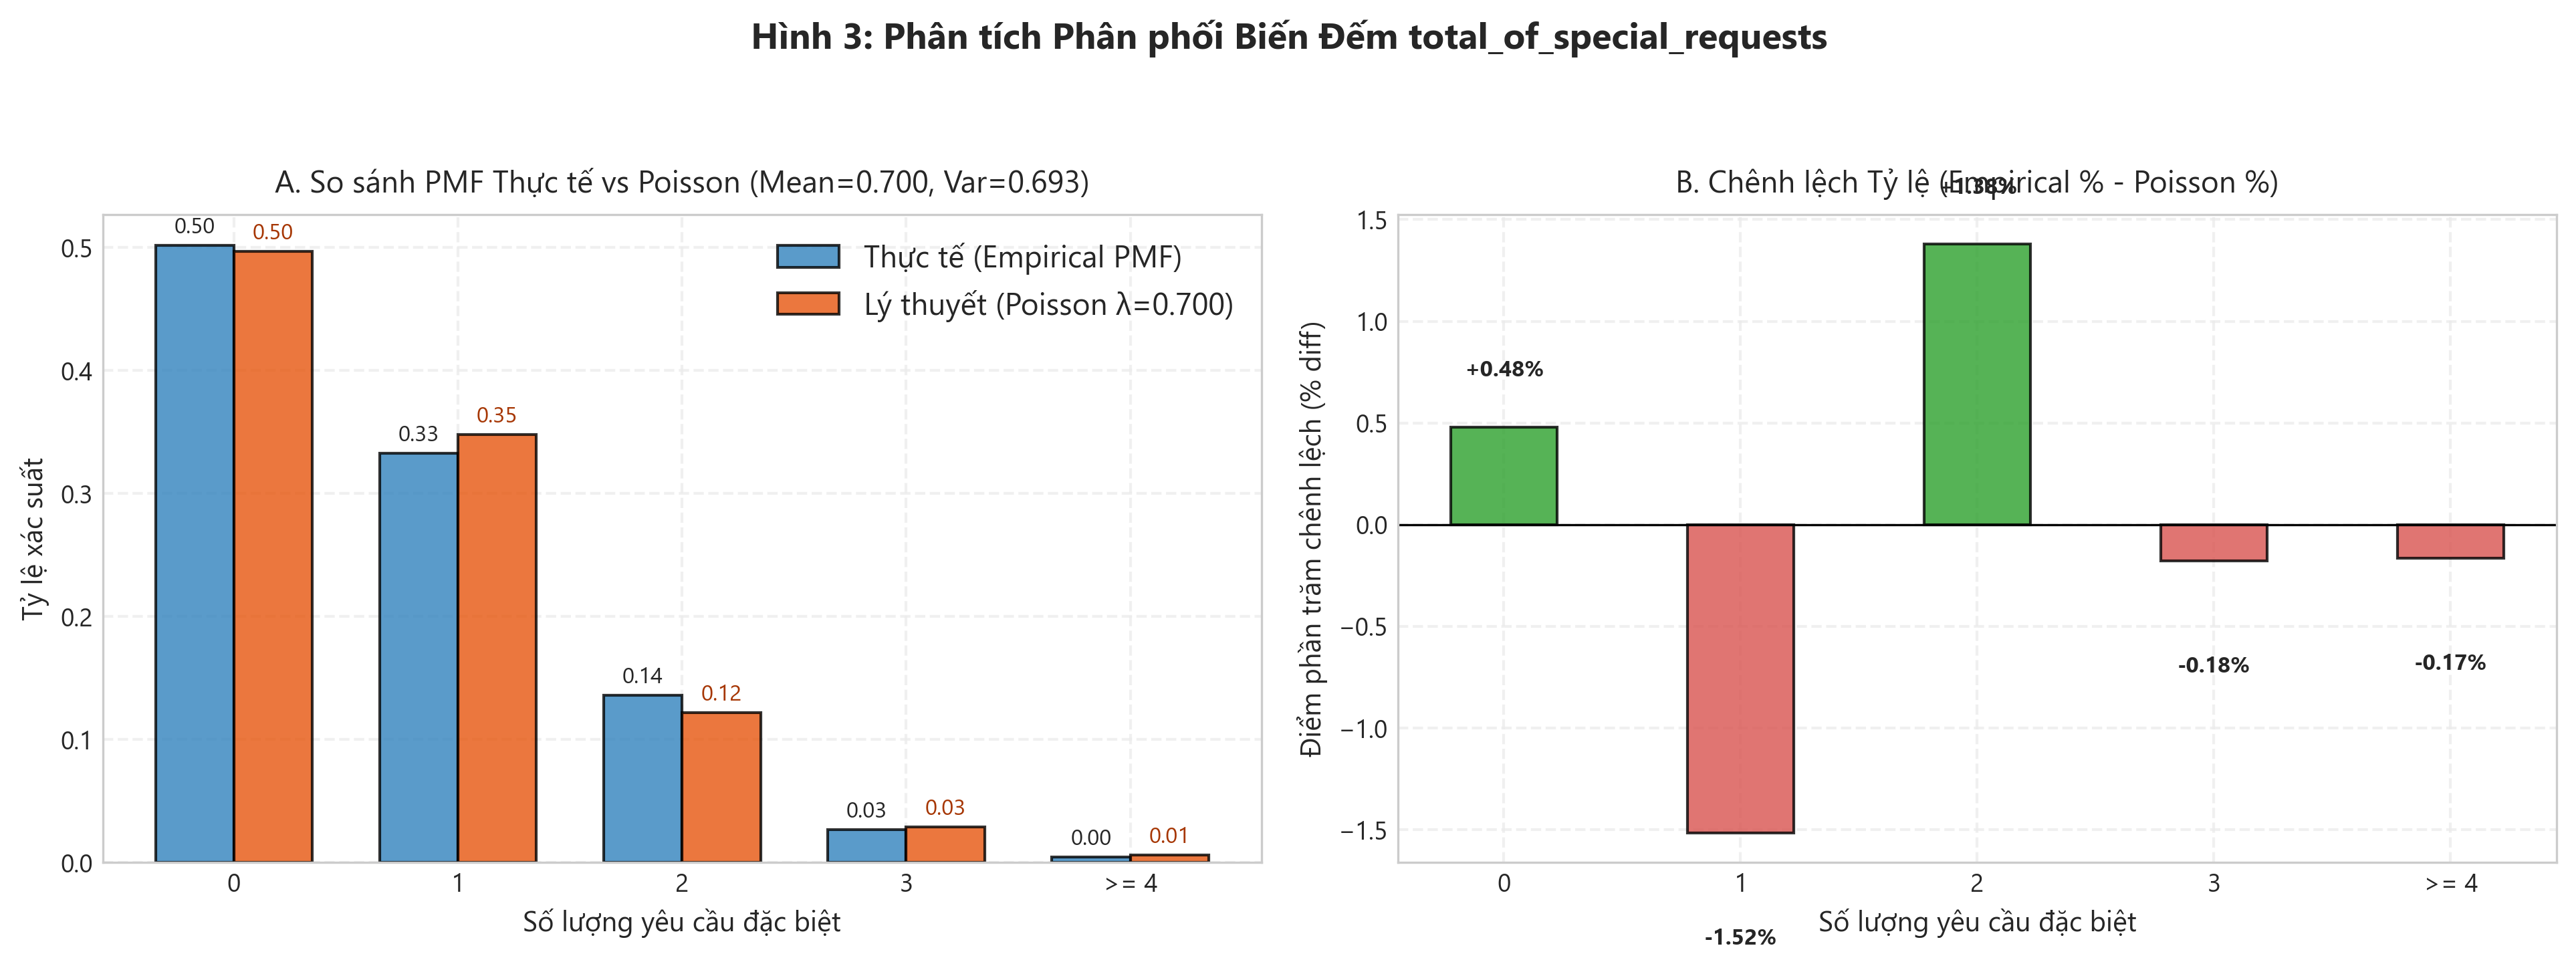


### Nhận xét Total of Special Requests – Poisson

- Mean: 0.7002.
- Variance: 0.6933.
- Tham số Poisson λ: 0.7002.
- Chi-square statistic: 247.2512.
- p-value Chi-square: 2.572e-53.

**Đánh giá:** Không phù hợp hoàn toàn với Poisson (dù Mean gần Variance)

**Kết luận kiểm định:** Reject H0: Chi² = 247.25, p = 2.572e-53 < 0.05. Mặc dù Mean (0.7002) xấp xỉ Variance (0.6933) với tỷ lệ Var/Mean = 0.9902 (dấu hiệu phù hợp về moment), kiểm định Chi-square bác bỏ H0. Dữ liệu có bằng chứng không phù hợp hoàn toàn với Poisson.


In [168]:
sr_desc, sr_tests, sr_interps, sr_summary = analyze_special_requests(clean_df)
sr_figure = PROB_FIGURE_DIR / "dist_03_special_requests_poisson.png"
display(Image(filename=str(sr_figure)))
pd.DataFrame(sr_tests)
display(Markdown(f"""
### Nhận xét Total of Special Requests – Poisson

- Mean: {sr_summary['mean']:.4f}.
- Variance: {sr_summary['variance']:.4f}.
- Tham số Poisson λ: {sr_summary['lambda']:.4f}.
- Chi-square statistic: {sr_summary['chi2_stat']:.4f}.
- p-value Chi-square: {sr_summary['chi2_p']:.4g}.

**Đánh giá:** {sr_summary['assessment']}

**Kết luận kiểm định:** {sr_summary['conclusion']}
"""))

## 3.8 Tổng hợp kết quả và lưu bảng

Các bảng đầu ra gồm: thống kê mô tả, kết quả kiểm định và bảng diễn giải. Khi kết luận, dùng α = 0,05: nếu p-value < α thì bác bỏ H₀; nếu p-value ≥ α thì chưa đủ bằng chứng bác bỏ H₀. Không diễn giải trường hợp thứ hai thành “đã chứng minh phân phối phù hợp”.


In [169]:
def save_results(desc_list, test_rows, interp_rows):
    """Lưu 3 file CSV chuẩn hóa vào results/tables/."""
    pd.DataFrame(desc_list).to_csv(PROB_TABLE_DIR / "descriptive_statistics.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(test_rows).to_csv(PROB_TABLE_DIR / "distribution_test_results.csv", index=False, encoding="utf-8-sig")

    interp_cols = [
        "Variable", "Data_Type", "Count", "Mean", "Median", "Variance", "Std",
        "Skewness", "Kurtosis", "Distribution_Candidate", "Test_Name",
        "Test_Statistic", "P_Value", "Decision", "Distribution_Assessment", "Basic_Comment"
    ]
    pd.DataFrame(interp_rows)[interp_cols].to_csv(PROB_TABLE_DIR / "distribution_interpretation.csv", index=False, encoding="utf-8-sig")

    print("\nĐã lưu các bảng kết quả CSV:")
    print(f"1. {PROB_TABLE_DIR / 'descriptive_statistics.csv'}")
    print(f"2. {PROB_TABLE_DIR / 'distribution_test_results.csv'}")
    print(f"3. {PROB_TABLE_DIR / 'distribution_interpretation.csv'}")

In [170]:
all_desc = [adr_desc, lt_desc, sr_desc]
all_tests = adr_tests + lt_tests + sr_tests
all_interps = adr_interps + lt_interps + sr_interps
save_results(all_desc, all_tests, all_interps)

display(pd.DataFrame(all_desc))
display(pd.DataFrame(all_tests)[["Variable", "Distribution", "Test", "Statistic", "P_Value", "Alpha", "Decision", "Conclusion"]])


Đã lưu các bảng kết quả CSV:
1. C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\probability_distribution\descriptive_statistics.csv
2. C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\probability_distribution\distribution_test_results.csv
3. C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\probability_distribution\distribution_interpretation.csv


,Variable,Count,Mean,Median,Std,Variance,Min,Q1,Q3,Max,IQR,Lower_Bound,Upper_Bound,Potential_Outliers,Skewness,Kurtosis
0,adr,86633,107.137942,99.0,51.064520,2607.585201,0.0,72.9,134.44,319.06,61.54,-19.41,226.75,2510,0.877296,1.217429
1,lead_time,86633,80.219004,50.0,85.682469,7341.485477,0.0,12.0,126.00,468.00,114.00,-159.00,297.00,2353,1.374687,1.689974
2,total_of_special_requests,86633,0.700230,0.0,0.832667,0.693335,0.0,0.0,1.00,5.00,1.00,-1.50,2.50,2663,1.080976,0.817046


,Variable,Distribution,Test,Statistic,P_Value,Alpha,Decision,Conclusion
0,adr,Normal,D'Agostino's K² Test,10567.683235,0.000000e+00,0.05,Reject H0,"K² = 10567.68, p = 0. Reject H0 phân phối chuẩn."
1,adr,Log-Normal,D'Agostino's K² Test on log(ADR),16040.762321,0.000000e+00,0.05,Reject H0,D'Agostino K² trên log(ADR) có p = 0 < 0.05 (R...
2,lead_time,Exponential,Kolmogorov-Smirnov Test (Estimated Scale),0.122842,0.000000e+00,0.05,Reject H0,"Reject H0: KS statistic = 0.1228, p = 0 < 0.05..."
3,total_of_special_requests,Poisson(λ=0.7002),"Chi-Square Goodness-of-Fit (ddof=1, Tail >= 4)",247.251219,2.572381e-53,0.05,Reject H0,"Reject H0: Chi² = 247.25, p = 2.572e-53 < 0.05..."


## 3.9 Kết luận chung

Dựa trên các bảng và biểu đồ vừa tạo, hãy nhận xét riêng từng biến theo trình tự: **đặc điểm dữ liệu → quan sát biểu đồ → kết quả kiểm định → kết luận có giới hạn**.

- **ADR:** so sánh ADR gốc và log(ADR), đặc biệt là p-value D’Agostino K².
- **Lead Time:** xem mức độ lệch phải và kết quả KS; lưu ý giới hạn khi tham số được ước lượng từ mẫu.
- **Special Requests:** xem chênh lệch PMF thực nghiệm–Poisson và kết quả Chi-square, đồng thời kiểm tra điều kiện tần số kỳ vọng.

Các hình PNG được lưu trong `results/figures/`; các bảng CSV được lưu trong `results/tables/`.


# 4. Kiểm định giả thuyết thống kê



In [ ]:

ALPHA = 0.05

## 4.1 Cấu hình kiểm định

Sử dụng mức ý nghĩa **α = 0,05** và dữ liệu đã làm sạch được khai báo ở đầu notebook.


## 4.2 Đọc dữ liệu

Nạp bộ dữ liệu đã xử lý và kiểm tra kích thước để xác nhận dữ liệu đầu vào được đọc đúng.


In [172]:
print("=" * 60)
print("HYPOTHESIS TESTING")
print("=" * 60)

df = pd.read_csv(CLEANED_PATH)
print("\nKích thước dữ liệu:")
print(df.shape)


HYPOTHESIS TESTING

Kích thước dữ liệu:
(86633, 38)


## 4.3 Kiểm tra các biến cần dùng

Xác nhận các cột cần dùng đều tồn tại, đồng thời xem dữ liệu mẫu, kiểu dữ liệu và giá trị thiếu trước khi kiểm định.


In [173]:
# =========================
# 3. Kiểm tra các biến cần dùng
# =========================
required_columns = [
    "hotel",
    "adr",
    "is_canceled",
    "market_segment"
]

print("\nCác biến sử dụng:")
print(required_columns)

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần thiết: {missing_columns}"
    )

# Chỉ lấy các biến cần quan tâm để kiểm tra
test_data = df[required_columns]

print("\n5 dòng đầu:")
display(test_data.head())

print("\nKiểu dữ liệu:")
display(test_data.dtypes.to_frame("Kiểu dữ liệu"))

print("\nSố lượng giá trị thiếu:")
display(test_data.isnull().sum().to_frame("Số giá trị thiếu"))

# =========================


Các biến sử dụng:
['hotel', 'adr', 'is_canceled', 'market_segment']

5 dòng đầu:


,hotel,adr,is_canceled,market_segment
0,Resort Hotel,75.0,0,Direct
1,Resort Hotel,75.0,0,Corporate
2,Resort Hotel,98.0,0,Online TA
3,Resort Hotel,107.0,0,Direct
4,Resort Hotel,103.0,0,Direct



Kiểu dữ liệu:


,Kiểu dữ liệu
hotel,object
adr,float64
is_canceled,int64
market_segment,object



Số lượng giá trị thiếu:


,Số giá trị thiếu
hotel,0
adr,0
is_canceled,0
market_segment,0


## 4.4 Kiểm tra giá trị của biến phân loại

Kiểm tra số lượng quan sát ở từng nhóm để hiểu cấu trúc dữ liệu và phát hiện nhãn nhóm bất thường.


In [174]:
# =========================
# 4. Kiểm tra giá trị của biến phân loại
# =========================
print("\nSố lượng theo hotel:")
print(df["hotel"].value_counts(dropna=False))

print("\nSố lượng theo is_canceled:")
print(df["is_canceled"].value_counts(dropna=False))

print("\nSố lượng theo market_segment:")
print(df["market_segment"].value_counts(dropna=False))

# =========================


Số lượng theo hotel:
hotel
City Hotel      53042
Resort Hotel    33591
Name: count, dtype: int64

Số lượng theo is_canceled:
is_canceled
0    62648
1    23985
Name: count, dtype: int64

Số lượng theo market_segment:
market_segment
Online TA        51285
Offline TA/TO    13748
Direct           11652
Groups            4891
Corporate         4151
Complementary      682
Aviation           222
Undefined            2
Name: count, dtype: int64


## 4.5 Kiểm tra nhanh ADR

Xem thống kê mô tả của ADR (giá phòng trung bình mỗi ngày) trước khi so sánh giữa các nhóm.


In [175]:
# =========================
# 5. Kiểm tra nhanh ADR
# =========================
print("\nThống kê mô tả ADR:")
print(df["adr"].describe())

# =========================


Thống kê mô tả ADR:
count    86633.000000
mean       107.137942
std         51.064520
min          0.000000
25%         72.900000
50%         99.000000
75%        134.440000
max        319.060000
Name: adr, dtype: float64


## 4.6 Independent Samples t-test

Kiểm định hai mẫu độc lập đánh giá liệu ADR trung bình giữa City Hotel và Resort Hotel có khác biệt có ý nghĩa thống kê hay không. H0: hai trung bình bằng nhau; H1: hai trung bình khác nhau.


In [176]:
# =========================
# 6. Independent Samples t-test
# ADR giữa City Hotel và Resort Hotel
# =========================
print("\n" + "=" * 60)
print("T-TEST: ADR GIỮA CITY HOTEL VÀ RESORT HOTEL")
print("\nGiả thuyết:")
print("H0: ADR trung bình của City Hotel và Resort Hotel bằng nhau.")
print("H1: ADR trung bình của City Hotel và Resort Hotel khác nhau.")
print("=" * 60)

# Tách ADR thành 2 nhóm
city_adr = df.loc[
    df["hotel"] == "City Hotel",
    "adr"
].dropna()

resort_adr = df.loc[
    df["hotel"] == "Resort Hotel",
    "adr"
].dropna()

# -------------------------


T-TEST: ADR GIỮA CITY HOTEL VÀ RESORT HOTEL

Giả thuyết:
H0: ADR trung bình của City Hotel và Resort Hotel bằng nhau.
H1: ADR trung bình của City Hotel và Resort Hotel khác nhau.


## 4.7 Thống kê mô tả

Tóm tắt kích thước mẫu, trung bình và độ lệch chuẩn của các nhóm để hỗ trợ diễn giải kết quả kiểm định.


In [177]:
# -------------------------
# 6.1. Thống kê mô tả
# -------------------------

print("\nThống kê mô tả:")

print(f"City Hotel:")
print(f"  n    = {len(city_adr)}")
print(f"  Mean = {city_adr.mean():.4f}")
print(f"  Std  = {city_adr.std():.4f}")

print(f"\nResort Hotel:")
print(f"  n    = {len(resort_adr)}")
print(f"  Mean = {resort_adr.mean():.4f}")
print(f"  Std  = {resort_adr.std():.4f}")

# -------------------------


Thống kê mô tả:
City Hotel:
  n    = 53042
  Mean = 111.6437
  Std  = 41.3140

Resort Hotel:
  n    = 33591
  Mean = 100.0232
  Std  = 62.8277


## 4.8 Levene's Test

Levene’s Test kiểm tra giả định đồng nhất phương sai. Kết quả được dùng để chọn phiên bản kiểm định phù hợp theo logic trong mã gốc.


In [178]:
# -------------------------
# 6.2. Levene's Test
# Kiểm tra phương sai 2 nhóm
# -------------------------
levene_stat, levene_p = stats.levene(
    city_adr,
    resort_adr
)

print("\nLevene's Test:")
print(f"Statistic = {levene_stat:.4f}")
if levene_p < 0.001:
    print("p-value   < 0.001")
else:
    print(f"p-value   = {levene_p:.6f}")

# Nếu p < 0.05:
# phương sai 2 nhóm khác nhau
# -> sử dụng Welch's t-test

equal_variance = levene_p >= ALPHA

# -------------------------


Levene's Test:
Statistic = 4655.9891
p-value   < 0.001


## 4.9 T-test

Kiểm định hai mẫu độc lập đánh giá liệu ADR trung bình giữa City Hotel và Resort Hotel có khác biệt có ý nghĩa thống kê hay không. H0: hai trung bình bằng nhau; H1: hai trung bình khác nhau.


In [179]:
# -------------------------
# 6.3. T-test
# -------------------------

t_stat, p_value = stats.ttest_ind(
    city_adr,
    resort_adr,
    equal_var=equal_variance
)

test_name = (
    "Student's independent t-test"
    if equal_variance
    else "Welch's independent t-test"
)

print(f"\nPhương pháp sử dụng: {test_name}")

print("\nKết quả t-test:")
print(f"t-statistic = {t_stat:.4f}")

if p_value < 0.001:
    print("p-value     < 0.001")
else:
    print(f"p-value     = {p_value:.6f}")

# -------------------------


Phương pháp sử dụng: Welch's independent t-test

Kết quả t-test:
t-statistic = 30.0350
p-value     < 0.001


## 4.10 Khoảng tin cậy 95% cho chênh lệch trung bình

Khoảng tin cậy 95% ước lượng phạm vi hợp lý cho chênh lệch trung bình ADR (City Hotel trừ Resort Hotel).


In [180]:
# -------------------------
# 6.4. Khoảng tin cậy 95% cho chênh lệch trung bình
# -------------------------
mean_diff = city_adr.mean() - resort_adr.mean()

var_city = city_adr.var(ddof=1)
var_resort = resort_adr.var(ddof=1)

n_city = len(city_adr)
n_resort = len(resort_adr)

if equal_variance:
    # Student's t-test:
    # dùng pooled variance và df = n1 + n2 - 2
    pooled_variance = (
        ((n_city - 1) * var_city)
        + ((n_resort - 1) * var_resort)
    ) / (n_city + n_resort - 2)

    se_diff = np.sqrt(
        pooled_variance
        * (1 / n_city + 1 / n_resort)
    )

    df_ci = n_city + n_resort - 2

else:
    # Welch's t-test:
    # không giả định phương sai hai nhóm bằng nhau
    se_diff = np.sqrt(
        var_city / n_city
        + var_resort / n_resort
    )

    df_ci = (
        var_city / n_city
        + var_resort / n_resort
    ) ** 2 / (
        (var_city / n_city) ** 2 / (n_city - 1)
        +
        (var_resort / n_resort) ** 2 / (n_resort - 1)
    )

critical_t = stats.t.ppf(
    1 - ALPHA / 2,
    df_ci
)

ci_lower = mean_diff - critical_t * se_diff
ci_upper = mean_diff + critical_t * se_diff

print(f"\nChênh lệch trung bình = {mean_diff:.4f}")
print(f"95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")

# -------------------------


Chênh lệch trung bình = 11.6205
95% CI = [10.8622, 12.3788]


## 4.11 Kết luận kiểm định t-test

Kết luận dựa trên p-value và mức ý nghĩa α = 0,05. Nếu p-value nhỏ hơn α, bác bỏ giả thuyết không.


In [181]:
# -------------------------
# 6.5. Kết luận
# -------------------------
if p_value < ALPHA:

    if city_adr.mean() > resort_adr.mean():
        direction = "City Hotel có ADR trung bình cao hơn Resort Hotel"
    else:
        direction = "Resort Hotel có ADR trung bình cao hơn City Hotel"

    conclusion = (
        "Bác bỏ H0. Có sự khác biệt có ý nghĩa thống kê "
        "về ADR trung bình giữa City Hotel và Resort Hotel. "
        f"{direction}."
    )
else:
    conclusion = (
        "Chưa đủ bằng chứng để bác bỏ H0. "
        "Chưa phát hiện sự khác biệt có ý nghĩa thống kê "
        "về ADR trung bình giữa City Hotel và Resort Hotel."
    )

print("\nKết luận:")
print(conclusion)

# -------------------------


Kết luận:
Bác bỏ H0. Có sự khác biệt có ý nghĩa thống kê về ADR trung bình giữa City Hotel và Resort Hotel. City Hotel có ADR trung bình cao hơn Resort Hotel.


## 4.12 Cohen's d

Cohen’s d đo độ lớn khác biệt chuẩn hóa, bổ sung thông tin bên cạnh ý nghĩa thống kê.


In [182]:
# -------------------------
# 6.6. Cohen's d
# Đo mức độ khác biệt thực tế
# -------------------------
n1 = len(city_adr)
n2 = len(resort_adr)

std1 = city_adr.std(ddof=1)
std2 = resort_adr.std(ddof=1)

pooled_std = np.sqrt(
    (
        (n1 - 1) * std1**2
        + (n2 - 1) * std2**2
    )
    / (n1 + n2 - 2)
)

cohens_d = (
    city_adr.mean() - resort_adr.mean()
) / pooled_std

abs_d = abs(cohens_d)

if abs_d < 0.2:
    d_level = "rất nhỏ"
elif abs_d < 0.5:
    d_level = "nhỏ"
elif abs_d < 0.8:
    d_level = "trung bình"
else:
    d_level = "lớn"

print(
    f"\nCohen's d = {cohens_d:.4f} "
    f"({d_level})"
)

# -------------------------


Cohen's d = 0.2290 (nhỏ)


## 4.13 Biểu đồ

Bảng/biểu đồ giúp quan sát trực quan tỷ lệ hủy hoặc phân bố ADR giữa các nhóm. Biểu đồ được lưu và hiển thị ngay bên dưới ô code.


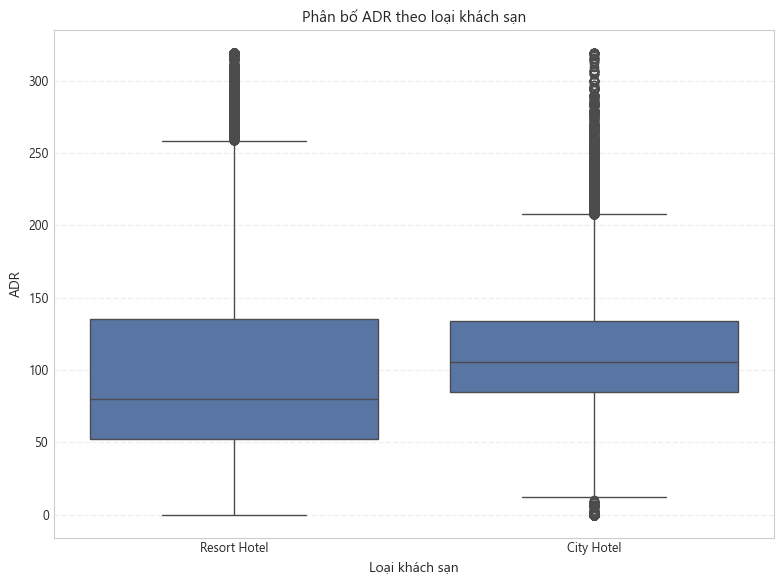

In [183]:
# -------------------------
# 6.7. Biểu đồ
# -------------------------
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="hotel",
    y="adr"
)

plt.title("Phân bố ADR theo loại khách sạn")
plt.xlabel("Loại khách sạn")
plt.ylabel("ADR")

plt.tight_layout()

plt.savefig(
    HYPOTHESIS_FIGURE_DIR / "ttest_adr_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# -------------------------

## 4.14 Lưu kết quả

Lưu các thống kê và kết luận thành tệp CSV để sử dụng nhất quán trong báo cáo.


In [184]:
# -------------------------
# 6.8. Lưu kết quả
# -------------------------
ttest_result = pd.DataFrame({
    "test": [test_name],
    "city_n": [len(city_adr)],
    "city_mean": [city_adr.mean()],
    "city_std": [city_adr.std()],
    "resort_n": [len(resort_adr)],
    "resort_mean": [resort_adr.mean()],
    "resort_std": [resort_adr.std()],
    "levene_statistic": [levene_stat],
    "levene_p_value": [levene_p],
    "t_statistic": [t_stat],
    "p_value": [p_value],
    "mean_difference": [mean_diff],
    "ci_95_lower": [ci_lower],
    "ci_95_upper": [ci_upper],
    "cohens_d": [cohens_d],
    "effect_size_level": [d_level],
    "conclusion": [conclusion]
})

ttest_result.to_csv(
    os.path.join(
        HYPOTHESIS_TABLE_DIR,
        "ttest_results.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# =========================

## 4.15 Chi-square Test of Independence

Chi-square Test of Independence kiểm tra mối liên hệ giữa hai biến phân loại. H0: hai biến độc lập; H1: hai biến có liên hệ.


In [185]:
# =========================
# 7. Chi-square Test of Independence
# hotel và is_canceled
# =========================
print("\n" + "=" * 60)
print("CHI-SQUARE: HOTEL VÀ IS_CANCELED")
print("\nGiả thuyết:")
print("H0: Loại khách sạn và trạng thái hủy đặt phòng độc lập.")
print("H1: Loại khách sạn và trạng thái hủy đặt phòng có mối liên hệ.")
print("=" * 60)

# -------------------------


CHI-SQUARE: HOTEL VÀ IS_CANCELED

Giả thuyết:
H0: Loại khách sạn và trạng thái hủy đặt phòng độc lập.
H1: Loại khách sạn và trạng thái hủy đặt phòng có mối liên hệ.


## 4.16 Tạo bảng chéo

Bảng chéo thể hiện tần số quan sát của từng tổ hợp loại khách sạn và trạng thái hủy đặt phòng.


In [186]:
# -------------------------
# 7.1. Tạo bảng chéo
# -------------------------
contingency_table = pd.crosstab(
    df["hotel"],
    df["is_canceled"]
)

print("\nBảng tần số quan sát:")
display(contingency_table)

# -------------------------


Bảng tần số quan sát:


is_canceled,0,1
hotel,,
City Hotel,37021,16021
Resort Hotel,25627,7964


## 4.17 Chi-square test

Chi-square Test of Independence kiểm tra mối liên hệ giữa hai biến phân loại. H0: hai biến độc lập; H1: hai biến có liên hệ.


In [187]:
# -------------------------
# 7.2. Chi-square test
# -------------------------
chi2_stat, p_value_chi, dof, expected = stats.chi2_contingency(
    contingency_table,
    correction=False
)
print("\nKết quả Chi-square:")
print(f"Chi-square statistic = {chi2_stat:.4f}")
print(f"Degrees of freedom   = {dof}")

if p_value_chi < 0.001:
    print("p-value              < 0.001")
else:
    print(f"p-value              = {p_value_chi:.6f}")
    
# -------------------------


Kết quả Chi-square:
Chi-square statistic = 433.4335
Degrees of freedom   = 1
p-value              < 0.001


## 4.18 Expected frequencies

Tần số kỳ vọng được đối chiếu với ngưỡng 5 để kiểm tra điều kiện áp dụng xấp xỉ Chi-square.


In [188]:
# -------------------------
# 7.3. Expected frequencies
# -------------------------

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected frequencies:")
display(expected_df)

min_expected_freq = expected_df.min().min()

print(
    "\nExpected frequency nhỏ nhất = "
    f"{min_expected_freq:.4f}"
)

if min_expected_freq >= 5:
    print("Thỏa điều kiện Chi-square: tất cả expected frequencies >= 5.")
else:
    print(
        "Cảnh báo: có expected frequency < 5. "
        "Nên cân nhắc Fisher's Exact Test."
    )

# -------------------------


Expected frequencies:


is_canceled,0,1
hotel,,
City Hotel,38356.921912,14685.078088
Resort Hotel,24291.078088,9299.921912



Expected frequency nhỏ nhất = 9299.9219
Thỏa điều kiện Chi-square: tất cả expected frequencies >= 5.


## 4.19 Cramer's V

Cramer’s V đo độ mạnh của mối liên hệ giữa hai biến phân loại; giá trị gần 0 biểu thị liên hệ yếu hơn.


In [189]:
# -------------------------
# 7.4. Cramer's V
# Đo mức độ liên hệ
# -------------------------
n = contingency_table.to_numpy().sum()
r, k = contingency_table.shape

cramers_v = np.sqrt(
    chi2_stat / (n * min(r - 1, k - 1))
)

# Diễn giải mức độ liên hệ
if cramers_v < 0.1:
    v_level = "rất yếu"
elif cramers_v < 0.3:
    v_level = "yếu"
elif cramers_v < 0.5:
    v_level = "trung bình"
else:
    v_level = "mạnh"

print(
    f"\nCramer's V = {cramers_v:.4f} "
    f"({v_level})"
)

# -------------------------


Cramer's V = 0.0707 (rất yếu)


## 4.20 Tỷ lệ hủy theo loại khách sạn

Bảng/biểu đồ giúp quan sát trực quan tỷ lệ hủy hoặc phân bố ADR giữa các nhóm. Biểu đồ được lưu và hiển thị ngay bên dưới ô code.


In [190]:
# -------------------------
# 7.5. Tỷ lệ hủy theo loại khách sạn
# -------------------------
cancellation_rate = pd.crosstab(
    df["hotel"],
    df["is_canceled"],
    normalize="index"
) * 100

print("\nTỷ lệ theo từng loại khách sạn (%):")
display(cancellation_rate)

city_cancel_rate = cancellation_rate.loc["City Hotel", 1]
resort_cancel_rate = cancellation_rate.loc["Resort Hotel", 1]

cancel_diff = city_cancel_rate - resort_cancel_rate
abs_cancel_diff = abs(cancel_diff)

# Xác định khách sạn nào có tỷ lệ hủy cao hơn
if city_cancel_rate > resort_cancel_rate:
    direction_chi = (
        f"City Hotel có tỷ lệ hủy cao hơn Resort Hotel "
        f"({city_cancel_rate:.2f}% so với "
        f"{resort_cancel_rate:.2f}%)"
    )

elif city_cancel_rate < resort_cancel_rate:
    direction_chi = (
        f"Resort Hotel có tỷ lệ hủy cao hơn City Hotel "
        f"({resort_cancel_rate:.2f}% so với "
        f"{city_cancel_rate:.2f}%)"
    )

else:
    direction_chi = (
        f"Hai loại khách sạn có tỷ lệ hủy bằng nhau "
        f"({city_cancel_rate:.2f}%)"
    )

print("\nTỷ lệ hủy đặt phòng:")
print(f"City Hotel: {city_cancel_rate:.2f}%")
print(f"Resort Hotel: {resort_cancel_rate:.2f}%")
print(f"Chênh lệch: {abs_cancel_diff:.2f} điểm phần trăm")

# -------------------------


Tỷ lệ theo từng loại khách sạn (%):


is_canceled,0,1
hotel,,
City Hotel,69.795634,30.204366
Resort Hotel,76.291268,23.708732



Tỷ lệ hủy đặt phòng:
City Hotel: 30.20%
Resort Hotel: 23.71%
Chênh lệch: 6.50 điểm phần trăm


## 4.21 Kết luận kiểm định Chi-square

Kết luận dựa trên p-value và mức ý nghĩa α = 0,05. Nếu p-value nhỏ hơn α, bác bỏ giả thuyết không.


In [191]:
# -------------------------
# 7.6. Kết luận
# -------------------------
if p_value_chi < ALPHA:
    chi_conclusion = (
        "Bác bỏ H0. Có mối liên hệ có ý nghĩa thống kê "
        "giữa loại khách sạn và trạng thái hủy đặt phòng. "
        f"{direction_chi}, "
        f"chênh lệch {abs_cancel_diff:.2f} điểm phần trăm. "
        f"Mức độ liên hệ {v_level} "
        f"(Cramer's V = {cramers_v:.4f})."
    )
else:
    chi_conclusion = (
        "Chưa đủ bằng chứng để bác bỏ H0. "
        "Chưa phát hiện mối liên hệ có ý nghĩa thống kê "
        "giữa loại khách sạn và trạng thái hủy đặt phòng."
    )

print("\nKết luận:")
print(chi_conclusion)

# -------------------------


Kết luận:
Bác bỏ H0. Có mối liên hệ có ý nghĩa thống kê giữa loại khách sạn và trạng thái hủy đặt phòng. City Hotel có tỷ lệ hủy cao hơn Resort Hotel (30.20% so với 23.71%), chênh lệch 6.50 điểm phần trăm. Mức độ liên hệ rất yếu (Cramer's V = 0.0707).


## 4.22 Lưu kết quả Chi-square

Chi-square Test of Independence kiểm tra mối liên hệ giữa hai biến phân loại. H0: hai biến độc lập; H1: hai biến có liên hệ.


In [192]:
# -------------------------
# 7.7. Lưu kết quả Chi-square
# -------------------------
chi_result = pd.DataFrame({
    "test": ["Chi-square Test of Independence"],
    "chi2_statistic": [chi2_stat],
    "dof": [dof],
    "p_value": [p_value_chi],
    "cramers_v": [cramers_v],
    "effect_size_level": [v_level],
    "min_expected_freq": [min_expected_freq],
    "city_cancel_rate_pct": [city_cancel_rate],
    "resort_cancel_rate_pct": [resort_cancel_rate],
    "cancel_rate_difference_pct_point": [abs_cancel_diff],
    "conclusion": [chi_conclusion]
})

chi_result.to_csv(
    os.path.join(
        HYPOTHESIS_TABLE_DIR,
        "chi_square_results.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# Lưu bảng tần số quan sát
contingency_table.to_csv(
    os.path.join(
        HYPOTHESIS_TABLE_DIR,
        "chi_square_contingency_table.csv"
    ),
    encoding="utf-8-sig"
)

# -------------------------

## 4.23 Biểu đồ tỷ lệ hủy

Bảng/biểu đồ giúp quan sát trực quan tỷ lệ hủy hoặc phân bố ADR giữa các nhóm. Biểu đồ được lưu và hiển thị ngay bên dưới ô code.


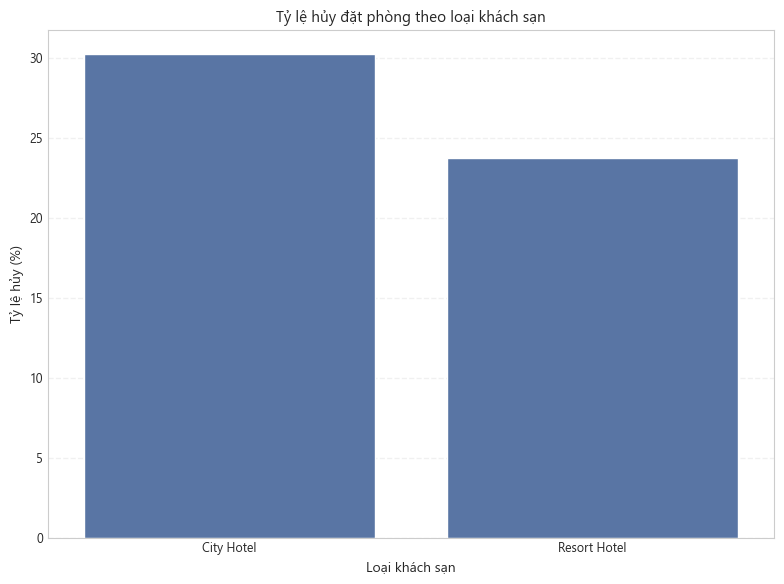

In [193]:
# -------------------------
# 7.8. Biểu đồ tỷ lệ hủy
# -------------------------

cancel_plot = pd.DataFrame({
    "hotel": cancellation_rate.index,
    "cancellation_rate": cancellation_rate[1].values
})

plt.figure(figsize=(8, 6))

sns.barplot(
    data=cancel_plot,
    x="hotel",
    y="cancellation_rate"
)

plt.title("Tỷ lệ hủy đặt phòng theo loại khách sạn")
plt.xlabel("Loại khách sạn")
plt.ylabel("Tỷ lệ hủy (%)")

plt.tight_layout()

plt.savefig(
    HYPOTHESIS_FIGURE_DIR / "chi_square_cancellation_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# =========================

## 4.24 One-way ANOVA

ANOVA so sánh ADR trung bình giữa nhiều nhóm market_segment. H0: các trung bình bằng nhau; H1: có ít nhất một trung bình khác biệt. Levene’s Test hỗ trợ lựa chọn One-way ANOVA hoặc Welch’s ANOVA theo logic hiện có.


In [194]:
# =========================
# 8. One-way ANOVA
# ADR giữa các market_segment
# =========================

print("\n" + "=" * 60)
print("ANOVA: ADR GIỮA CÁC MARKET SEGMENT")
print("\nGiả thuyết:")
print("H0: ADR trung bình của tất cả market segment bằng nhau.")
print("H1: Có ít nhất một market segment có ADR trung bình khác.")
print("=" * 60)

# -------------------------


ANOVA: ADR GIỮA CÁC MARKET SEGMENT

Giả thuyết:
H0: ADR trung bình của tất cả market segment bằng nhau.
H1: Có ít nhất một market segment có ADR trung bình khác.


## 4.25 Chuẩn bị dữ liệu

Chuẩn bị các nhóm market_segment theo quy tắc trong mã gốc: chỉ giữ nhóm có ít nhất 30 quan sát. Quy tắc này được giữ nguyên để nhất quán với phân tích hiện tại.


In [195]:
# -------------------------
# 8.1. Chuẩn bị dữ liệu
# Loại các nhóm có kích thước mẫu < 30
# -------------------------
segment_counts = df["market_segment"].value_counts()

print("\nSố lượng ban đầu theo market_segment:")
print(segment_counts)

valid_segments = segment_counts[
    segment_counts >= 30
].index

excluded_segments = segment_counts[
    segment_counts < 30
]

print("\nCác nhóm bị loại vì kích thước mẫu < 30:")
print(excluded_segments)

anova_data = df[
    df["market_segment"].isin(valid_segments)
].copy()

print("\nSố lượng theo market_segment:")
print(anova_data["market_segment"].value_counts())

# -------------------------


Số lượng ban đầu theo market_segment:
market_segment
Online TA        51285
Offline TA/TO    13748
Direct           11652
Groups            4891
Corporate         4151
Complementary      682
Aviation           222
Undefined            2
Name: count, dtype: int64

Các nhóm bị loại vì kích thước mẫu < 30:
market_segment
Undefined    2
Name: count, dtype: int64

Số lượng theo market_segment:
market_segment
Online TA        51285
Offline TA/TO    13748
Direct           11652
Groups            4891
Corporate         4151
Complementary      682
Aviation           222
Name: count, dtype: int64


## 4.26 Thống kê mô tả theo nhóm

Tóm tắt kích thước mẫu, trung bình và độ lệch chuẩn của các nhóm để hỗ trợ diễn giải kết quả kiểm định.


In [196]:
# -------------------------
# 8.2. Thống kê mô tả theo nhóm
# -------------------------

anova_summary = (
    anova_data
    .groupby("market_segment")["adr"]
    .agg(["count", "mean", "std", "median"])
    .sort_values("mean", ascending=False)
)

print("\nThống kê mô tả ADR theo market_segment:")
display(anova_summary)

# -------------------------


Thống kê mô tả ADR theo market_segment:


,count,mean,std,median
market_segment,,,,
Online TA,51285,118.867326,48.730621,111.00
Direct,11652,117.950508,58.641956,108.00
Aviation,222,102.426486,14.696349,95.00
Offline TA/TO,13748,82.176687,35.767993,79.85
Groups,4891,75.611893,37.434772,68.00
Corporate,4151,69.072298,31.660254,65.00
Complementary,682,3.138666,14.624840,0.00


## 4.27 Tạo các nhóm ADR

Thực hiện bước tương ứng trong quy trình kiểm định giả thuyết. Giữ nguyên phương pháp và logic phân tích của file Python gốc.


In [197]:
# -------------------------
# 8.3. Tạo các nhóm ADR
# -------------------------

groups = [
    group["adr"].dropna().values
    for _, group in anova_data.groupby("market_segment")
]

# -------------------------

## 4.28 Levene's Test

Levene’s Test kiểm tra giả định đồng nhất phương sai. Kết quả được dùng để chọn phiên bản kiểm định phù hợp theo logic trong mã gốc.


In [198]:
# -------------------------
# 8.4. Levene's Test
# Kiểm tra đồng nhất phương sai
# -------------------------

levene_stat_anova, levene_p_anova = stats.levene(
    *groups
)

print("\nLevene's Test:")
print(f"Statistic = {levene_stat_anova:.4f}")

if levene_p_anova < 0.001:
    print("p-value   < 0.001")
else:
    print(f"p-value   = {levene_p_anova:.6f}")

# -------------------------


Levene's Test:
Statistic = 773.2779
p-value   < 0.001


## 4.29 Chọn ANOVA phù hợp dựa trên Levene's Test

Levene’s Test kiểm tra giả định đồng nhất phương sai. Kết quả được dùng để chọn phiên bản kiểm định phù hợp theo logic trong mã gốc.


In [199]:
# -------------------------
# 8.5. Chọn ANOVA phù hợp dựa trên Levene's Test
# -------------------------

if levene_p_anova >= ALPHA:

    print("\nPhương sai giữa các nhóm không khác biệt có ý nghĩa.")
    print("Sử dụng One-way ANOVA.")

    f_stat, p_value_anova = stats.f_oneway(
        *groups
    )

    anova_method = "One-way ANOVA"

else:

    print("\nPhương sai giữa các nhóm khác biệt có ý nghĩa.")
    print("Sử dụng Welch's ANOVA.")


    welch_result = anova_oneway(
        groups,
        use_var="unequal",
        welch_correction=True
    )

    f_stat = welch_result.statistic
    p_value_anova = welch_result.pvalue

    anova_method = "Welch's ANOVA"


print(f"\nPhương pháp sử dụng: {anova_method}")
print(f"F-statistic = {f_stat:.4f}")

if p_value_anova < 0.001:
    print("p-value     < 0.001")
else:
    print(f"p-value     = {p_value_anova:.6f}")

# -------------------------


Phương sai giữa các nhóm khác biệt có ý nghĩa.
Sử dụng Welch's ANOVA.

Phương pháp sử dụng: Welch's ANOVA
F-statistic = 7808.9704
p-value     < 0.001


## 4.30 Kết luận kiểm định ANOVA

Kết luận dựa trên p-value và mức ý nghĩa α = 0,05. Nếu p-value nhỏ hơn α, bác bỏ giả thuyết không.


In [200]:
# -------------------------
# 8.6. Kết luận
# -------------------------
if p_value_anova < ALPHA:
    anova_conclusion = (
        "Bác bỏ H0. Có ít nhất một market segment "
        "có ADR trung bình khác biệt có ý nghĩa thống kê."
    )
else:
    anova_conclusion = (
        "Chưa đủ bằng chứng để bác bỏ H0. "
        "Chưa phát hiện sự khác biệt có ý nghĩa thống kê "
        "về ADR trung bình giữa các market segment."
    )

print("\nKết luận:")
print(anova_conclusion)

# -------------------------


Kết luận:
Bác bỏ H0. Có ít nhất một market segment có ADR trung bình khác biệt có ý nghĩa thống kê.


## 4.31 Post-hoc Test

Nếu kiểm định tổng thể có ý nghĩa thống kê, kiểm định hậu nghiệm xác định cặp nhóm nào khác biệt. Mã dùng Games–Howell khi phương sai không đồng nhất và Tukey HSD khi đồng nhất phương sai được chấp nhận.


In [201]:
# -------------------------
# 8.7. Post-hoc Test
# Games-Howell nếu phương sai không đồng nhất
# Tukey HSD nếu phương sai đồng nhất
# -------------------------
if p_value_anova < ALPHA:
    if levene_p_anova < ALPHA:
        posthoc = pg.pairwise_gameshowell(
            data=anova_data,
            dv="adr",
            between="market_segment"
        )
        posthoc_name = "games_howell_results.csv"
        posthoc_method = "Games-Howell"
    else:
        posthoc = pg.pairwise_tukey(
            data=anova_data,
            dv="adr",
            between="market_segment"
        )
        posthoc_name = "tukey_results.csv"
        posthoc_method = "Tukey HSD"

    print(f"\n{posthoc_method} Post-hoc Test:")
    display(posthoc)

    posthoc.to_csv(
        os.path.join(HYPOTHESIS_TABLE_DIR, posthoc_name),
        index=False,
        encoding="utf-8-sig"
    )

# -------------------------


Games-Howell Post-hoc Test:


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,Aviation,Complementary,102.426486,3.138666,99.287821,1.134245,87.536520,373.838107,0.000000e+00,6.775207
1,Aviation,Corporate,102.426486,69.072298,33.354188,1.101986,30.267356,343.195429,0.000000e+00,1.074856
2,Aviation,Direct,102.426486,117.950508,-15.524022,1.126067,-13.786054,374.765825,0.000000e+00,-0.267049
3,Aviation,Groups,102.426486,75.611893,26.814593,1.122236,23.893900,368.891003,0.000000e+00,0.729665
4,Aviation,Offline TA/TO,102.426486,82.176687,20.249800,1.032450,19.613355,265.260059,1.485478e-13,0.569872
5,Aviation,Online TA,102.426486,118.867326,-16.440839,1.009554,-16.285257,242.534553,0.000000e+00,-0.338037
6,Complementary,Corporate,3.138666,69.072298,-65.933633,0.745046,-88.496106,1944.296298,0.000000e+00,-2.208240
7,Complementary,Direct,3.138666,117.950508,-114.811842,0.780223,-147.152610,2439.541752,0.000000e+00,-2.010477
8,Complementary,Groups,3.138666,75.611893,-72.473228,0.774683,-93.552065,2234.042677,6.730172e-13,-2.044508
9,Complementary,Offline TA/TO,3.138666,82.176687,-79.038021,0.637709,-123.940559,1140.122980,1.482148e-13,-2.254379


## 4.32 Eta-squared

Eta-squared ước lượng tỷ lệ biến thiên ADR được giải thích bởi sự khác biệt giữa các nhóm market_segment.


In [202]:
# -------------------------
# 8.8. Eta-squared
# -------------------------
grand_mean = anova_data["adr"].mean()

ss_between = sum(
    len(group) * (group["adr"].mean() - grand_mean) ** 2
    for _, group in anova_data.groupby("market_segment")
)

ss_total = (
    (anova_data["adr"] - grand_mean) ** 2
).sum()

eta_squared = ss_between / ss_total

if eta_squared < 0.01:
    eta_level = "rất nhỏ"
elif eta_squared < 0.06:
    eta_level = "nhỏ"
elif eta_squared < 0.14:
    eta_level = "trung bình"
else:
    eta_level = "lớn"

print(
    f"\nEta-squared = {eta_squared:.4f} "
    f"({eta_level})"
)

# -------------------------


Eta-squared = 0.1560 (lớn)


## 4.33 Biểu đồ

Bảng/biểu đồ giúp quan sát trực quan tỷ lệ hủy hoặc phân bố ADR giữa các nhóm. Biểu đồ được lưu và hiển thị ngay bên dưới ô code.


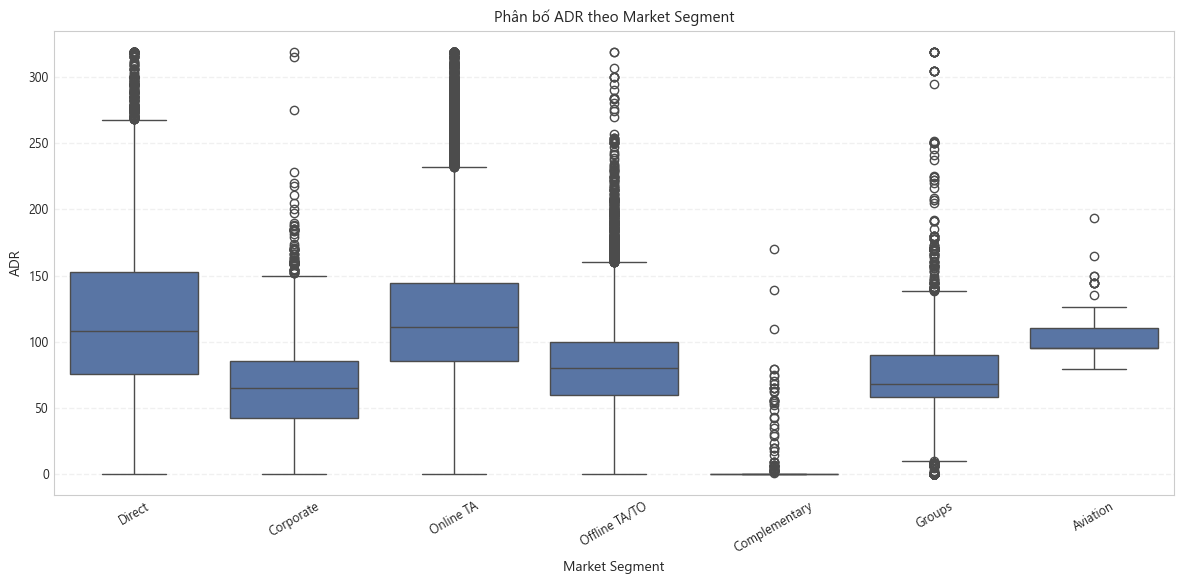

In [203]:
# -------------------------
# 8.9. Biểu đồ
# -------------------------
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=anova_data,
    x="market_segment",
    y="adr"
)

plt.title("Phân bố ADR theo Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("ADR")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    HYPOTHESIS_FIGURE_DIR / "anova_adr_by_market_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# -------------------------

## 4.34 Lưu kết quả

Lưu các thống kê và kết luận thành tệp CSV để sử dụng nhất quán trong báo cáo.


In [204]:
# -------------------------
# 8.10. Lưu kết quả
# -------------------------
anova_result = pd.DataFrame({
    "test": [anova_method],
    "f_statistic": [f_stat],
    "p_value": [p_value_anova],
    "levene_statistic": [levene_stat_anova],
    "levene_p_value": [levene_p_anova],
    "eta_squared": [eta_squared],
    "effect_size_level": [eta_level],
    "conclusion": [anova_conclusion]
})

anova_result.to_csv(
    os.path.join(
        HYPOTHESIS_TABLE_DIR,
        "anova_results.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

anova_summary.to_csv(
    os.path.join(
        HYPOTHESIS_TABLE_DIR,
        "anova_descriptive_statistics.csv"
    ),
    encoding="utf-8-sig"
)

## 4.35 Hướng dẫn đọc kết quả

- So sánh **p-value** với α = 0,05 để đưa ra quyết định thống kê.
- Với t-test và ANOVA, xem thêm độ lớn hiệu ứng (`Cohen’s d`, `Eta-squared`) thay vì chỉ dựa vào p-value.
- Với Chi-square, đọc bảng chéo, tần số kỳ vọng, tỷ lệ hủy và `Cramer’s V` cùng nhau.
- Các kết quả số cụ thể sẽ được tạo khi chạy notebook với đúng file `data/processed/hotel_bookings_cleaned.csv`; notebook không điền trước các kết quả chưa được chạy.


# 5. Phân tích tương quan



In [205]:

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")

## 5.1 Đọc dữ liệu đã làm sạch

Dùng lại đường dẫn chung đã khai báo ở đầu notebook. Các bảng và biểu đồ tương quan được lưu trong thư mục kết quả tương ứng.


In [206]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")

df = pd.read_csv(CLEANED_PATH)
print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách các cột:")
print(df.columns.tolist())


Kích thước dữ liệu: (86633, 38)

Danh sách các cột:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'agent_was_missing', 'children_was_missing', 'country_was_missing', 'has_company', 'total_guests', 'total_nights', 'arrival_date']


## 5.2 Lựa chọn các biến số

**Mục đích:** Tập trung phân tích những biến số có ý nghĩa với đặt phòng, thời gian lưu trú, khách, yêu cầu đặc biệt, giá phòng và trạng thái hủy.

**Lý do thực hiện:** Ma trận tương quan chỉ có ý nghĩa khi các biến đầu vào phù hợp với mục tiêu phân tích. Danh sách bên dưới giữ nguyên nhóm biến đã chọn trong mã phân tích ban đầu. Những cột không có trong tệp dữ liệu sẽ được bỏ qua để tránh lỗi.


In [207]:
numeric_cols = [
    "lead_time",
    "arrival_date_week_number",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "total_guests",
    "total_nights",
]

# Thêm trạng thái hủy nếu có trong dữ liệu.
if "is_canceled" in df.columns:
    numeric_cols.append("is_canceled")

numeric_cols = [col for col in numeric_cols if col in df.columns]
numeric_df = df[numeric_cols].copy()

print(f"Số biến được chọn: {len(numeric_cols)}")
print(numeric_cols)


Số biến được chọn: 17
['lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'booking_changes', 'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_canceled']


## 5.3 Kiểm tra giá trị thiếu

**Mục đích:** Xác định số lượng giá trị thiếu trong từng biến trước khi tính tương quan.

**Lý thuyết:** `isnull().sum()` đếm số ô thiếu theo từng cột. Phương pháp tương quan của pandas sẽ tính toán dựa trên các cặp quan sát hợp lệ; vì vậy cần biết tình trạng dữ liệu thiếu để diễn giải kết quả thận trọng.


In [208]:
print("\n" + "=" * 60)
print("MISSING VALUES IN NUMERIC VARIABLES")
print("=" * 60)
print(numeric_df.isnull().sum())


MISSING VALUES IN NUMERIC VARIABLES
lead_time                         0
arrival_date_week_number          0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
booking_changes                   0
previous_cancellations            0
previous_bookings_not_canceled    0
days_in_waiting_list              0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
total_guests                      0
total_nights                      0
is_canceled                       0
dtype: int64


## 5.4 Tính ma trận tương quan Pearson và Spearman

**Mục đích:** Đo lường mức độ và chiều hướng liên hệ giữa từng cặp biến số bằng hai phương pháp bổ sung cho nhau.

**Lý thuyết:**
- **Pearson (ρ):** đo mức độ liên hệ tuyến tính giữa hai biến số.
- **Spearman (ρ hoặc rₛ):** tính tương quan trên thứ hạng, phù hợp để khảo sát mối quan hệ đơn điệu và ít phụ thuộc hơn vào giả định tuyến tính.

**Lý do dùng cả hai:** So sánh hai hệ số giúp nhận biết liệu mức độ liên hệ có thể khác nhau khi xét giá trị gốc và thứ hạng. Hệ số nằm trong khoảng −1 đến +1; dấu thể hiện chiều hướng, trị tuyệt đối thể hiện độ mạnh tương đối.


In [209]:
# 5. PEARSON & SPEARMAN CORRELATION MATRIX
pearson_corr = numeric_df.corr(method='pearson')
spearman_corr = numeric_df.corr(method='spearman')

# LƯU MA TRẬN RA FILE CSV
pearson_corr.to_csv(CORRELATION_TABLE_DIR / "pearson_correlation.csv")
spearman_corr.to_csv(CORRELATION_TABLE_DIR / "spearman_correlation.csv")
print("\nĐã lưu ma trận Pearson và Spearman vào thư mục results/tables/")


Đã lưu ma trận Pearson và Spearman vào thư mục results/tables/


## 5.5 Trực quan hóa ma trận Pearson

**Mục đích:** Quan sát nhanh chiều hướng và mức độ tương quan của toàn bộ cặp biến.

**Cách đọc biểu đồ:** Mỗi ô biểu thị hệ số Pearson của một cặp biến. Giá trị gần +1 thể hiện liên hệ tuyến tính dương mạnh; gần −1 thể hiện liên hệ tuyến tính âm mạnh; gần 0 thể hiện liên hệ tuyến tính yếu. Màu sắc hỗ trợ so sánh, còn số trong ô cung cấp giá trị cụ thể.


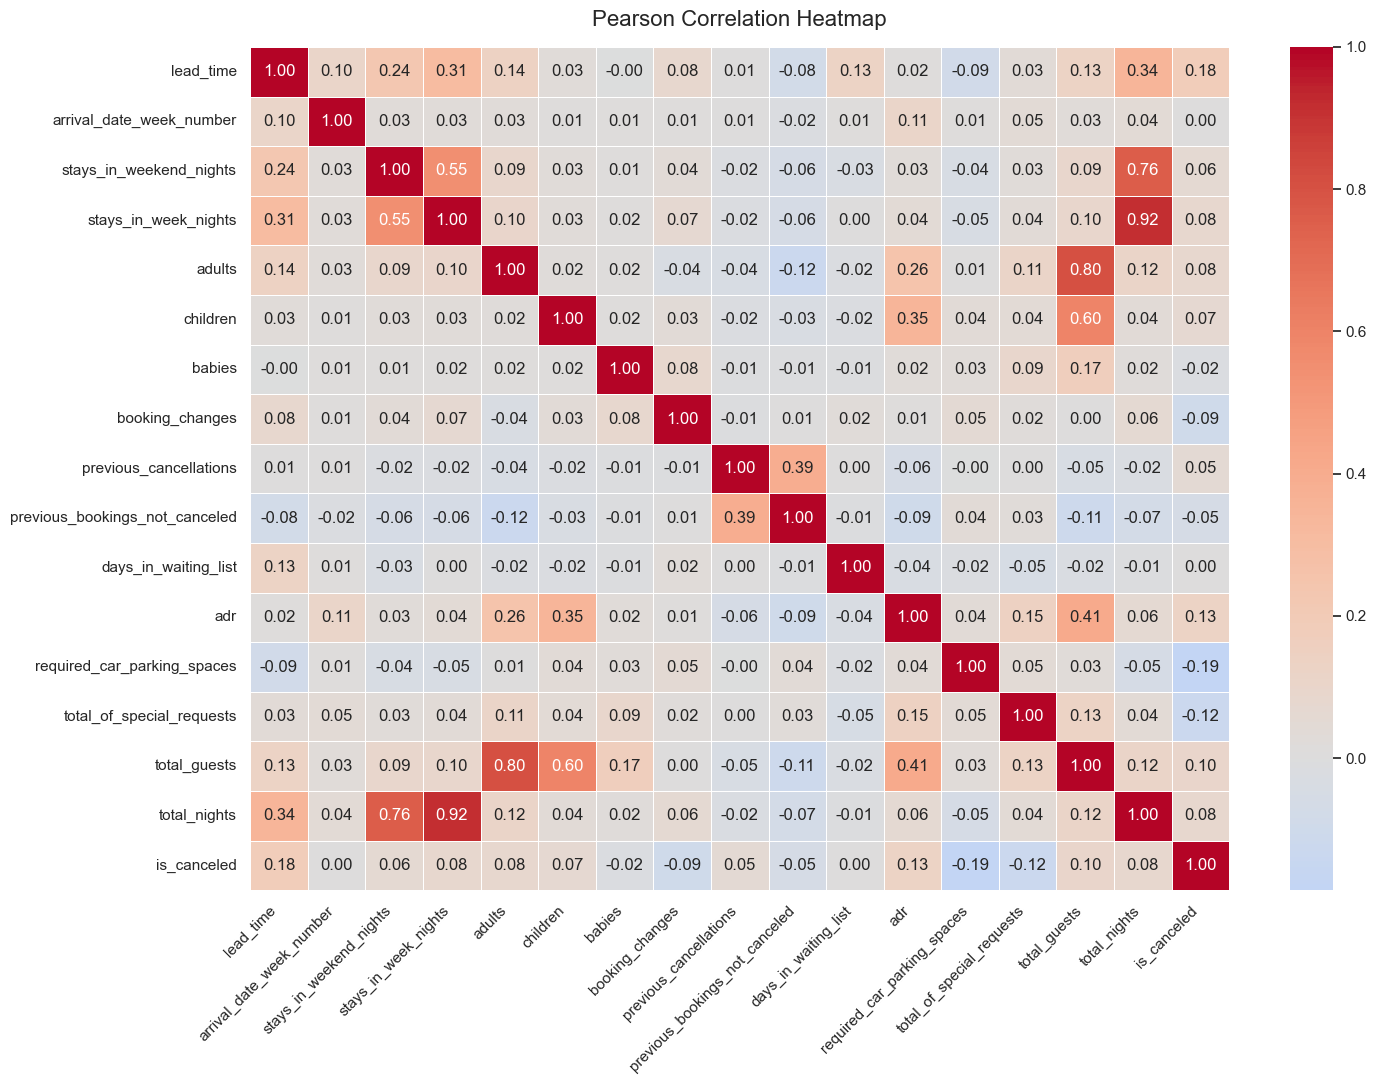

In [210]:
# 7. PEARSON HEATMAP
plt.figure(figsize=(15, 11))
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Pearson Correlation Heatmap", fontsize=16, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(CORRELATION_FIGURE_DIR / "pearson_heatmap.png", dpi=300)
plt.show()

## 5.6 Trực quan hóa ma trận Spearman

**Mục đích:** Đối chiếu ma trận Spearman với Pearson để xem mối liên hệ theo thứ hạng có thể hiện khác biệt hay không.

**Nhận xét khi đọc:** Nếu hai ma trận có giá trị tương tự, mối liên hệ có thể tương đối nhất quán giữa cách đo tuyến tính và cách đo theo thứ hạng. Nếu khác biệt đáng kể, cần xem xét hình dạng mối quan hệ và các giá trị ngoại lệ trước khi kết luận.


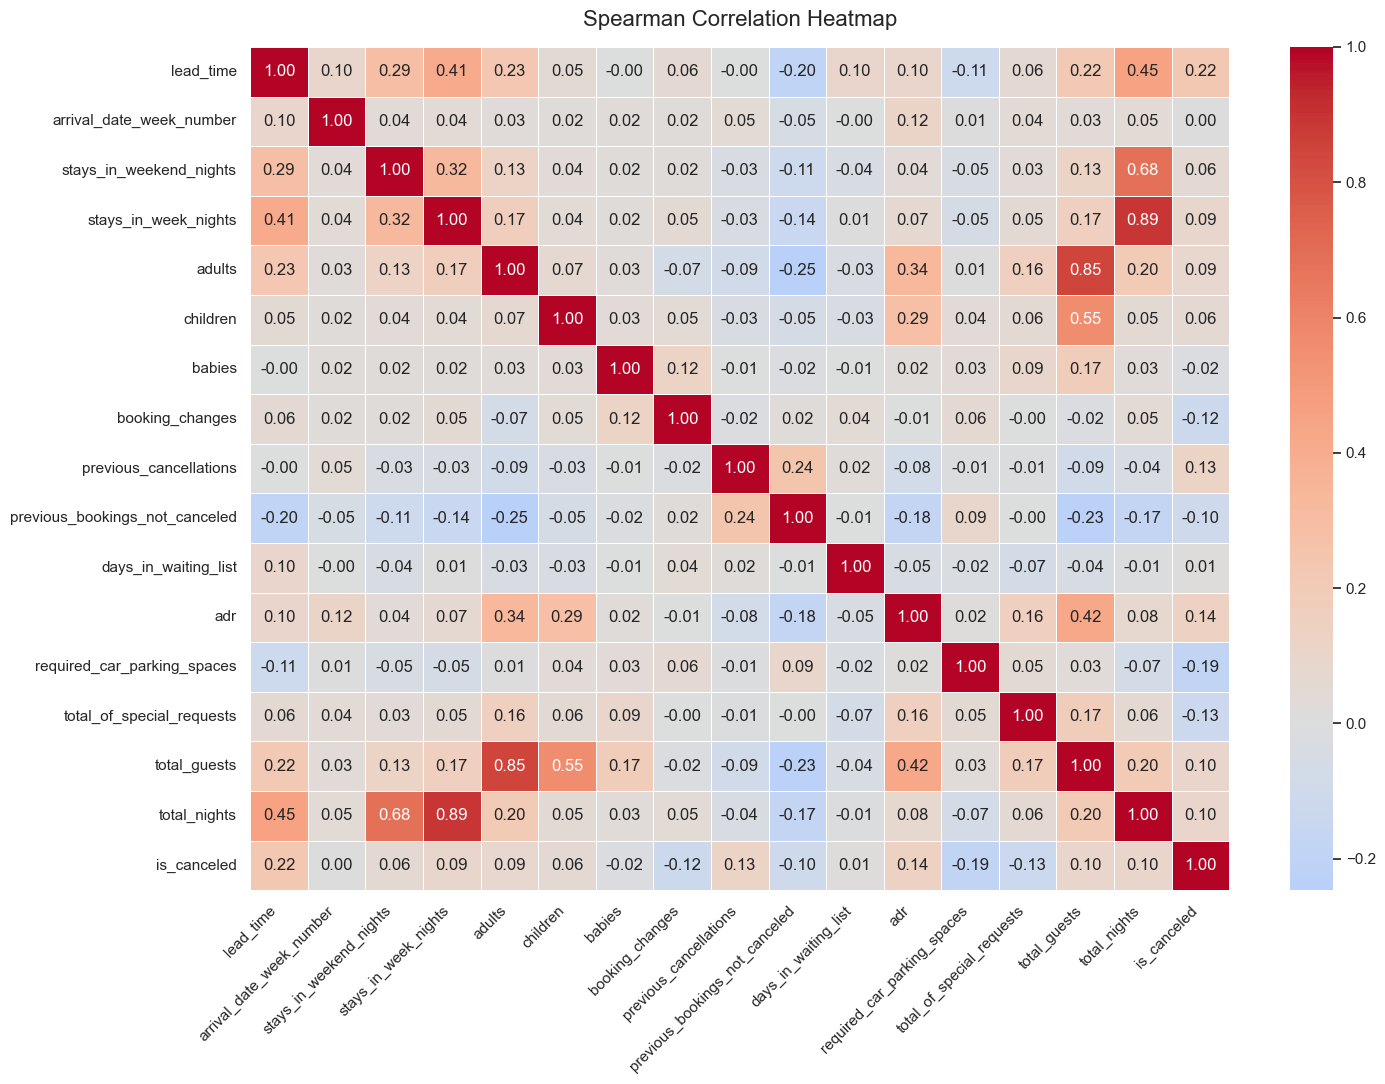

In [211]:
plt.figure(figsize=(15, 11))
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Spearman Correlation Heatmap", fontsize=16, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(CORRELATION_FIGURE_DIR / "spearman_heatmap.png", dpi=300)
plt.show()

## 5.7 Xác định 15 cặp biến có tương quan Pearson nổi bật nhất

**Mục đích:** Tóm tắt các cặp có trị tuyệt đối hệ số Pearson lớn nhất để thuận tiện kiểm tra và thảo luận.

**Cách thực hiện:** Chỉ lấy tam giác trên của ma trận nhằm tránh liệt kê trùng cặp (A, B) và (B, A), loại đường chéo tự tương quan, rồi sắp xếp theo trị tuyệt đối của hệ số. Đây là xếp hạng theo độ lớn, không phải kiểm định ý nghĩa thống kê.


In [212]:
upper_triangle = pearson_corr.where(
    np.triu(np.ones(pearson_corr.shape), k=1).astype(bool)
)

correlation_pairs = upper_triangle.stack().reset_index()
correlation_pairs.columns = ['Variable_1', 'Variable_2', 'Pearson_Correlation']
correlation_pairs['Absolute_Correlation'] = correlation_pairs['Pearson_Correlation'].abs()
correlation_pairs = correlation_pairs.sort_values(by='Absolute_Correlation', ascending=False)

# LƯU TOP 15 CẶP TƯƠNG QUAN RA CSV
top_pairs_df = correlation_pairs[['Variable_1', 'Variable_2', 'Pearson_Correlation']].head(15).round(3)
top_pairs_df.to_csv(CORRELATION_TABLE_DIR / "top_correlation_pairs.csv", index=False)

print("\n" + "=" * 60)
print("TOP 15 CORRELATION PAIRS (PEARSON)")
print("=" * 60)
print(top_pairs_df)


TOP 15 CORRELATION PAIRS (PEARSON)
                      Variable_1                      Variable_2  Pearson_Correlation
56          stays_in_week_nights                    total_nights                0.918
67                        adults                    total_guests                0.802
43       stays_in_weekend_nights                    total_nights                0.761
78                      children                    total_guests                0.597
31       stays_in_weekend_nights            stays_in_week_nights                0.547
123                          adr                    total_guests                0.407
100       previous_cancellations  previous_bookings_not_canceled                0.392
75                      children                             adr                0.349
14                     lead_time                    total_nights                0.344
2                      lead_time            stays_in_week_nights                0.312
64                

## 5.8 Phân tích tương quan với trạng thái hủy phòng

**Mục đích:** Khảo sát những biến số có mối liên hệ tương đối nổi bật với `is_canceled` (nếu cột này tồn tại).

**Lý thuyết và cách đọc:** Hệ số dương biểu thị xu hướng hai biến tăng cùng chiều; hệ số âm biểu thị xu hướng ngược chiều. Hệ số gần 0 thể hiện mối liên hệ tuyến tính hoặc đơn điệu yếu tùy phương pháp. Không diễn giải tương quan thành nguyên nhân gây hủy phòng.



TƯƠNG QUAN VỚI TRẠNG THÁI HỦY PHÒNG (is_canceled)

Pearson và Spearman với is_canceled:
                                Pearson  Spearman
required_car_parking_spaces      -0.186    -0.188
lead_time                         0.184     0.225
adr                               0.128     0.137
total_of_special_requests        -0.122    -0.129
total_guests                      0.099     0.101
booking_changes                  -0.094    -0.124
total_nights                      0.082     0.099
stays_in_week_nights              0.080     0.091
adults                            0.080     0.089
children                          0.067     0.061
stays_in_weekend_nights           0.058     0.056
previous_bookings_not_canceled   -0.052    -0.104
previous_cancellations            0.051     0.127
babies                           -0.021    -0.021
days_in_waiting_list              0.005     0.015
arrival_date_week_number          0.003     0.002


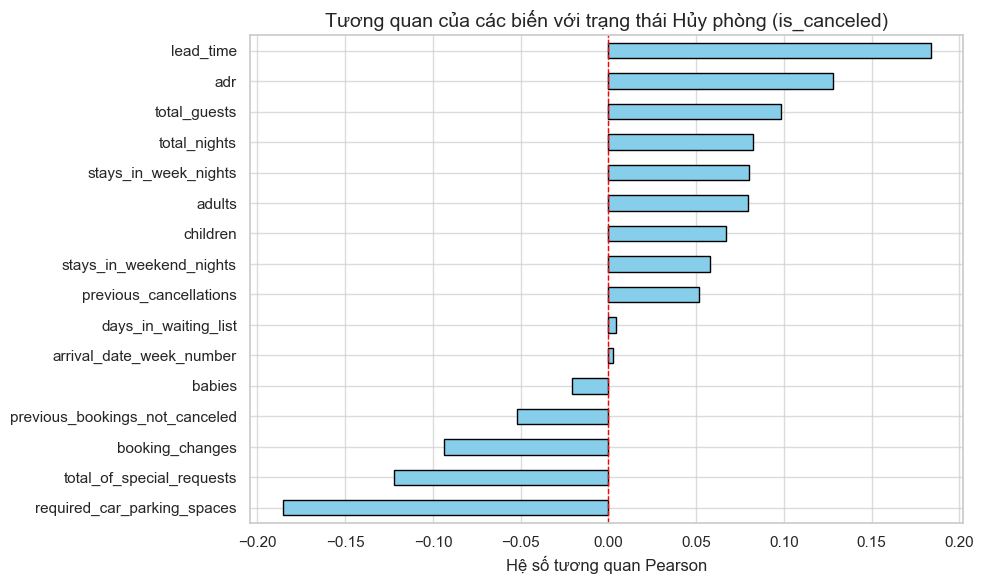

In [213]:
if 'is_canceled' in numeric_df.columns:
    print("\n" + "=" * 60)
    print("TƯƠNG QUAN VỚI TRẠNG THÁI HỦY PHÒNG (is_canceled)")
    print("=" * 60)

    cancel_pearson = numeric_df.corr(method='pearson')['is_canceled'].drop('is_canceled')
    cancel_spearman = numeric_df.corr(method='spearman')['is_canceled'].drop('is_canceled')

    cancel_corr = pd.DataFrame({
        'Pearson': cancel_pearson,
        'Spearman': cancel_spearman
    })

    cancel_corr['Abs_Pearson'] = cancel_corr['Pearson'].abs()
    cancel_corr = cancel_corr.sort_values(by='Abs_Pearson', ascending=False)

    # LƯU BẢNG TƯƠNG QUAN HỦY PHÒNG RA CSV
    cancel_corr[['Pearson', 'Spearman']].round(3).to_csv(CORRELATION_TABLE_DIR / "cancel_correlation.csv")

    print("\nPearson và Spearman với is_canceled:")
    print(cancel_corr[['Pearson', 'Spearman']].round(3))

    # Biểu đồ Barh hủy phòng
    plt.figure(figsize=(10, 6))
    cancel_corr['Pearson'].sort_values().plot(
        kind='barh',
        color='skyblue',
        edgecolor='black'
    )
    plt.title("Tương quan của các biến với trạng thái Hủy phòng (is_canceled)", fontsize=14)
    plt.xlabel("Hệ số tương quan Pearson")
    plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
    plt.tight_layout()
    plt.savefig(CORRELATION_FIGURE_DIR / "cancel_correlation_bar.png", dpi=300)
    plt.show()

## 5.9 Biểu đồ phân tán: thời gian đặt trước và tổng số đêm lưu trú

**Mục đích:** Quan sát phân bố dữ liệu và xu hướng giữa `lead_time` (số ngày từ lúc đặt đến ngày đến) và `total_nights` (tổng số đêm lưu trú).

**Lý do thực hiện:** Hệ số tương quan tóm tắt mối liên hệ bằng một con số, trong khi biểu đồ phân tán giúp nhận ra độ phân tán, cụm dữ liệu và điểm bất thường. Đường đỏ là đường xu hướng tuyến tính tham khảo, không chứng minh quan hệ nhân quả.


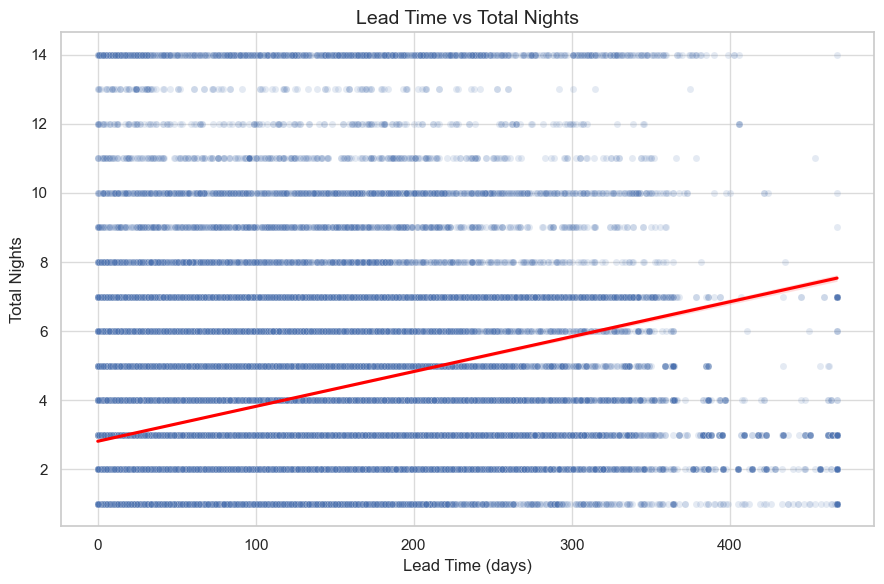

In [214]:
# Scatter Plot 1: Lead Time vs Total Nights
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='lead_time', y='total_nights', alpha=0.15, s=25)
sns.regplot(data=df, x='lead_time', y='total_nights', scatter=False, color='red')
plt.title("Lead Time vs Total Nights", fontsize=14)
plt.xlabel("Lead Time (days)")
plt.ylabel("Total Nights")
plt.tight_layout()
plt.savefig(CORRELATION_FIGURE_DIR / "scatter_lead_time_total_nights.png", dpi=300)
plt.show()

## 5.10 Biểu đồ phân tán: thời gian đặt trước và số đêm trong tuần

**Mục đích:** Khảo sát xu hướng giữa `lead_time` và `stays_in_week_nights`.

**Kết quả và nhận xét:** Dùng biểu đồ để xem các điểm dữ liệu phân bố như thế nào và đường xu hướng đi lên, đi xuống hay tương đối phẳng. Nhận xét cuối cùng cần dựa trên biểu đồ thực tế và hệ số tương quan đã tính, không suy diễn chỉ từ đường xu hướng.


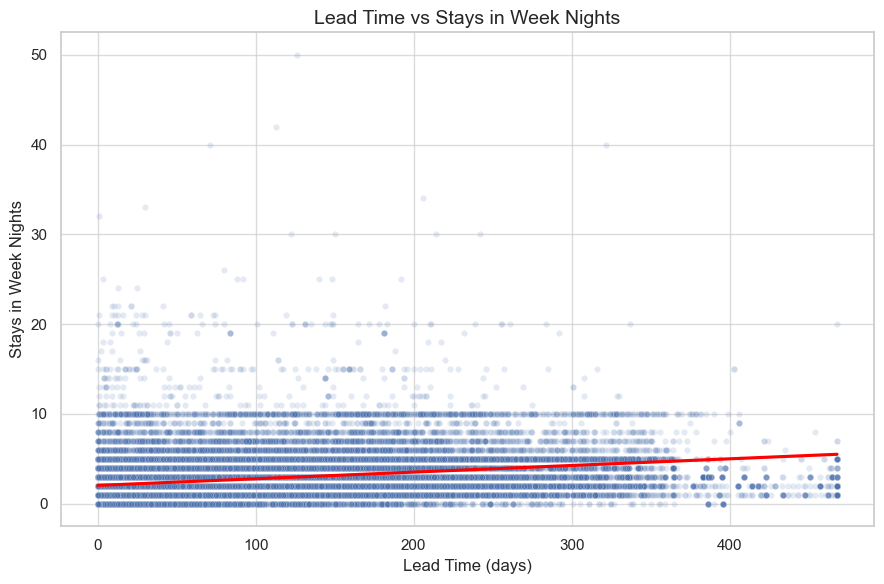

In [215]:
# Scatter Plot 2: Lead Time vs Stays in Week Nights
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='lead_time', y='stays_in_week_nights', alpha=0.15, s=20)
sns.regplot(data=df, x='lead_time', y='stays_in_week_nights', scatter=False, color='red')
plt.title("Lead Time vs Stays in Week Nights", fontsize=14)
plt.xlabel("Lead Time (days)")
plt.ylabel("Stays in Week Nights")
plt.tight_layout()
plt.savefig(CORRELATION_FIGURE_DIR / "scatter_lead_time_week_nights.png", dpi=300)
plt.show()

## 5.11 Xu hướng ADR trung bình theo tuần trong năm

**Mục đích:** Quan sát sự thay đổi của ADR trung bình theo `arrival_date_week_number` để khảo sát xu hướng theo mùa.

**Cách thực hiện:** Gom nhóm theo tuần đến và tính ADR trung bình của từng nhóm, sau đó biểu diễn bằng biểu đồ đường. Đây là mô tả theo tuần; biến động có thể chịu ảnh hưởng của cơ cấu đặt phòng và các yếu tố khác, nên không thể kết luận nguyên nhân chỉ từ biểu đồ.


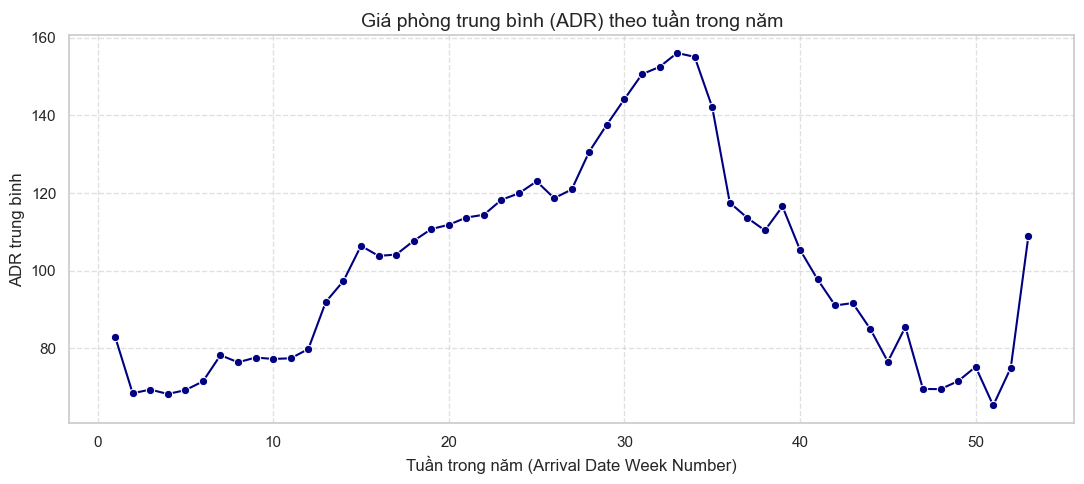

In [216]:
# Line Plot: Arrival Date Week Number vs ADR
plt.figure(figsize=(11, 5))
sns.lineplot(data=df, x='arrival_date_week_number', y='adr', estimator='mean', errorbar=None, color='navy', marker='o')
plt.title("Giá phòng trung bình (ADR) theo tuần trong năm", fontsize=14)
plt.xlabel("Tuần trong năm (Arrival Date Week Number)")
plt.ylabel("ADR trung bình")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(CORRELATION_FIGURE_DIR / "seasonality_adr_weekly.png", dpi=300)
plt.show()

## 5.12 Đánh giá mức độ tương quan của các cặp trọng yếu

**Mục đích:** In hệ số Pearson và Spearman của các cặp được nhóm xác định trước để so sánh mức độ, chiều hướng và cách đo tương quan.

**Quy ước mô tả:** Phân loại theo trị tuyệt đối của Pearson: dưới 0,10 là rất yếu; 0,10–dưới 0,30 là yếu; 0,30–dưới 0,50 là vừa; 0,50–dưới 0,70 là mạnh; từ 0,70 trở lên là rất mạnh. Đây là quy ước diễn giải tham khảo, không phải ngưỡng phổ quát hay kiểm định thống kê.


In [217]:
# 12. PHÂN TÍCH VÀ ĐÁNH GIÁ MỨC ĐỘ TƯƠNG QUAN CÁC CẶP TRỌNG YẾU
def correlation_strength(r):
    r_abs = abs(r)
    if r_abs < 0.10:
        return "Rất yếu"
    elif r_abs < 0.30:
        return "Yếu"
    elif r_abs < 0.50:
        return "Vừa"
    elif r_abs < 0.70:
        return "Mạnh"
    else:
        return "Rất mạnh"

important_pairs = [
    ('lead_time', 'total_nights'),
    ('arrival_date_week_number', 'adr'),
    ('lead_time', 'stays_in_week_nights')
]

print("\n" + "=" * 60)
print("ANALYSIS OF IMPORTANT CORRELATIONS")
print("=" * 60)

for var1, var2 in important_pairs:
    if var1 in pearson_corr.columns and var2 in pearson_corr.columns:
        p_val = pearson_corr.loc[var1, var2]
        s_val = spearman_corr.loc[var1, var2]
        strength = correlation_strength(p_val)
        direction = "dương" if p_val > 0 else ("âm" if p_val < 0 else "không có")
        
        print(f"\nCặp biến: {var1} <-> {var2}")
        print(f"  - Pearson  : {p_val:.3f}")
        print(f"  - Spearman : {s_val:.3f}")
        print(f"  - Đánh giá : Tương quan {direction}, mức độ {strength}")
        # Nhận xét ý nghĩa thực tiễn
        if abs(p_val) < 0.10:
            print("  - Ý nghĩa thực tiễn: Mối liên hệ rất yếu,")
            print("    do đó khó xem đây là một mối quan hệ đáng kể trong thực tế.")

        elif p_val > 0:
            print("  - Ý nghĩa thực tiễn: Hai biến có xu hướng thay đổi cùng chiều.")
            print("    Khi một biến tăng, biến còn lại có xu hướng tăng theo.")

        else:
            print("  - Ý nghĩa thực tiễn: Hai biến có xu hướng thay đổi ngược chiều.")
            print("    Khi một biến tăng, biến còn lại có xu hướng giảm.")


ANALYSIS OF IMPORTANT CORRELATIONS

Cặp biến: lead_time <-> total_nights
  - Pearson  : 0.344
  - Spearman : 0.455
  - Đánh giá : Tương quan dương, mức độ Vừa
  - Ý nghĩa thực tiễn: Hai biến có xu hướng thay đổi cùng chiều.
    Khi một biến tăng, biến còn lại có xu hướng tăng theo.

Cặp biến: arrival_date_week_number <-> adr
  - Pearson  : 0.110
  - Spearman : 0.118
  - Đánh giá : Tương quan dương, mức độ Yếu
  - Ý nghĩa thực tiễn: Hai biến có xu hướng thay đổi cùng chiều.
    Khi một biến tăng, biến còn lại có xu hướng tăng theo.

Cặp biến: lead_time <-> stays_in_week_nights
  - Pearson  : 0.312
  - Spearman : 0.414
  - Đánh giá : Tương quan dương, mức độ Vừa
  - Ý nghĩa thực tiễn: Hai biến có xu hướng thay đổi cùng chiều.
    Khi một biến tăng, biến còn lại có xu hướng tăng theo.


## 5.13 Lưu ý khi diễn giải kết quả

- `total_nights` được tạo từ `stays_in_weekend_nights + stays_in_week_nights`; do đó tương quan cao với các biến thành phần có thể xuất phát trực tiếp từ công thức tạo biến.
- `total_guests` được tính từ số lượng khách, nên có thể tương quan cao với `adults`, `children` và `babies`.
- Các mối tương quan cấu trúc vẫn hữu ích để kiểm tra tính nhất quán của dữ liệu, nhưng không nên xem là phát hiện độc lập.
- Pearson đo liên hệ tuyến tính; Spearman đo liên hệ dựa trên thứ hạng và mối quan hệ đơn điệu.
- Tương quan không chứng minh quan hệ nhân quả. Các hệ số trong notebook cũng không tự động thể hiện ý nghĩa thống kê.


# 6. Hồi quy tuyến tính đa biến



## 6.1 Đọc và kiểm tra dữ liệu

Kiểm tra kích thước và một số dòng đầu để xác nhận dữ liệu được nạp đúng. File đầu vào đã qua làm sạch chung nhưng chưa Capping riêng cho mô hình hồi quy.


In [218]:
if not PRE_CAPPING_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy {PRE_CAPPING_PATH}. Kiểm tra thư mục data/processed/.")
df = pd.read_csv(PRE_CAPPING_PATH)
print("Kích thước dữ liệu:", df.shape)
display(df.head())


Kích thước dữ liệu: (86633, 38)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,agent_was_missing,children_was_missing,country_was_missing,has_company,total_guests,total_nights,arrival_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,0,0,0,1,1,2015-07-01
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,0,0,0,1,1,2015-07-01
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,0,0,0,2,2,2015-07-01
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,0.0,0,Transient,107.0,0,0,Check-Out,2015-07-03,1,0,0,0,2,2,2015-07-01
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,0,Transient,103.0,0,1,Check-Out,2015-07-03,0,0,0,0,2,2,2015-07-01


## 6.2 Lựa chọn biến

Biến mục tiêu là `adr`, đại diện cho giá phòng trung bình mỗi ngày. Mô hình sử dụng **7 biến số** và **6 biến phân loại**. Biến phân loại sẽ được mã hóa thành dạng số ở bước tiền xử lý.


In [219]:
target = "adr"
numeric_features = ["lead_time", "adults", "children", "stays_in_weekend_nights", "stays_in_week_nights", "booking_changes", "total_of_special_requests"]
categorical_features = ["hotel", "arrival_date_month", "market_segment", "customer_type", "meal", "is_repeated_guest"]
features = numeric_features + categorical_features
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset thiếu các cột: {missing_columns}")
data = df[required_columns].copy()
for col in numeric_features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[target])
X, y = data[features].copy(), data[target].copy()
print("Kích thước dùng cho hồi quy:", data.shape)
print("Biến số:", len(numeric_features), "| Biến phân loại:", len(categorical_features))

Kích thước dùng cho hồi quy: (86633, 14)
Biến số: 7 | Biến phân loại: 6


## 6.3 Chia train/test

Dữ liệu được chia **80% train, 20% test**. Train dùng để tính ngưỡng Capping và huấn luyện; test được giữ riêng để đánh giá mô hình trên các mẫu chưa dùng để học. `random_state=42` giúp tái lập cách chia và hạn chế data leakage.


In [220]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()
display(pd.DataFrame({"Tập": ["Train", "Test"], "Số mẫu": [len(X_train), len(X_test)], "Tỷ lệ": [f"{len(X_train)/len(X):.1%}", f"{len(X_test)/len(X):.1%}"]}))

,Tập,Số mẫu,Tỷ lệ
0,Train,69306,80.0%
1,Test,17327,20.0%


## 6.4 Capping một số biến đầu vào

Capping giới hạn giá trị cực đoan thay vì xóa bản ghi. Áp dụng cho `lead_time`, `stays_in_weekend_nights` và `stays_in_week_nights`, theo ngưỡng **Q1 − 3×IQR** và **Q3 + 3×IQR**, trong đó IQR = Q3 − Q1. Ngưỡng chỉ tính trên train rồi áp dụng giống nhau cho train/test. Không Capping `adr` vì đây là biến mục tiêu.


In [221]:
cap_columns = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights"]
cap_bounds = {}
for col in cap_columns:
    q1, q3 = X_train[col].quantile(0.25), X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 3 * iqr, q3 + 3 * iqr
    cap_bounds[col] = (lower, upper)
    X_train.loc[:, col] = X_train[col].clip(lower=lower, upper=upper)
    X_test.loc[:, col] = X_test[col].clip(lower=lower, upper=upper)
cap_summary = pd.DataFrame([{"Biến": col, "Ngưỡng dưới": b[0], "Ngưỡng trên": b[1]} for col, b in cap_bounds.items()])
display(cap_summary.round(4))

,Biến,Ngưỡng dưới,Ngưỡng trên
0,lead_time,-327.0,464.0
1,stays_in_weekend_nights,-6.0,8.0
2,stays_in_week_nights,-8.0,13.0


### 6.5 Nhận xét về Capping

Các giá trị nằm ngoài ngưỡng được đưa về giới hạn gần nhất. Cách này giảm ảnh hưởng của một số giá trị cực đoan mà vẫn giữ lại bản ghi; tuy nhiên, Capping không đảm bảo dữ liệu trở thành phân phối chuẩn.


## 6.6 Pipeline tiền xử lý

- Biến số: điền giá trị thiếu bằng median, ít nhạy với ngoại lai hơn trung bình.
- Biến phân loại: điền giá trị thiếu bằng nhóm xuất hiện nhiều nhất, sau đó dùng **One-Hot Encoding** để tạo các cột nhị phân.
- `ColumnTransformer` kết hợp hai quy trình. Đặt các bước trong pipeline giúp tiền xử lý được khớp trên train và áp dụng nhất quán lên test.


In [222]:
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_features), ("cat", categorical_transformer, categorical_features)])
print("Đã tạo pipeline tiền xử lý.")

Đã tạo pipeline tiền xử lý.


## 6.7 Xây dựng và huấn luyện mô hình

Pipeline gồm bước tiền xử lý và `LinearRegression`. Mô hình học hệ số từ tập train, sau đó dự đoán ADR trên tập test để đánh giá khả năng áp dụng với dữ liệu chưa dùng để học.


In [223]:
model = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", LinearRegression())])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Huấn luyện hoàn tất. Train:", len(X_train), "| Test:", len(X_test))

Huấn luyện hoàn tất. Train: 69306 | Test: 17327


## 6.8 Đánh giá mô hình

- **R²:** mức độ mô hình giải thích biến thiên ADR trên tập test.
- **MAE:** sai số tuyệt đối trung bình giữa thực tế và dự đoán.
- **RMSE:** căn bậc hai của trung bình bình phương sai số; nhạy hơn với sai số lớn.

MAE và RMSE cùng đơn vị với ADR. Nên xem các chỉ số cùng nhau thay vì chỉ dựa vào một chỉ số.


In [224]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
n_encoded_features = len(feature_names)
metrics = pd.DataFrame({"Chỉ số": ["R²", "MAE", "RMSE", "Số đặc trưng sau mã hóa"], "Giá trị": [r2, mae, rmse, n_encoded_features]})
display(metrics.round(4))

,Chỉ số,Giá trị
0,R²,0.5451
1,MAE,25.0572
2,RMSE,34.2619
3,Số đặc trưng sau mã hóa,40.0000


### 6.9 Diễn giải kết quả

Theo báo cáo, mô hình đạt khoảng **R² = 0,5451**, **MAE = 25,06**, **RMSE = 34,26**. R² cho thấy mô hình giải thích khoảng 54,51% biến thiên ADR trên tập test. Sai số vẫn còn đáng kể; RMSE lớn hơn MAE cũng gợi ý một số trường hợp có sai số lớn. Hãy đối chiếu với kết quả khi chạy notebook để bảo đảm dùng cùng phiên bản dữ liệu/code.


## 6.10 Phân tích hệ số hồi quy

Hệ số dương/âm cho biết chiều của mối liên hệ mà mô hình ước lượng khi giữ các biến khác cố định. Với biến phân loại đã mã hóa, hệ số thể hiện chênh lệch so với nhóm tham chiếu. Hệ số lớn không nhất thiết đồng nghĩa biến quan trọng nhất vì các biến có thể khác thang đo; hệ số cũng không chứng minh quan hệ nhân quả.


In [225]:
regressor = model.named_steps["regressor"]
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": regressor.coef_})
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs_Coefficient", ascending=False)
print(f"Intercept: {regressor.intercept_:.6f}")
display(coef_df.drop(columns=["Abs_Coefficient"]).head(15).round(4))

Intercept: 55.273198


,Feature,Coefficient
28,cat__market_segment_Undefined,-111.0350
22,cat__market_segment_Complementary,-62.9398
27,cat__market_segment_Online TA,44.5910
24,cat__market_segment_Direct,43.6002
10,cat__arrival_date_month_August,42.6264
36,cat__meal_SC,-40.5090
21,cat__market_segment_Aviation,35.5103
14,cat__arrival_date_month_July,31.2975
13,cat__arrival_date_month_January,-30.5298
34,cat__meal_FB,29.6103


## 6.11 ADR thực tế và ADR dự đoán

Đường nét đứt là dự đoán hoàn hảo. Điểm càng gần đường này thì dự đoán càng sát; điểm càng xa thì sai số càng lớn. Nếu các điểm ở vùng ADR cao thường nằm dưới đường tham chiếu, mô hình có xu hướng dự đoán thấp ở vùng đó.


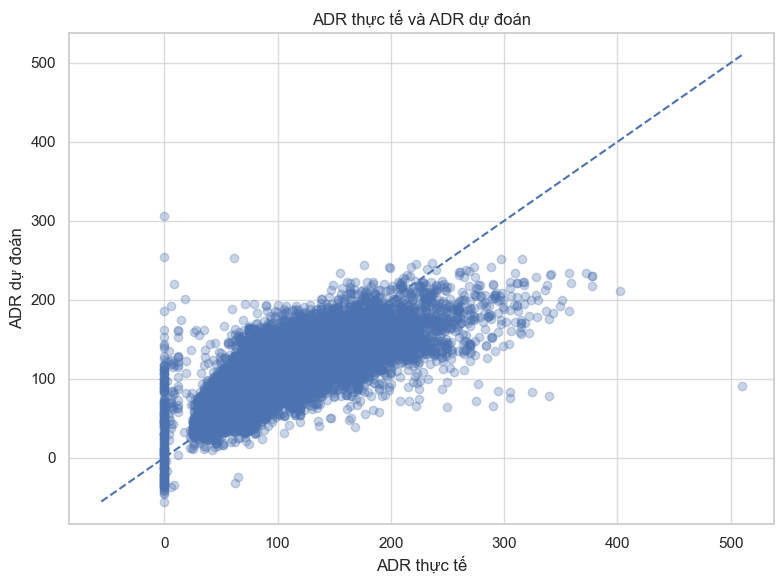

Đã lưu: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\regression\actual_vs_predicted.png


In [226]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
min_value = min(y_test.min(), np.min(y_pred))
max_value = max(y_test.max(), np.max(y_pred))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("ADR thực tế")
plt.ylabel("ADR dự đoán")
plt.title("ADR thực tế và ADR dự đoán")
plt.tight_layout()
actual_pred_path = REGRESSION_FIGURE_DIR / "actual_vs_predicted.png"
plt.savefig(actual_pred_path, dpi=300, bbox_inches="tight")
plt.show()
print("Đã lưu:", actual_pred_path)

## 6.12 Biểu đồ phần dư (Residual Plot)

Phần dư được tính bằng **thực tế − dự đoán**. Phần dư dương nghĩa là mô hình dự đoán thấp hơn thực tế; phần dư âm nghĩa là dự đoán cao hơn thực tế. Phần dư phân tán ngẫu nhiên quanh 0 thường là dấu hiệu phù hợp hơn; mẫu hình rõ hoặc độ phân tán thay đổi có thể cho thấy mô hình chưa mô tả hết cấu trúc dữ liệu.


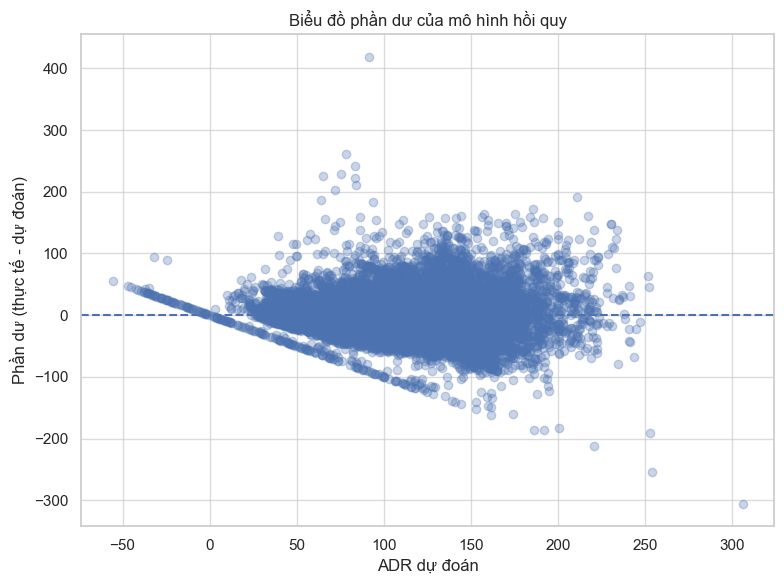

Đã lưu: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\regression\residual_plot.png


In [227]:
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")
plt.xlabel("ADR dự đoán")
plt.ylabel("Phần dư (thực tế - dự đoán)")
plt.title("Biểu đồ phần dư của mô hình hồi quy")
plt.tight_layout()
residual_path = REGRESSION_FIGURE_DIR / "residual_plot.png"
plt.savefig(residual_path, dpi=300, bbox_inches="tight")
plt.show()
print("Đã lưu:", residual_path)

## 6.13 Lưu kết quả

Notebook lưu các chỉ số đánh giá, hệ số hồi quy, giá trị thực tế/dự đoán, ngưỡng Capping và hai biểu đồ. Bảng nằm trong `results/tables/regression/`; hình nằm trong `results/figures/regression/`.


In [228]:
metrics.to_csv(REGRESSION_TABLE_DIR / "regression_metrics.csv", index=False, encoding="utf-8-sig")
coef_df.drop(columns=["Abs_Coefficient"]).to_csv(REGRESSION_TABLE_DIR / "regression_coefficients.csv", index=False, encoding="utf-8-sig")
predictions = pd.DataFrame({"Actual_ADR": y_test.to_numpy(), "Predicted_ADR": y_pred})
predictions.to_csv(REGRESSION_TABLE_DIR / "regression_predictions.csv", index=False, encoding="utf-8-sig")
cap_summary.to_csv(REGRESSION_TABLE_DIR / "regression_capping_bounds.csv", index=False, encoding="utf-8-sig")
print("Bảng kết quả:", REGRESSION_TABLE_DIR)
print("Biểu đồ:", REGRESSION_FIGURE_DIR)
print("Hoàn tất phân tích hồi quy đa biến.")

Bảng kết quả: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\regression
Biểu đồ: C:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\regression
Hoàn tất phân tích hồi quy đa biến.


## 6.14 Kết luận

Mô hình dự đoán ADR từ 13 biến đầu vào gồm biến số và biến phân loại. Quy trình gồm chia dữ liệu, Capping một số biến đầu vào dựa trên train, tiền xử lý, huấn luyện và đánh giá trên test. Các chỉ số cùng biểu đồ cho thấy mô hình giải thích được một phần biến thiên ADR nhưng vẫn còn sai số đáng kể. Vì vậy, nên xem đây là mô hình cơ sở để phân tích mối liên hệ giữa đặc điểm booking và ADR, không phải bằng chứng về quan hệ nhân quả.
